1. Estimating baseline employment trends and scale ratios from SUSB...
2. Simulating expansion of AI Exposure at occupation level...
3. Anchoring industry-average digital infrastructure index (Cloud & Software)...

IMPUTATION SUMMARY BY INDUSTRY (Cloud & Software)
 - Original: 277 industries

4. Executing final dynamic simulation...
Successfully loaded dynamic diffusion stats (d).
Mapping SUSB weights using hierarchical search for range codes (e.g., 44-45)...
SUSB weight hierarchical mapping complete.
Validated SUSB weight mapping complete.

Check Complete: All industries successfully matched with diffusion speed data.


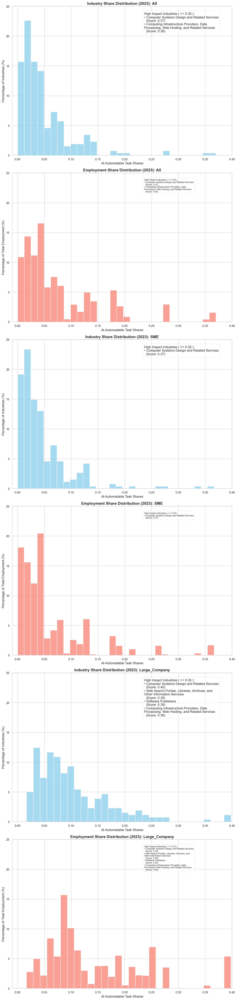

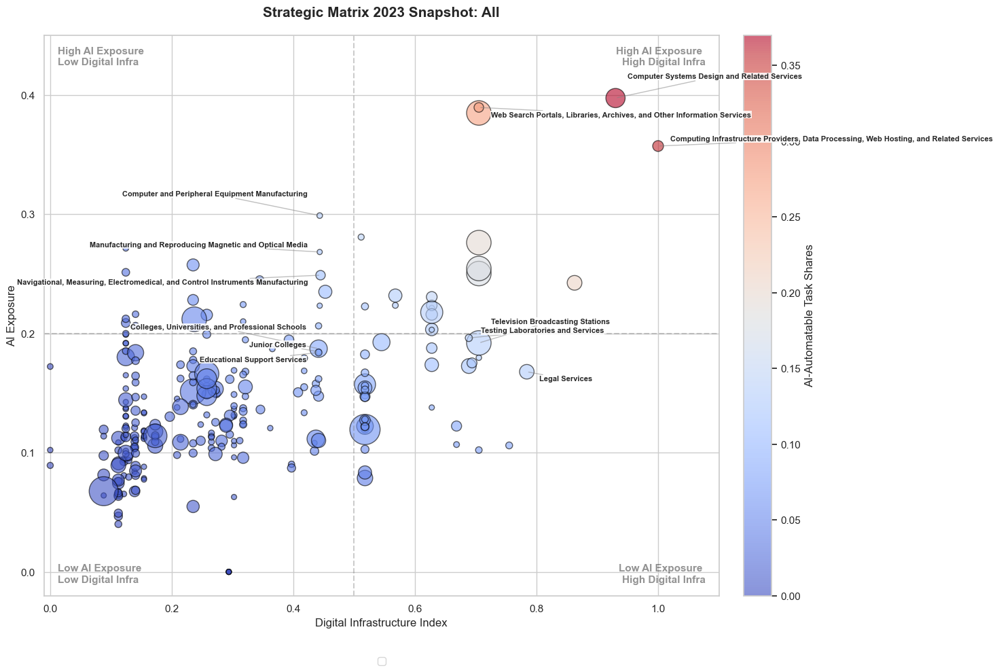

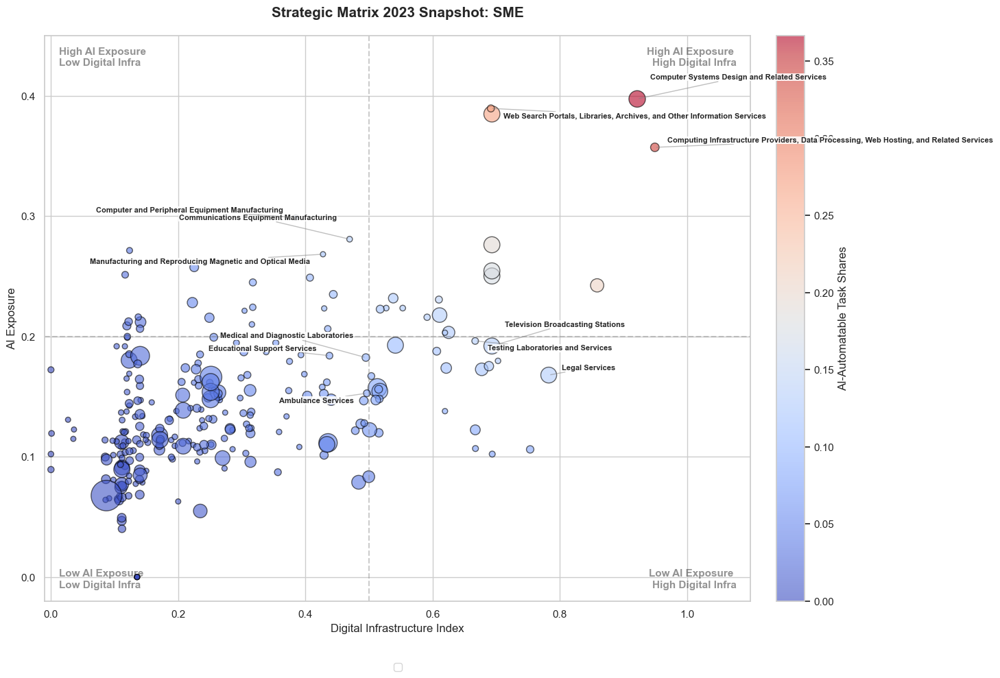

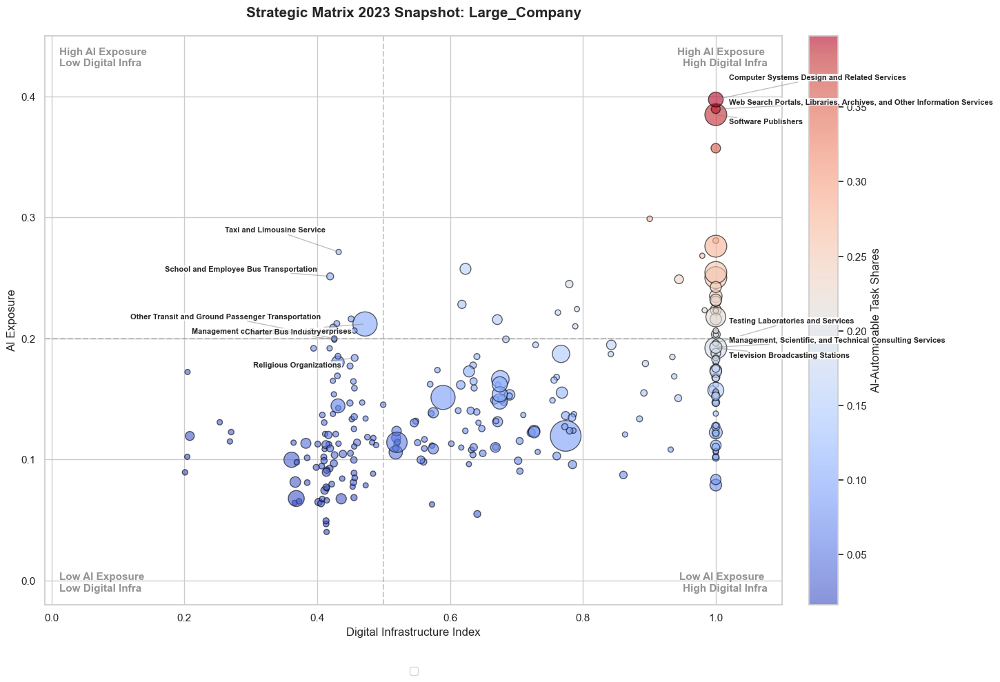


                      TOP 20 INDUSTRIES: HIGHEST AI-Automatable Task Shares (2025)                       
NAICS_TITLE                                                                      | AI-Automatable Task Shares
---------------------------------------------------------------------------------------------------------
Computer Systems Design and Related Services                                     |             0.502588
Computing Infrastructure Providers, Data Processing, Web Hosting, and Relat...   |             0.464305
Web Search Portals, Libraries, Archives, and Other Information Services          |             0.432637
Software Publishers                                                              |             0.426644
Accounting, Tax Preparation, Bookkeeping, and Payroll Services                   |             0.313619
Media Streaming Distribution Services, Social Networks, and Other Media Net...   |             0.311371
Radio Broadcasting Stations                          

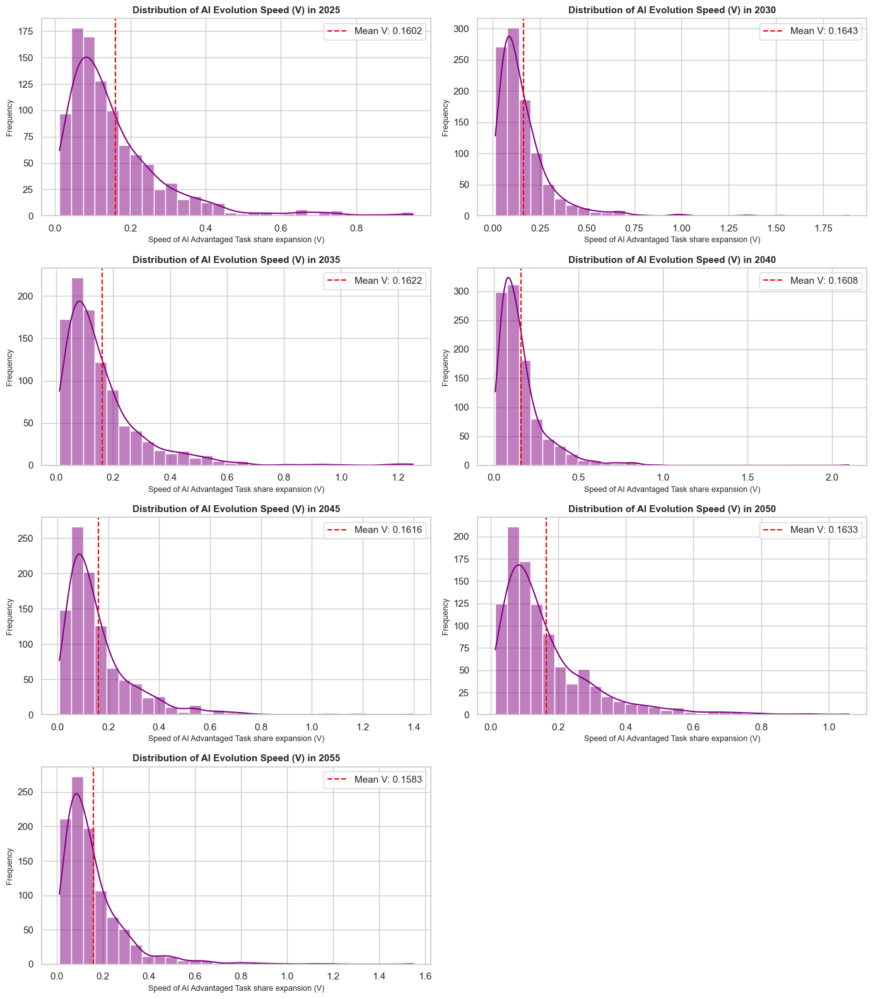

Aggregated V histograms saved to: 20261107_225814_Grid_Distribution_V_2025_to_2055.png


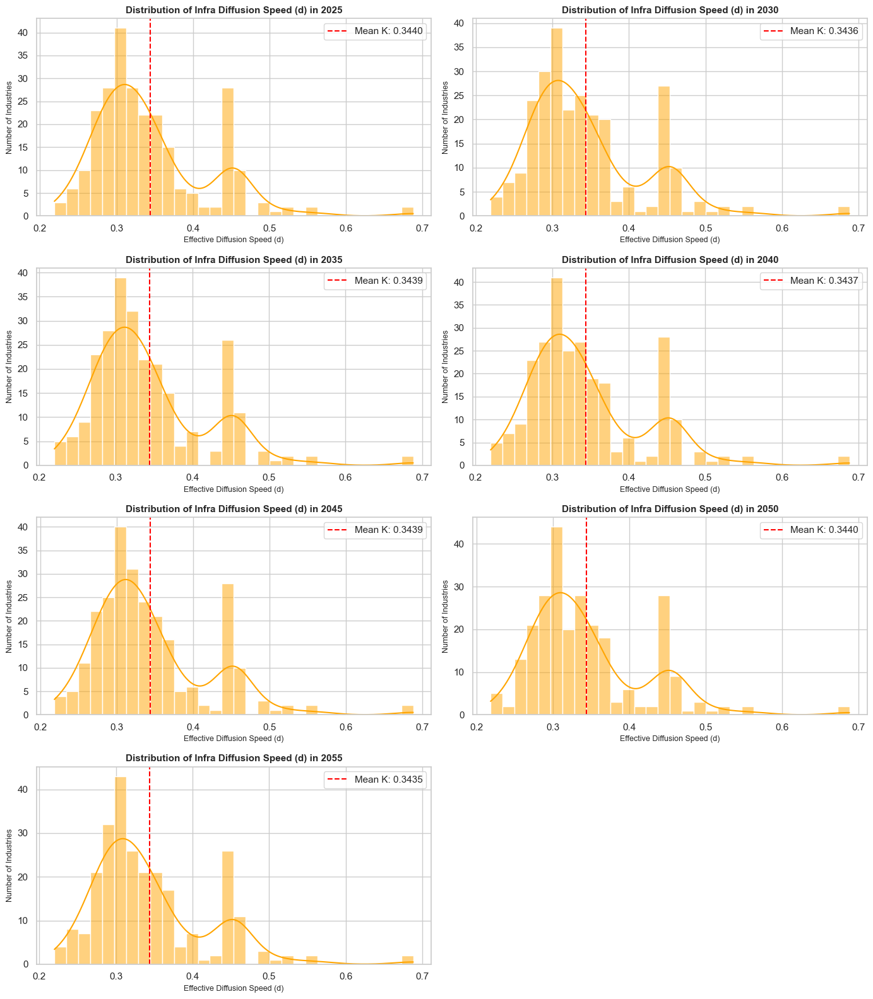

Aggregated K histograms saved to: 20261107_225814_Grid_Distribution_K_2025_to_2055.png

ANNUAL EMPLOYMENT REPLACEMENT REPORT (Baseline Scenario)
Detailed annual counts and ratios saved to: 20261107_225841_Annual_Employment_Replaced_by_AI.csv
Generating trajectory line graph for metrics...


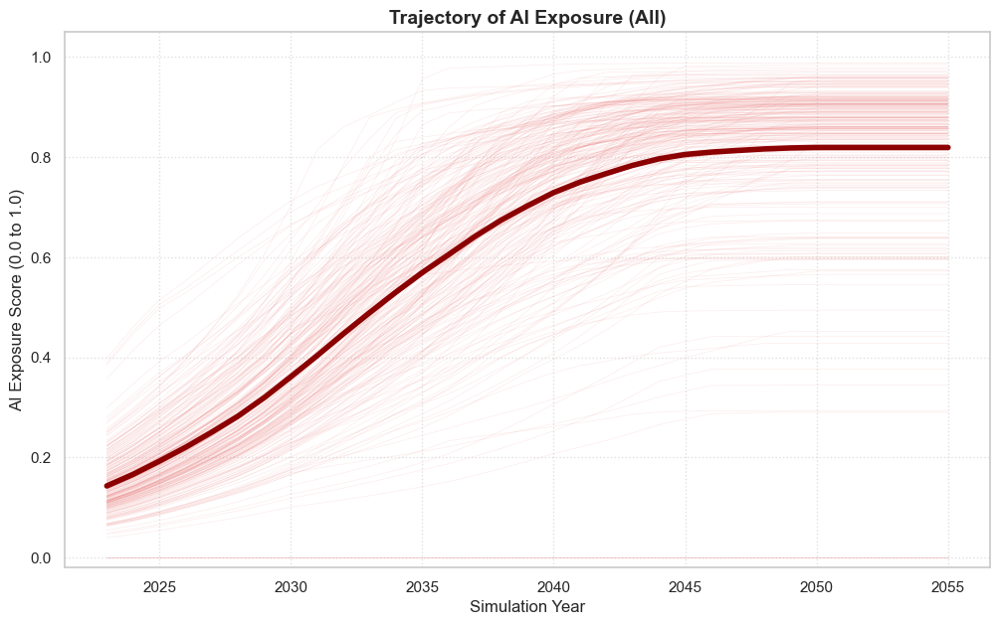

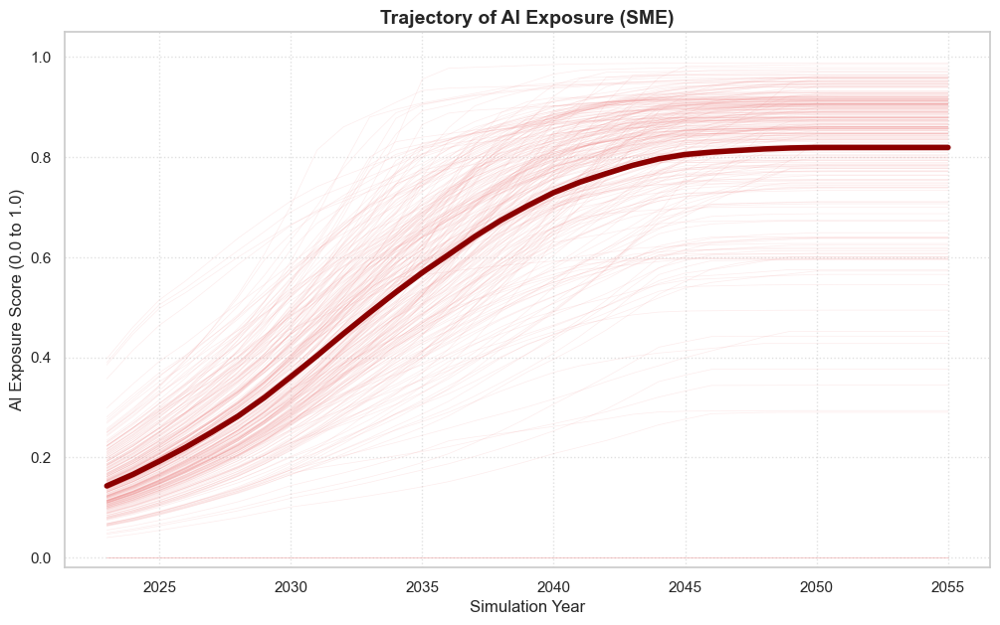

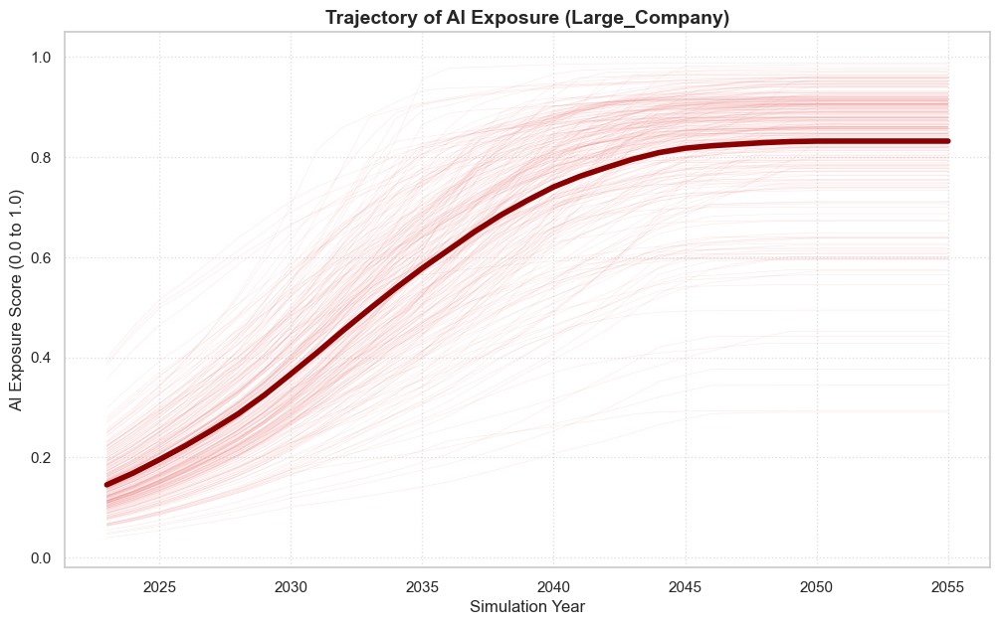

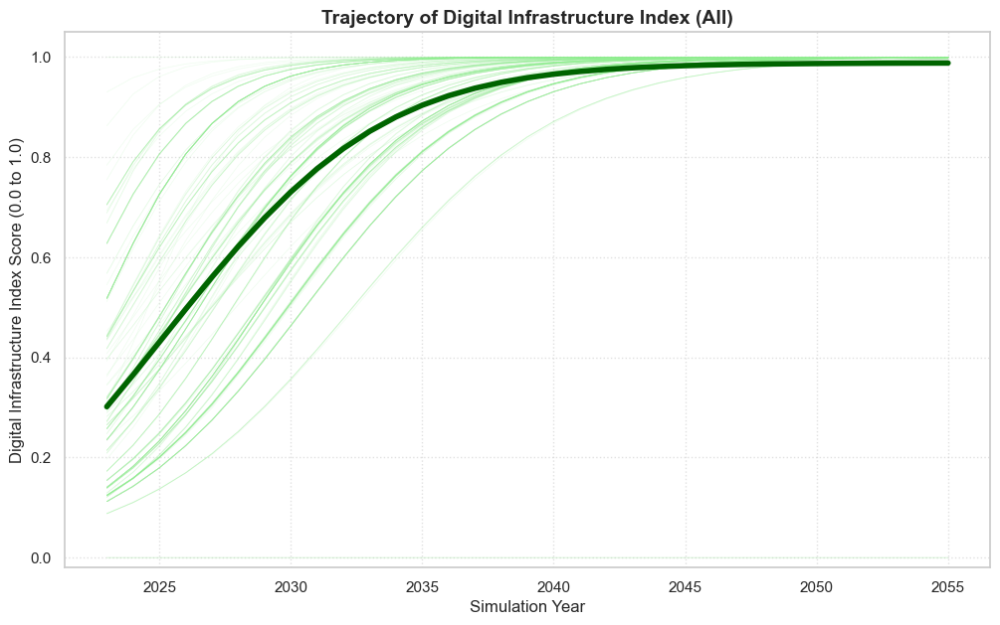

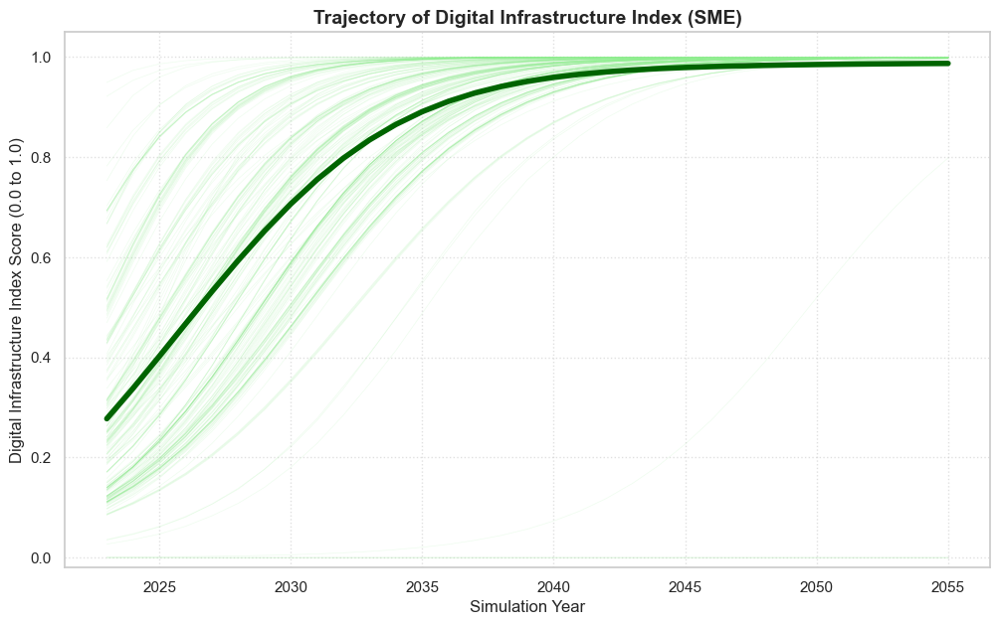

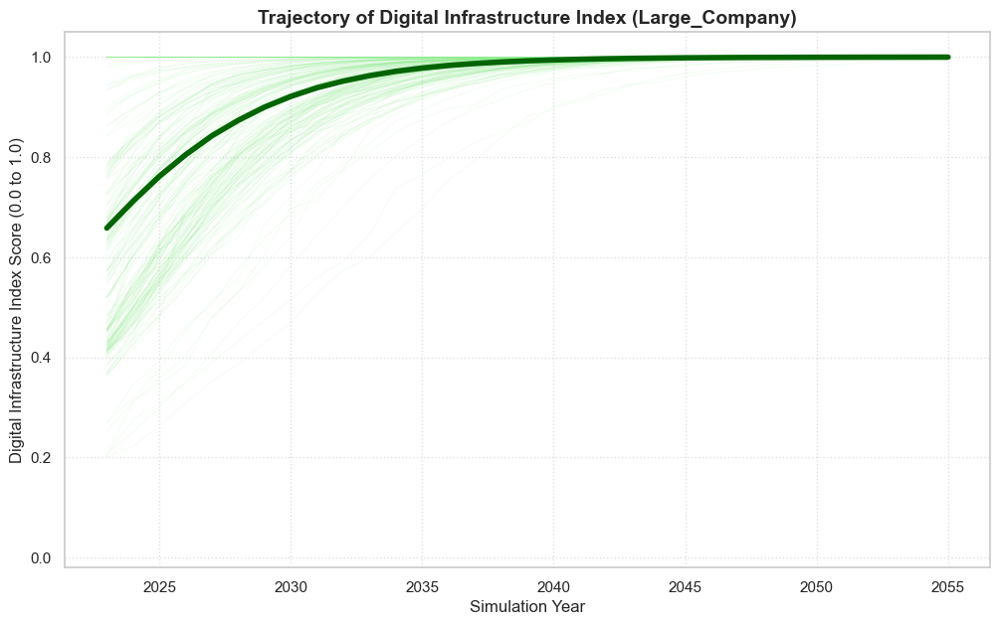

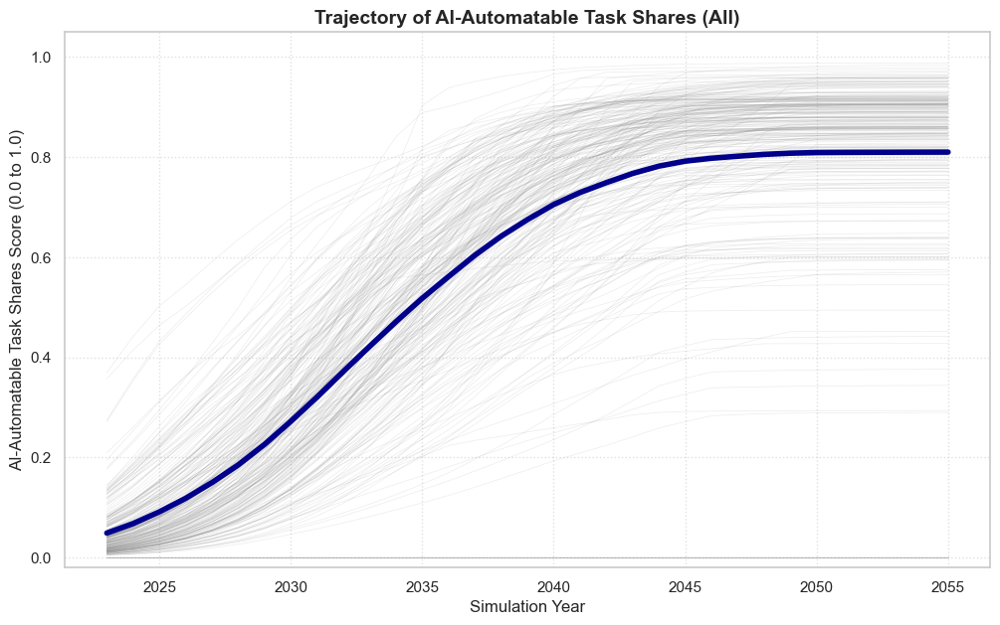

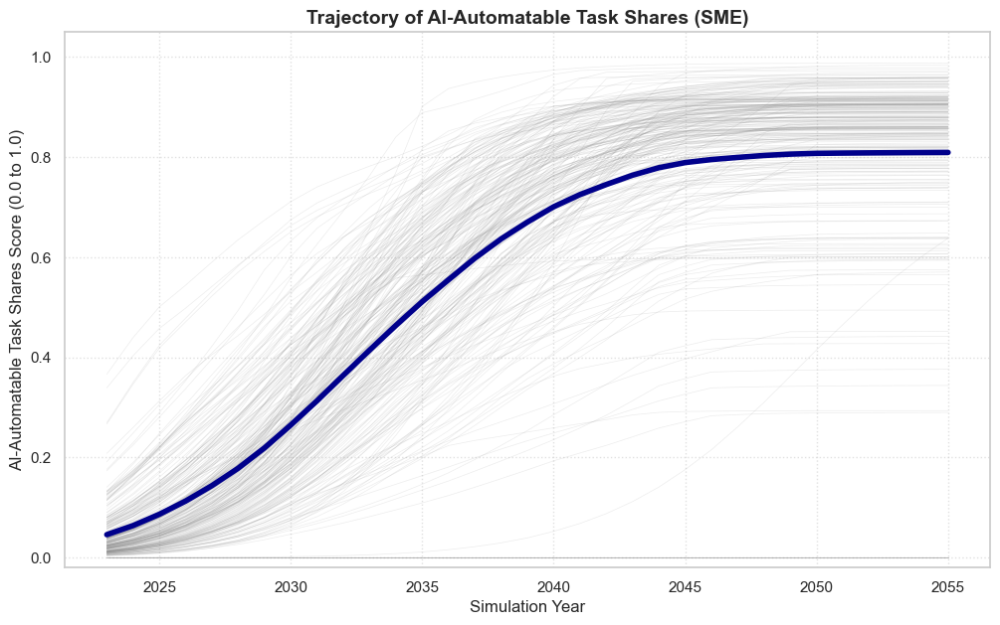

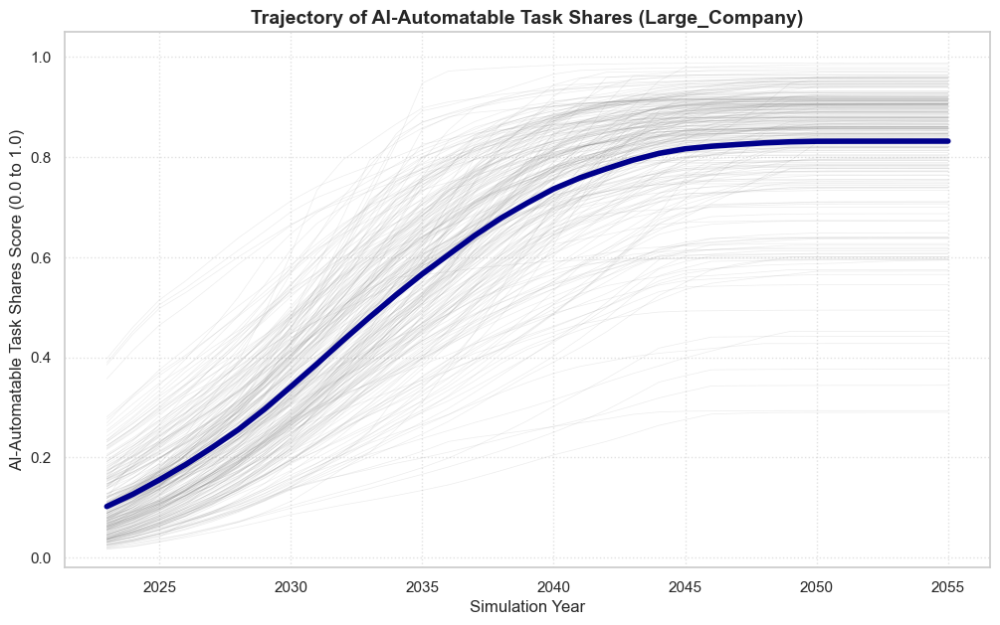

Trajectory line graphs have been displayed and saved with prefix: 20261107_225814_Impact_Trajectory_
Displaying annual industry distribution histograms in console...


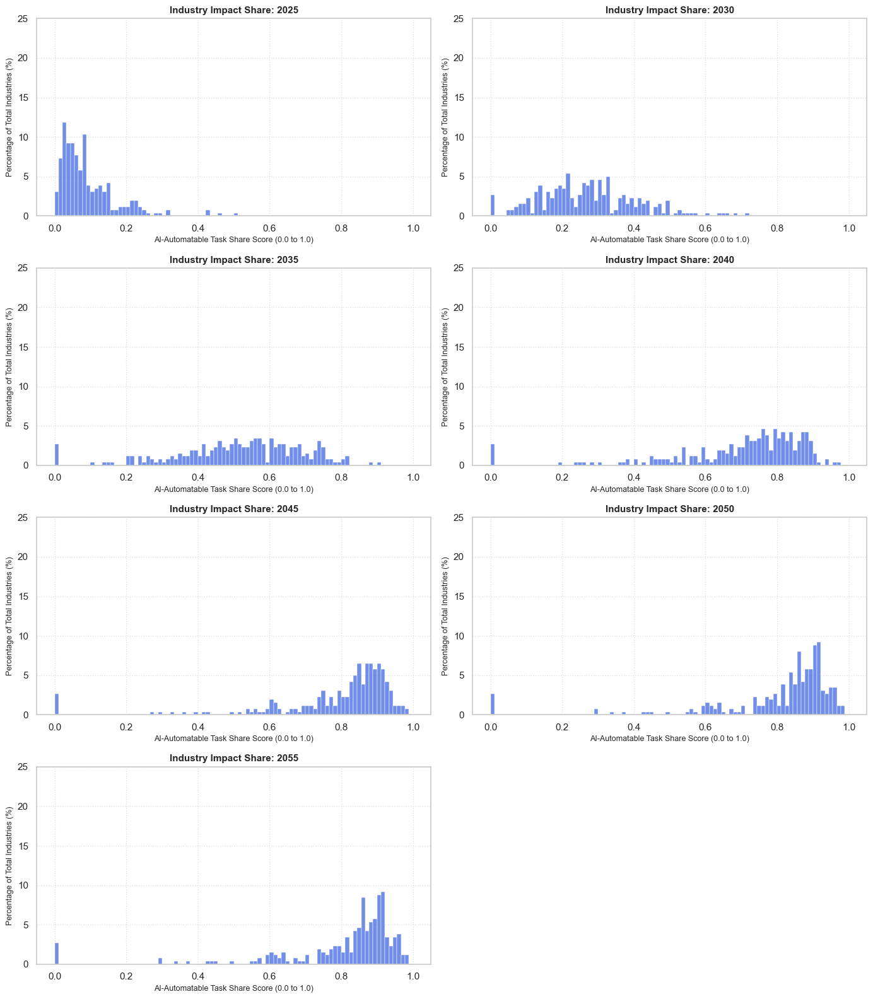

Aggregated annual histograms saved to: 20261107_225814_Grid_Histograms_2025_to_2055.png
Generating Macro Projection with industry-specific lines...


<Figure size 1200x700 with 0 Axes>

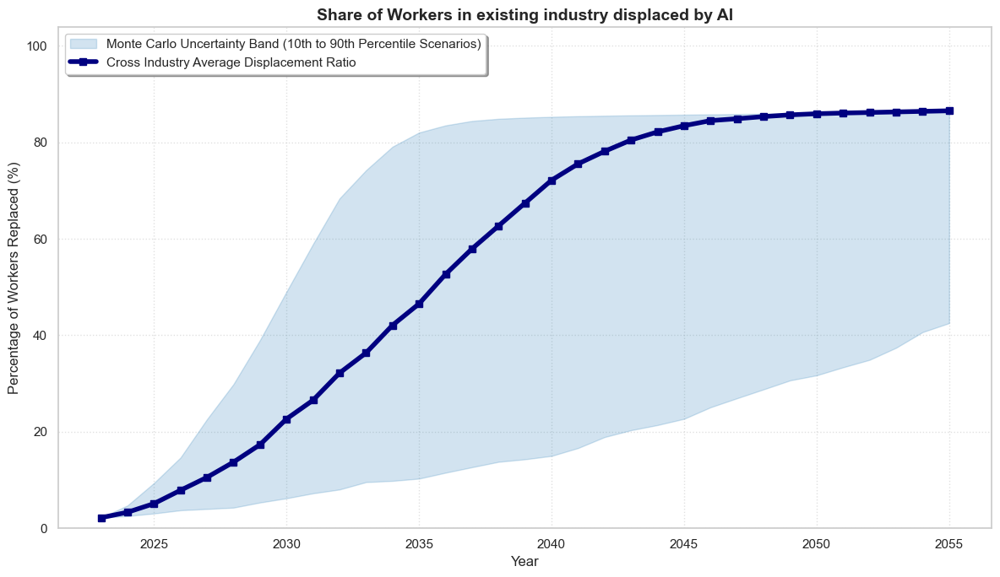

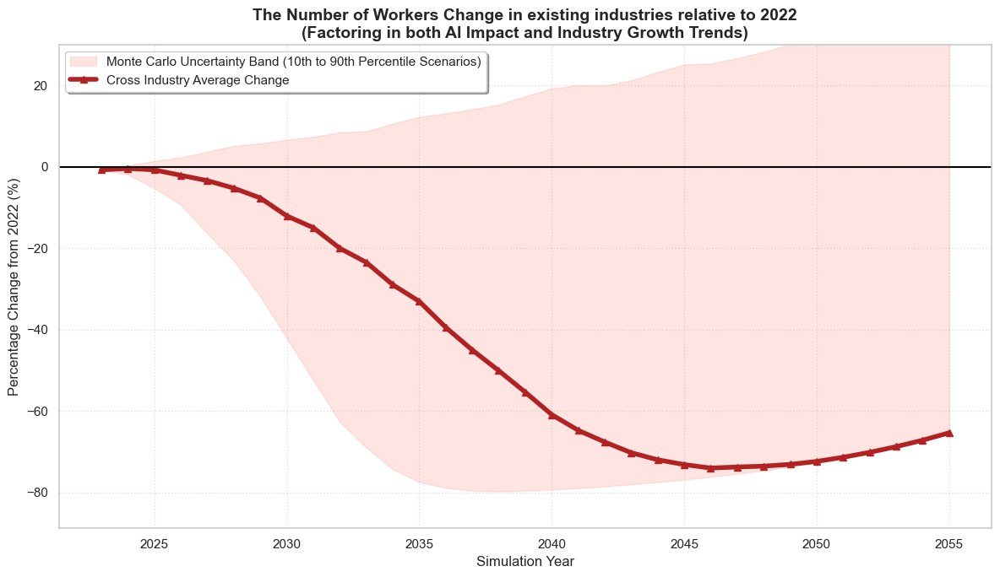

Generating Macro Projection for Sensitivity Analysis (Displacement)...


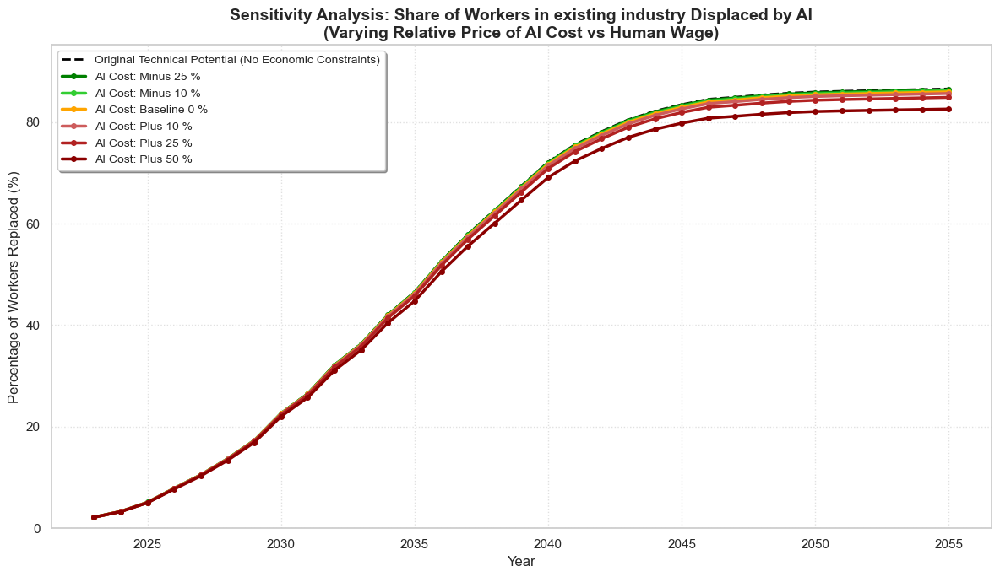

Generating Macro Projection for Sensitivity Analysis (Net Employment Change)...


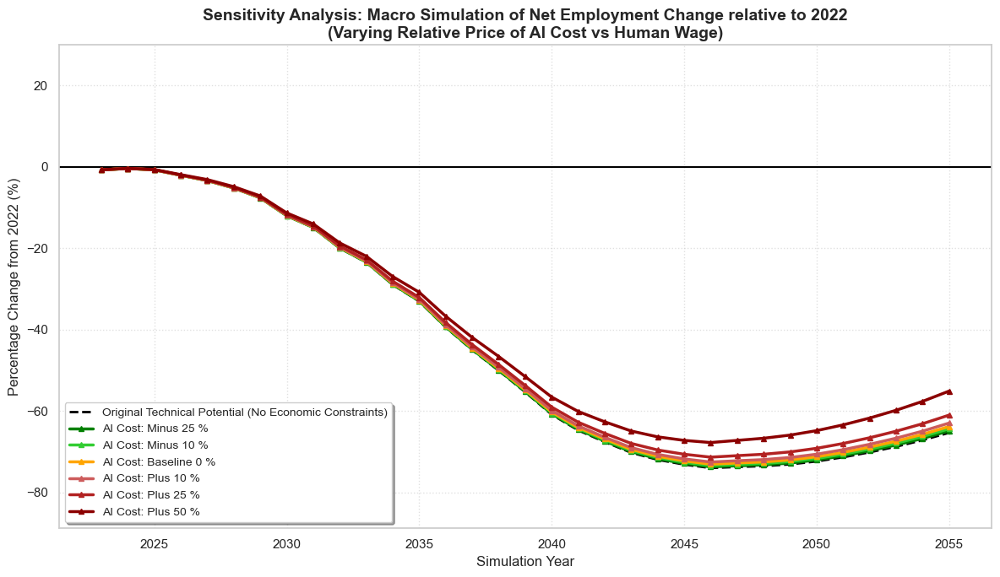

Appending 2023 Strategic Quadrant labels to the final dataset...

ANALYSIS COMPLETE: Results saved as 20261107_225908_AI_Impact_Analysis_MonteCarlo.csv

FINAL INDUSTRY COUNT SUMMARY
Total number of unique industries (NAICS) included in the final analysis: 261
Exporting national macro aggregate summary...
Macro summary saved to: 20261107_225908_Macro_Employment_Summary.csv
Generating applied historical growth slope summary report...
Historical growth slope report saved as: 20261107_225908_Applied_Historical_Employment_Slopes.csv


In [6]:
#=====Static analysis & Dynamic analysis:Only cloud usage, special software usage===
#=== replace condition: Occ level AI advantage task share>=0.5 employment trends cloud;software=6;4 === 
#=== monte calro simulation===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings
import re
import gc
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import matplotlib.patches as patches
import scipy.stats as stats

# =============================================================================
# PART 0: ENVIRONMENT SETTINGS
# =============================================================================

# Suppress warnings from Excel engines and general pandas warnings for cleaner output
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore')

# =============================================================================
# PART 1: GLOBAL PARAMETERS & CONFIGURATION
# =============================================================================
# Define file paths for external datasets (BLS, AI ratings, NSF usage, SUSB weights, and Historical trends)
FILE_PATH_BLS_STAFFING = 'bls_staffing_pattern_exclude_multipler1.csv'
FILE_PATH_OCCUPATION_AI = 'occ_level.csv'
FILE_PATH_NSF_CLOUD = 'nsf25303-tab076.xlsx'
FILE_PATH_NSF_CLOUD_GAP = 'nsf25303-tab077.xlsx'
FILE_PATH_NSF_SOFTWARE = 'nsf25303-tab078.xlsx'
FILE_PATH_NSF_SOFTWARE_GAP = 'nsf25303-tab079.xlsx'
FILE_PATH_SUSB_WEIGHTS = 'Employment_and_Payroll_by_industry_by_companysize_susb_united_states_only.csv'
FILE_PATH_SUSB_HISTORICAL_EMP = 'SUSB_Final_Regression_Data_a_h_i_Only.csv'

# Weights for the Digital Infrastructure Index: 60% Cloud usage, 40% Software usage
w1, w2 = 0.6, 0.4

# Setting Variable Name Constants for consistent referencing throughout the script
NAME_POTENTIAL_AI_EXCELS_AT = "AI Exposure"
NAME_REALIZED_AUTOMATION_IMPACT_S2 = "AI-Automatable Task Shares"  
NAME_DIGITAL_INFRA_INDEX = "Digital Infrastructure Index"

# categorical constants for size grouping
LABEL_SIZE_SME = 'SME'
LABEL_SIZE_LARGE = 'Large_Company'
LABEL_SIZE_ALL = 'All'

# Smallest possible value for Digital Infrastructure to avoid division by zero in logistic formulas
MINIMUM_DII = 1e-9

# Thresholds to categorize industries into strategic quadrants (Low/High Exposure vs Low/High Infra)
STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL = 0.2
STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA = 0.5

NUMBER_OF_TOP_INDUSTRIES_TO_DISPLAY_PER_QUADRANT = 3

# Define the percentile boundaries for the Monte Carlo uncertainty analysis
PERCENTILE_VALUE_FOR_LOWER_BOUND = 10
PERCENTILE_VALUE_FOR_UPPER_BOUND = 90

# Set the timeline for the dynamic simulation
SIMULATION_START_YEAR = 2023
SIMULATION_END_YEAR = 2055
SIMULATION_TIME_STEPS_RANGE = range(SIMULATION_START_YEAR, SIMULATION_END_YEAR + 1)

# Fix the random seed to ensure reproducibility of the simulation results across runs
MONTE_CARLO_RANDOM_SEED = 42

# Parameters for Monte Carlo simulation of AI Evolution Speed (V)
AI_EVOLUTION_SPEED_MU = 0.1594
AI_EVOLUTION_SPEED_SIGMA = 0.1458
AI_EVOLUTION_SPEED_REPLICATES = 1000
OCCUPATION_POTENTIAL_CALC_OFFSET = 0
MAX_32_BIT_INTEGER = 4294967295

# Parameters for Monte Carlo simulation of Digital Infrastructure Diffusion speed (d) 
FILE_PATH_DYNAMIC_DIFFUSION_STATS = 'DX_Adoption_Speed_K_6_4.csv' 
STANDARD_SIMULATION_REPLICATE_COUNT = 1000

# Industry-wide standard deviation (sigma) for K diffusion based on size category
DIGITAL_INFRA_DIFFUSION_SPEED_K_SIGMA_DICT = {
    LABEL_SIZE_ALL: 0.072957,
    LABEL_SIZE_SME: 0.069984,
    LABEL_SIZE_LARGE: 0.473020
}

# Parameters for the discrete displacement logic (N humans replaced by 1 human + AI). N=10 means "1 human + 9 AI = 10 units of output".
MAXIMUM_PRODUCTIVITY_MULTIPLIER_N = 10

# Generate threshold bins: [0.0, 0.5, 0.66, ..., 0.9, 1.0, 1.01]
DISCRETE_PRODUCTIVITY_THRESHOLDS =[1.0 - (1.0 / n) for n in range(1, MAXIMUM_PRODUCTIVITY_MULTIPLIER_N + 1)] +[1.0, 1.01]

# # Corresponding replacement rates: [0.0, 0.5, 0.66, ..., 0.9, 1.0] Eg:At 0.5 threshold, 50% is replaced. At 0.666 threshold, 66.6% is replaced.
DISCRETE_REPLACEMENT_RATES =[1.0 - (1.0 / n) for n in range(1, MAXIMUM_PRODUCTIVITY_MULTIPLIER_N + 1)] + [1.0]

# The grid dimensions and snapshot intervals of the probabilistic distributions of AI Evolution (V) and Infra Diffusion (K)
INTERVAL_YEAR_STEP_SIZE_FOR_MONTE_CARLO = 5
GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO = 2
SNAPSHOT_START_YEAR_FOR_MONTE_CARLO = 2025 # First year to display in the grid

# Generate the list of target years (e.g., 2025, 2030, ..., 2055)
TARGET_YEARS_FOR_MONTE_CARLO_GRID = list(range(SNAPSHOT_START_YEAR_FOR_MONTE_CARLO, SIMULATION_END_YEAR + 1, INTERVAL_YEAR_STEP_SIZE_FOR_MONTE_CARLO))


# =============================================================================
# PART 2: CORE HELPER FUNCTIONS
# =============================================================================

def standardize_naics_code_to_6_digits(code_input):
    """
    Standardizes NAICS codes into a uniform 6-digit string.
    - Removes decimals and extra spaces.
    - If a code is too short (like '44'), it adds zeros to the right (to '440000').
    - Returns an empty string for missing data (NaN).
    """
    if pd.isna(code_input): return ""
    s = str(code_input).strip().split('.')[0]
    return s.ljust(6, '0')

def expand_naics_ranges(raw_string):
    """
    Converts NAICS strings with ranges or commas into a list of individual codes.
    - Example: Converts '44-45' into ['440000', '450000'].
    - Handles shorthand: Converts '313-16' into '313' through '316'.
    - Cleans up different types of dashes and removes the word 'other'.
    """    
    if pd.isna(raw_string): return []
    codes = []
    raw_string = str(raw_string).replace('–', '-').replace('—', '-').replace('−', '-')
    
    for p in raw_string.replace('other ', '').split(','):
        p = p.strip()
        if '-' in p:
            try:
                s, e = p.split('-')
                start_val, end_val = s.strip(), e.strip()
                # Case like 44-45
                if len(start_val) == len(end_val):
                    prefix = ""
                    start_num, end_num = int(start_val), int(end_val)
                # Case like313-16 
                else:
                    prefix = start_val[:-len(end_val)] if len(start_val) > len(end_val) else ""
                    start_num, end_num = int(start_val), int(prefix + end_val)
                
                for i in range(start_num, end_num + 1): 
                    codes.append(standardize_naics_code_to_6_digits(str(i)))
            except: 
                codes.append(standardize_naics_code_to_6_digits(p))
        elif p: 
            codes.append(standardize_naics_code_to_6_digits(p))
    return codes


def convert_arithmetic_to_lognormal_parameters(target_arithmetic_mean, target_arithmetic_sigma):
    """
    Converts real-world average and spread into log-scale math parameters.
    - This is required to generate random numbers that follow a 'Lognormal' distribution.
    - It ensures the simulated results match the target mean and standard deviation.
    """ 
    # Safety check to prevent log of zero
    if target_arithmetic_mean <= 0: return 0.0, 0.0
   
    arithmetic_variance = target_arithmetic_sigma**2
    # Calculate log-scale sigma: sqrt(ln(1 + variance / mean^2))
    log_scale_sigma = np.sqrt(np.log(1 + (arithmetic_variance / (target_arithmetic_mean**2))))
    # Calculate log-scale mu: ln(mean) - 0.5 * log_scale_sigma^2
    log_scale_mu = np.log(target_arithmetic_mean) - 0.5 * (log_scale_sigma**2)
    
    return log_scale_mu, log_scale_sigma    

# Utility to print missing data diagnostics during the data pipeline.
def check_missing_values(df, label):
    print(f"\n{'='*10} MISSING VALUE CHECK: {label} {'='*10}")
    null_counts = df.isnull().sum()
    if null_counts.sum() == 0:
        print("Missing Value: 0 (None)")
    else:
        print("Missing Value Counts per column:")
        print(null_counts[null_counts > 0])
        
        #  Dynamically identify the column names for NAICS codes and titles
        naics_col = 'NAICS' if 'NAICS' in df.columns else ('std_naics' if 'std_naics' in df.columns else None)
        title_col = 'NAICS_TITLE' if 'NAICS_TITLE' in df.columns else None
        
        if naics_col:
            nan_rows = df[df.isnull().any(axis=1)]
            cols_to_show =[naics_col]
            if title_col: cols_to_show.append(title_col)
            print(f"\nFirst 5 unique NAICS with missing values:")
            print(nan_rows[cols_to_show].drop_duplicates().head(5))
    print(f"{'='*40}\n")

# =============================================================================
# PART 3: HISTORICAL TREND & EMPLOYMENT SHARE ANALYSIS
# =============================================================================
print("1. Estimating baseline employment trends and scale ratios from SUSB...")

# Load historical SUSB data to estimate natural industry growth rates
df_hist_raw = pd.read_csv(FILE_PATH_SUSB_HISTORICAL_EMP)
df_hist_raw.columns = df_hist_raw.columns.str.strip()


hist_records =[]
# Loop through years 2012 to 2022 to extract historical employment data
for yr in range(2012, 2023):
    n_c, s_c, e_c = f"NAICS_CODE_{yr}", f"FIRM_SIZE_ALPHA_{yr}", f"Employment_{yr}"

    # Check if the generated column names exist in the raw SUSB dataset
    if n_c in df_hist_raw.columns:
        t = df_hist_raw[[n_c, s_c, e_c]].copy()
        t.columns =['raw_naics', 'firm_size', 'emp']
        t['year'] = yr
        # Format the NAICS code into a standard 6-digit string
        t['std_naics'] = t['raw_naics'].apply(standardize_naics_code_to_6_digits)

        # SUSB uses single letters to represent company size (a=All, h=SME, i=Large)
        SUSB_INDICATOR_ALL_FIRMS = 'a'
        SUSB_INDICATOR_SME = 'h'
        SUSB_INDICATOR_LARGE = 'i'

        # Function to map the SUSB letter codes to internal descriptive labels
        def assign_company_size_category(raw_size_alpha):
            raw_size_lower = str(raw_size_alpha).lower()
            if SUSB_INDICATOR_ALL_FIRMS in raw_size_lower:
                return LABEL_SIZE_ALL
            elif SUSB_INDICATOR_SME in raw_size_lower:
                return LABEL_SIZE_SME
            elif SUSB_INDICATOR_LARGE in raw_size_lower:
                return LABEL_SIZE_LARGE
            else:
                return 'Other'

        # Apply the mapping and keep only rows where employment is greater than zero
        t['sz_cat'] = t['firm_size'].apply(assign_company_size_category)
        hist_records.append(t[t['emp'] > 0])

# Combine all individual yearly dataframes into one master historical dataset
df_hist_master = pd.concat(hist_records)

# Store 2022 employment as the anchor baseline for future projections
baseline_2022_susb_lookup = df_hist_master[df_hist_master['year'] == 2022].set_index(['std_naics', 'sz_cat'])['emp'].to_dict()

poisson_regression_slopes = {}

# Threshold for statistical significance (p-value >= 0.05 is considered stagnant/not significant)
SIGNIFICANCE_THRESHOLD_ALPHA = 0.05
DEFAULT_FALLBACK_GROWTH_SLOPE = 0.0

# Calculate growth slopes using Poisson Regression for every industry-size combination
for industry_group_key, industry_subset_data in df_hist_master.groupby(['std_naics', 'sz_cat']):
    if len(industry_subset_data['year'].unique()) >= 3:
        try:
            # Fit Poisson GLM to estimate historical employment dataset
            poisson_model_fit = smf.glm("emp ~ year", data=industry_subset_data, family=sm.families.Poisson()).fit()
            
            calculated_slope_estimate = poisson_model_fit.params['year']
            statistical_p_value = poisson_model_fit.pvalues['year']

            # If the growth trend is not statistically significant, force it to zero 
            if statistical_p_value >= SIGNIFICANCE_THRESHOLD_ALPHA:
                final_assigned_growth_slope = 0.0
                is_stagnant = True
            else:
                final_assigned_growth_slope = calculated_slope_estimate
                is_stagnant = False

            # Store multiple stats as a dictionary
            poisson_regression_slopes[industry_group_key] = {
                'applied_slope': final_assigned_growth_slope,
                'p_value': statistical_p_value,
                'is_stagnant_flag': is_stagnant
            }
                
        except: 
            poisson_regression_slopes[industry_group_key] = {
                'applied_slope': DEFAULT_FALLBACK_GROWTH_SLOPE,
                'p_value': np.nan,
                'is_stagnant_flag': True
            }
    else: 
        poisson_regression_slopes[industry_group_key] = {
            'applied_slope': DEFAULT_FALLBACK_GROWTH_SLOPE,
            'p_value': np.nan,
            'is_stagnant_flag': True
        }

# =============================================================================
# PART 4: DYNAMIC INDUSTRY AGGREGATION FROM OCCUPATIONS LEVEL SIMULATION
# =============================================================================
print("2. Simulating expansion of AI Exposure at occupation level...")

# Calculate the evolution of AI technical potential at the occupation level over time
df_occ_initial = pd.read_csv(FILE_PATH_OCCUPATION_AI)
df_occ_initial['occ_7'] = df_occ_initial['O*NET-SOC Code'].str[:7]
occ_init_avg = df_occ_initial.groupby('occ_7')['dv_rating_alpha'].mean().reset_index()

# Simulate compounding AI evolution speed (V) using Monte Carlo trials
np.random.seed(MONTE_CARLO_RANDOM_SEED)
# Initialize trackers for the Mean, Lower Bound (10th percentile), and Upper Bound (90th percentile) scenarios
yearly_cumulative_v_multipliers_mean = {}
yearly_cumulative_v_multipliers_lower_bound = {}
yearly_cumulative_v_multipliers_upper_bound = {}

current_cumulative_multiplier_mean = 1.0
current_cumulative_multiplier_lower_bound = 1.0
current_cumulative_multiplier_upper_bound = 1.0

yearly_effective_v = {}  

for simulation_year in SIMULATION_TIME_STEPS_RANGE:
    if simulation_year == SIMULATION_START_YEAR:
        yearly_cumulative_v_multipliers_mean[simulation_year] = 1.0
        yearly_cumulative_v_multipliers_lower_bound[simulation_year] = 1.0
        yearly_cumulative_v_multipliers_upper_bound[simulation_year] = 1.0
        yearly_effective_v[simulation_year] = 0.0  
    else:
        log_scale_mu_v, log_scale_sigma_v = convert_arithmetic_to_lognormal_parameters(
            target_arithmetic_mean=AI_EVOLUTION_SPEED_MU, 
            target_arithmetic_sigma=AI_EVOLUTION_SPEED_SIGMA
        )
        
        simulated_v_trials_array = np.random.lognormal(
            mean=log_scale_mu_v, 
            sigma=log_scale_sigma_v, 
            size=AI_EVOLUTION_SPEED_REPLICATES
        )
        
        # Extract Mean, 10th percentile (slower AI evolution), and 90th percentile (faster AI evolution)
        effective_v_mean_for_this_year = np.mean(simulated_v_trials_array)
        effective_v_lower_bound_for_this_year = np.percentile(simulated_v_trials_array, PERCENTILE_VALUE_FOR_LOWER_BOUND)
        effective_v_upper_bound_for_this_year = np.percentile(simulated_v_trials_array, PERCENTILE_VALUE_FOR_UPPER_BOUND)
                
        # Compound the growth multipliers sequentially for all 3 scenarios
        current_cumulative_multiplier_mean *= (1.0 + effective_v_mean_for_this_year)
        current_cumulative_multiplier_lower_bound *= (1.0 + effective_v_lower_bound_for_this_year)
        current_cumulative_multiplier_upper_bound *= (1.0 + effective_v_upper_bound_for_this_year)
        
        yearly_cumulative_v_multipliers_mean[simulation_year] = current_cumulative_multiplier_mean
        yearly_cumulative_v_multipliers_lower_bound[simulation_year] = current_cumulative_multiplier_lower_bound
        yearly_cumulative_v_multipliers_upper_bound[simulation_year] = current_cumulative_multiplier_upper_bound
        
        yearly_effective_v[simulation_year] = effective_v_mean_for_this_year  

# Apply the dynamic multipliers to calculate occupation potential for Mean, Lower, and Upper bounds
occ_projections =[]
for _, row in occ_init_avg.iterrows():
    initial_exposure = row['dv_rating_alpha']
    for simulation_year in SIMULATION_TIME_STEPS_RANGE:
        exposure_mean = min(1.0, (initial_exposure + OCCUPATION_POTENTIAL_CALC_OFFSET) * yearly_cumulative_v_multipliers_mean[simulation_year])
        exposure_lower = min(1.0, (initial_exposure + OCCUPATION_POTENTIAL_CALC_OFFSET) * yearly_cumulative_v_multipliers_lower_bound[simulation_year])
        exposure_upper = min(1.0, (initial_exposure + OCCUPATION_POTENTIAL_CALC_OFFSET) * yearly_cumulative_v_multipliers_upper_bound[simulation_year])
        
        occ_projections.append({
            'occ_7': row['occ_7'], 
            'Year': simulation_year, 
            'Occ_Potential_At_T': exposure_mean,
            'Occ_Potential_At_T_Lower_Bound': exposure_lower,
            'Occ_Potential_At_T_Upper_Bound': exposure_upper
        })

df_occ_dynamic = pd.DataFrame(occ_projections)

# Merge technical potential with BLS staffing data to find weighted industry potential
df_bls_raw = pd.read_csv(FILE_PATH_BLS_STAFFING, dtype={'NAICS': str})
df_bls_raw['NAICS'] = df_bls_raw['NAICS'].str.strip()
df_bls_clean = df_bls_raw[(df_bls_raw['NAICS'].str.len() == 6) & (df_bls_raw['NAICS'] != '000001')].copy()
df_bls_clean['TOT_EMP'] = pd.to_numeric(df_bls_clean['TOT_EMP'].astype(str).str.replace(',', ''), errors='coerce')

# =====MISSING WEIGHT ANALYSIS & EXCLUDE INDUSTRIES WITH 100% MISSING WEIGHTS======
#naics_weight_stats = df_bls_clean.groupby('NAICS').agg(
#    total_rows=('WEIGHT', 'size'),
#    missing_rows=('WEIGHT', lambda x: x.isna().sum())
#)

#naics_100_missing_list = naics_weight_stats[
#    naics_weight_stats['total_rows'] == naics_weight_stats['missing_rows']
#].index.tolist()

#if naics_100_missing_list:
#    excluded_info = df_bls_clean[df_bls_clean['NAICS'].isin(naics_100_missing_list)][['NAICS', 'NAICS_TITLE']].drop_duplicates()
#    print("\n" + "="*60)
#    print("DATA LOSS: Excluding industries with 100% missing weights")
#    print("="*60)
#    print(excluded_info.to_string(index=False))
#    print("-" * 60)
    
#    df_bls_clean = df_bls_clean[~df_bls_clean['NAICS'].isin(naics_100_missing_list)]
#    print("Exclusion complete. Remaining industries: ", df_bls_clean['NAICS'].nunique())
#    print("-" * 60 + "\n")
# =============================================================================

df_ind_dynamic_agg = pd.merge(df_bls_clean, df_occ_dynamic, left_on='OCC_CODE', right_on='occ_7', how='inner')
df_ind_dynamic_agg['w_sum'] = df_ind_dynamic_agg.groupby(['NAICS', 'Year'])['WEIGHT'].transform('sum')
df_ind_dynamic_agg['norm_w'] = df_ind_dynamic_agg['WEIGHT'] / df_ind_dynamic_agg['w_sum']

# Calculate weighted contributions for all 3 Monte Carlo scenarios
df_ind_dynamic_agg['weighted_contrib_mean'] = df_ind_dynamic_agg['Occ_Potential_At_T'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['weighted_contrib_lower'] = df_ind_dynamic_agg['Occ_Potential_At_T_Lower_Bound'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['weighted_contrib_upper'] = df_ind_dynamic_agg['Occ_Potential_At_T_Upper_Bound'] * df_ind_dynamic_agg['norm_w']

# Helper function to apply discrete replacement thresholds to a given exposure series
def calculate_discrete_replacement(exposure_series):
    replaced_rate = pd.cut(
        exposure_series, bins=DISCRETE_PRODUCTIVITY_THRESHOLDS, labels=DISCRETE_REPLACEMENT_RATES, right=False, include_lowest=True
    ).astype(float)
    replaced_rate[exposure_series >= 1.0] = 1.0 # Cap at 100% replacement
    return replaced_rate

# Calculate discrete replacement rates for all 3 scenarios
df_ind_dynamic_agg['occupation_discrete_replacement_rate_mean'] = calculate_discrete_replacement(df_ind_dynamic_agg['Occ_Potential_At_T'])
df_ind_dynamic_agg['occupation_discrete_replacement_rate_lower'] = calculate_discrete_replacement(df_ind_dynamic_agg['Occ_Potential_At_T_Lower_Bound'])
df_ind_dynamic_agg['occupation_discrete_replacement_rate_upper'] = calculate_discrete_replacement(df_ind_dynamic_agg['Occ_Potential_At_T_Upper_Bound'])

# =========================================================================
# 1. ORIGINAL ANALYSIS (Purely Technical, No Economic Cost Factor)
# =========================================================================
df_ind_dynamic_agg['share_of_replaced_employment_pool_mean'] = df_ind_dynamic_agg['occupation_discrete_replacement_rate_mean'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['share_of_replaced_employment_pool_lower'] = df_ind_dynamic_agg['occupation_discrete_replacement_rate_lower'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['share_of_replaced_employment_pool_upper'] = df_ind_dynamic_agg['occupation_discrete_replacement_rate_upper'] * df_ind_dynamic_agg['norm_w']

# =========================================================================
# 2. SENSITIVITY ANALYSIS (Economic Cost Factor based on Relative Price)
# =========================================================================
# Clean BLS Annual Mean Wage (A_MEAN) data
df_ind_dynamic_agg['A_MEAN_CLEAN'] = pd.to_numeric(df_ind_dynamic_agg['A_MEAN'].astype(str).str.replace(',', ''), errors='coerce')
global_median_annual_wage_imputation = df_ind_dynamic_agg['A_MEAN_CLEAN'].median()
df_ind_dynamic_agg['A_MEAN_CLEAN'] = df_ind_dynamic_agg['A_MEAN_CLEAN'].fillna(global_median_annual_wage_imputation)

# Base cost derived from SWE-agent and related estimates
BASELINE_ANNUAL_LLM_COST_USD = 18144.0

# We define a standard deviation for the relative price distribution (Coefficient of Variation)
# This implies the relative price varies by 25% across different contexts within the same occupation
RELATIVE_PRICE_DISTRIBUTION_COEFFICIENT_OF_VARIATION = 0.25 

# Define variations for sensitivity analysis of the LLM cost
LLM_COST_SCENARIO_VARIATIONS = {
    'minus_25_percent': -0.25,
    'minus_10_percent': -0.10,
    'baseline_0_percent': 0.0,
    'plus_10_percent': 0.10,
    'plus_25_percent': 0.25,
    'plus_50_percent': 0.50
}

economic_share_columns =[]

for scenario_name, cost_variation in LLM_COST_SCENARIO_VARIATIONS.items():
    # Calculate the adjusted LLM cost for this specific scenario
    adjusted_llm_cost_for_scenario = BASELINE_ANNUAL_LLM_COST_USD * (1.0 + cost_variation)
    
    # Calculate the mean of the relative price (Wage / Adjusted LLM Cost)
    mean_relative_price_mu = df_ind_dynamic_agg['A_MEAN_CLEAN'] / adjusted_llm_cost_for_scenario
    
    # Calculate the standard deviation of the relative price
    std_dev_relative_price_sigma = mean_relative_price_mu * RELATIVE_PRICE_DISTRIBUTION_COEFFICIENT_OF_VARIATION
    
    # Calculate the probability that the relative price > 1.0 (which means Wage > LLM Cost)
    # Using the Survival Function (sf) which is mathematically identical to 1 - CDF
    probability_relative_price_exceeds_one = stats.norm.sf(1.0, loc=mean_relative_price_mu, scale=std_dev_relative_price_sigma)
    
    # Calculate the economically adjusted replaced share for this scenario
    col_name_for_scenario_share = f'share_replaced_economic_{scenario_name}'
    economic_share_columns.append(col_name_for_scenario_share)
    
    # We apply this economic probability to the 'mean' technical replacement rate
    df_ind_dynamic_agg[col_name_for_scenario_share] = (
        df_ind_dynamic_agg['occupation_discrete_replacement_rate_mean'] 
        * probability_relative_price_exceeds_one 
        * df_ind_dynamic_agg['norm_w']
    )

# Setup the dictionary for dynamic aggregation of industry potentials
aggregation_dictionary_for_industry = {
    'weighted_contrib_mean': 'sum', 
    'weighted_contrib_lower': 'sum', 
    'weighted_contrib_upper': 'sum', 
    'share_of_replaced_employment_pool_mean': 'sum',
    'share_of_replaced_employment_pool_lower': 'sum',
    'share_of_replaced_employment_pool_upper': 'sum',
    'TOT_EMP': 'sum'
}
# Append the economic scenarios to the aggregation dictionary
for col_name_for_scenario_share in economic_share_columns:
    aggregation_dictionary_for_industry[col_name_for_scenario_share] = 'sum'

# Aggregate the metrics to an industry-year summary
df_yearly_industry_tech_potential = df_ind_dynamic_agg.groupby(['NAICS', 'NAICS_TITLE', 'Year']).agg(aggregation_dictionary_for_industry).reset_index()

# Rename columns to standard output names
rename_dictionary_for_output = {
    'weighted_contrib_mean': 'Industry_Potential_At_T', 
    'weighted_contrib_lower': 'Industry_Potential_At_T_Lower_Bound', 
    'weighted_contrib_upper': 'Industry_Potential_At_T_Upper_Bound', 
    'share_of_replaced_employment_pool_mean': 'Industry_Fully_Replaceable_Workforce_Share_At_T',
    'share_of_replaced_employment_pool_lower': 'Industry_Fully_Replaceable_Workforce_Share_At_T_Lower_Bound',
    'share_of_replaced_employment_pool_upper': 'Industry_Fully_Replaceable_Workforce_Share_At_T_Upper_Bound',
    'TOT_EMP': 'emp_bls_2022'
}
for col_name_for_scenario_share in economic_share_columns:
    # Create a clean output column name for the economic scenarios
    clean_scenario_label = col_name_for_scenario_share.replace("share_replaced_economic_", "")
    rename_dictionary_for_output[col_name_for_scenario_share] = f'Industry_Replaceable_Share_Economic_{clean_scenario_label}'
    
df_yearly_industry_tech_potential = df_yearly_industry_tech_potential.rename(columns=rename_dictionary_for_output)


#check_missing_values(df_yearly_industry_tech_potential, "PART 4: After Industry Tech Potential Aggregation")

gc.collect()

# =============================================================================
# PART 5: DIGITAL INFRASTRUCTURE ANCHORING 
# =============================================================================
# Map Cloud and Software adoption rates from NSF data to industries
print("3. Anchoring industry-average digital infrastructure index (Cloud & Software)...")


def build_dict(path, col):
    """
    Creates a dictionary mapping NAICS codes to adoption rates from NSF Excel files.
    - Skips header rows and iterates through each industry row.
    - Converts percentage values (e.g., 25.0) into decimal format (0.25).
    - Uses 'expand_naics_ranges' to ensure every individual NAICS code in a range is 
      assigned the same adoption rate.
    """
    d = {}
    for _, r in pd.read_excel(path, skiprows=3).iterrows():
        rate = pd.to_numeric(r.iloc[col], errors='coerce') * 0.01
        for c in expand_naics_ranges(r.iloc[1]): d[c] = rate
    return d

# Generate reference dictionaries for Cloud and Software adoption
dict_cl = build_dict(FILE_PATH_NSF_CLOUD, 10)
dict_sf = build_dict(FILE_PATH_NSF_SOFTWARE, 10)

def h_search(naics, source):
    """
    Performs a hierarchical search to find data for a specific NAICS code.
    - First looks for an exact 6-digit match.
    - If not found, it progressively checks broader industry categories (5-digit, 4-digit, etc.).
    - Returns NaN if no match is found at any level.
    """
    for spec in range(6, 1, -1):
        key = naics[:spec].ljust(6, '0')
        if key in source: return source[key]
    return np.nan

# Create a base dataframe of unique industries from the BLS data
df_dri_base = df_bls_clean[['NAICS', 'NAICS_TITLE']].drop_duplicates().copy()

# Apply the hierarchical search to fetch adoption scores for Cloud and Software
df_dri_base['c_avg'] = df_dri_base['NAICS'].apply(lambda x: h_search(x, dict_cl))
df_dri_base['s_avg'] = df_dri_base['NAICS'].apply(lambda x: h_search(x, dict_sf))

# =====DATA SOURCE TRACKING LOGIC ======
# Define labels to identify the origin of the adoption data
DETAILED_NAICS_CODE_LENGTH = 6
LABEL_EXACT_MATCH = 'Original (Exact Match)'
LABEL_HIERARCHICAL_MATCH = 'Source Aggregate (Hierarchical Match)'
LABEL_GLOBAL_AVERAGE = 'Global Average (All Industries)'

def identify_source_type_using_h_search(naics_code, source_data_dict):
    """
    Identifies if a data point was found exactly or inherited from a parent category.
    - Returns 'Exact Match' if the 6-digit code exists in the source.
    - Returns 'Hierarchical Match' if data was found using the h_search fallback logic.
    """
    if pd.isna(naics_code): return 'Missing'
    
    # 1. First, check if the 6-digit code exists EXACTLY in the source dictionary
    exact_match_key = naics_code[:DETAILED_NAICS_CODE_LENGTH].ljust(6, '0')
    if exact_match_key in source_data_dict:
        return LABEL_EXACT_MATCH
    
    # 2. Second, use the existing h_search to see if any higher-level (5,4,3,2 digit) data exists
    # If h_search returns a value (not NaN), it means a hierarchical aggregate was found.
    found_value_via_hierarchy = h_search(naics_code, source_data_dict)
    if pd.notna(found_value_via_hierarchy):
        return LABEL_HIERARCHICAL_MATCH
            
    return 'Missing'
# ========================================

# Track the source type for both Cloud and Software adoption rates
df_dri_base['c_source_type'] = df_dri_base['NAICS'].apply(lambda x: identify_source_type_using_h_search(x, dict_cl))
df_dri_base['s_source_type'] = df_dri_base['NAICS'].apply(lambda x: identify_source_type_using_h_search(x, dict_sf))

def consolidate_imputation_label(row):
    """
    Consolidates individual source types into a single 'Imputation_Type' label for the industry.
    Prioritizes 'Exact Match' labels if they exist for either data source.
    """
    if row['c_source_type'] == LABEL_EXACT_MATCH or row['s_source_type'] == LABEL_EXACT_MATCH:
        return LABEL_EXACT_MATCH
    if row['c_source_type'] == LABEL_HIERARCHICAL_MATCH or row['s_source_type'] == LABEL_HIERARCHICAL_MATCH:
        return LABEL_HIERARCHICAL_MATCH
    return 'Pending'

# Assign the final consolidated data origin label to each industry
df_dri_base['Imputation_Type'] = df_dri_base.apply(consolidate_imputation_label, axis=1)

# FINAL STEP: Fill remaining gaps (where h_search found nothing) with the global industry average
for target_column in ['c_avg', 's_avg']:
    overall_mean_value = df_dri_base[target_column].mean()
    is_missing_mask = df_dri_base[target_column].isna()
    
    df_dri_base.loc[is_missing_mask, target_column] = overall_mean_value
    df_dri_base.loc[is_missing_mask, 'Imputation_Type'] = LABEL_GLOBAL_AVERAGE
    
df_dri_base['Imputation_Type'] = 'Original'

#check_missing_values(df_dri_base, "PART 5: After Digital Infrastructure Mapping")

# ===== imputation summary =====
print("\n" + "="*80)
print("IMPUTATION SUMMARY BY INDUSTRY (Cloud & Software)")
print("="*80)
summary_counts = df_dri_base['Imputation_Type'].value_counts()
for imp_type, count in summary_counts.items():
    print(f" - {imp_type}: {count} industries")

df_sector_imputed = df_dri_base[df_dri_base['Imputation_Type'] == 'Sector Average (2-Digit)']
if not df_sector_imputed.empty:
    print("\n[ Filled with Sector Average (2-Digit) ]")
    print(df_sector_imputed[['NAICS', 'NAICS_TITLE']].to_string(index=False))

df_global_imputed = df_dri_base[df_dri_base['Imputation_Type'] == 'Global Average (All Industries)']
if not df_global_imputed.empty:
    print("\n[ Filled with Global Average (All Industries) ]")
    print(df_global_imputed[['NAICS', 'NAICS_TITLE']].to_string(index=False))
print("="*80 + "\n")
# =============================

# =============================================================================
# PART 6: FINAL SIMULATION 
# =============================================================================
# Execute the core time-series simulation factoring in employment growth and AI diffusion
print("4. Executing final dynamic simulation...")

# Load Dynamic Diffusion Stats (d) for Monte Carlo Simulation 
try:
    df_dynamic_diffusion_stats = pd.read_csv(FILE_PATH_DYNAMIC_DIFFUSION_STATS, dtype={'NAICS': str})
    df_dynamic_diffusion_stats['NAICS'] = df_dynamic_diffusion_stats['NAICS'].apply(standardize_naics_code_to_6_digits)
    print("Successfully loaded dynamic diffusion stats (d).")

except FileNotFoundError:
    print(f"WARNING: File '{FILE_PATH_DYNAMIC_DIFFUSION_STATS}' not found. Please check the file path.")

def get_national_gap_ratio(path, col_idx):
    """
    Calculates the national ratio of adoption between Large companies and SMEs.
    - Used to estimate how much faster large firms adopt technology compared to small ones.
    """
    df = pd.read_excel(path, skiprows=3, engine='openpyxl')
    # Define row indices for Small (SME) and Large company categories based on the NSF table structure
    s_idx, l_idx =[2,3,5,6,8,9,11],[12,13,14,15,16]
    s_sub = df.iloc[s_idx, [1, col_idx]].apply(pd.to_numeric, errors='coerce')
    l_sub = df.iloc[l_idx, [1, col_idx]].apply(pd.to_numeric, errors='coerce')
    
    # Calculate the weighted average rate for Large firms divided by the weighted average for SMEs
    return (l_sub.iloc[:, 0]*l_sub.iloc[:, 1]).sum()/l_sub.iloc[:, 0].sum() / \
           ((s_sub.iloc[:, 0]*s_sub.iloc[:, 1]).sum()/s_sub.iloc[:, 0].sum())

# Calculate the gap between SME and Large firm adoption for decomposition
cl_gap_nat = get_national_gap_ratio(FILE_PATH_NSF_CLOUD_GAP, 9)
sf_gap_nat = get_national_gap_ratio(FILE_PATH_NSF_SOFTWARE_GAP, 9)

# Standardize DII scores to a 0.0 - 1.0 scale using Z-scores
scaler_all = StandardScaler()
scaler_all.fit(df_dri_base[['c_avg', 's_avg']])

list_z_all_ref =[]
for _, row_ref in df_dri_base.iterrows():
    zv = scaler_all.transform([[row_ref['c_avg'], row_ref['s_avg']]])[0]
    list_z_all_ref.append((zv[0] * w1 + zv[1] * w2))
dii_min = min(list_z_all_ref)
dii_max = max(list_z_all_ref)
dii_range = dii_max - dii_min

# Load the SUSB dataset containing firm counts by industry and size category
df_susb_w = pd.read_csv(FILE_PATH_SUSB_WEIGHTS, dtype=str)
df_susb_w.columns = df_susb_w.columns.str.strip()

# Standardize NAICS codes into the uniform 6-digit format used throughout the script
df_susb_w['NAICS_clean'] = df_susb_w['NAICS'].apply(standardize_naics_code_to_6_digits)
df_susb_w['f_n'] = pd.to_numeric(df_susb_w['Firms'].str.replace(',', ''), errors='coerce')

# Extract weights for SMEs (Small and Medium Enterprises)
# Filter rows where 'Enterprise Size' contains the SUSB code '08:' (representing SME size brackets)
ws_df = df_susb_w[df_susb_w['Enterprise Size'].str.contains('08:', na=False)]
ws_df = ws_df.groupby('NAICS_clean')['f_n'].sum().reset_index().rename(columns={'NAICS_clean':'NAICS', 'f_n':'w_sme'})

# Extract weights for Large Companies
# Filter rows where 'Enterprise Size' contains the SUSB code '09:' (representing large size brackets)
wl_df = df_susb_w[df_susb_w['Enterprise Size'].str.contains('09:', na=False)]
wl_df = wl_df.groupby('NAICS_clean')['f_n'].sum().reset_index().rename(columns={'NAICS_clean':'NAICS', 'f_n':'w_large'})

# Prepare SUSB weights for firm-size decomposition (SME vs Large)
df_weights = pd.merge(ws_df, wl_df, on='NAICS', how='outer')
df_sim_ready = df_dri_base.merge(df_weights, on='NAICS', how='left')


# ======SUSB WEIGHT MAPPING (Hierarchical Search)======
# ensures that every industry has firm-count weights (SME vs Large), 

print("Mapping SUSB weights using hierarchical search for range codes (e.g., 44-45)...")

# Convert the weights dataframe into a dictionary for high-speed lookups
ref_weights_dict = df_weights.set_index('NAICS').to_dict('index')

def find_best_susb_weight(specific_naics):
    """
    Finds the most accurate firm-size weights for a code by trying three methods:
    1. Exact Match: Is the 6-digit code in the dictionary?
    2. Range Match: Does it belong to a sector that SUSB groups (e.g., Retail 44-45)?
    3. Hierarchical: If not found, look at the parent industry (e.g., 5-digit or 4-digit level).
    """
    # 1. Check for an exact 6-digit NAICS match
    if specific_naics in ref_weights_dict:
        return ref_weights_dict[specific_naics]

    # 2. Map to special SUSB range codes (Standard industry groupings)
    # Retail (44-45), Manufacturing (31-33), and Transport (48-49) often use range codes.
    prefix_2 = specific_naics[:2]
    sector_range_map = {
        '44': '44-450', '45': '44-450',
        '31': '31-330', '32': '31-330', '33': '31-330',
        '48': '48-490', '49': '48-490'
    }
    
    if prefix_2 in sector_range_map:
        range_key = sector_range_map[prefix_2]
        if range_key in ref_weights_dict:
            return ref_weights_dict[range_key]

    # 3. Hierarchical search: Progressively look at broader parent categories
    for length in range(5, 1, -1):
        parent_key = specific_naics[:length].ljust(6, '0')
        if parent_key in ref_weights_dict:
            return ref_weights_dict[parent_key]
            
    # Return NaN if no data could be found at any level        
    return {'w_sme': np.nan, 'w_large': np.nan}

# Apply the search logic only to rows where weights are currently missing
for idx, row in df_sim_ready.iterrows():
    if pd.isna(row['w_sme']):
        best_weight = find_best_susb_weight(row['NAICS'])
        df_sim_ready.at[idx, 'w_sme'] = best_weight['w_sme']
        df_sim_ready.at[idx, 'w_large'] = best_weight['w_large']

print("SUSB weight hierarchical mapping complete.")
# Verify the results and report any remaining gaps
#check_missing_values(df_sim_ready, "PART 6: After Improved SUSB Weight Mapping")

print("Validated SUSB weight mapping complete.")
#check_missing_values(df_sim_ready, "PART 6: After Merging SUSB Weights (Simulation Ready Data)")

# Initialize a list to hold the calculated results for every industry, size, and year
simulation_records_collector =[]

# List to collect industries where the diffusion speed (d) could not be matched
failed_diffusion_matches_collector = []

# Loop through every industry prepared in the setup phase
for _, industry_row in df_sim_ready.iterrows():
    naics_key = industry_row['NAICS']
    ws, wl = industry_row['w_sme'], industry_row['w_large']

     # Get the imputation flag to track data origin
    imp_type = industry_row['Imputation_Type']

    # Calculate the proportion of large firms in this specific industry
    total_firms = ws + wl
    firm_share_l = wl / total_firms if total_firms > 0 else 0.5
    
    # Using the national adoption gap directly since remote work proxies were removed
    cur_cl_gap, cur_sf_gap = cl_gap_nat, sf_gap_nat

    # Helper function to decompose the overall industry adoption average into separate 
    # rates for SMEs and Large companies, based on the national gap ratio.
    def decomp(avg, gap, share_l):
        s = avg / ((1 - share_l) + (share_l * gap))
        return s, min(1.0, s * gap)
    
    # Calculate Cloud and Software adoption rates for SMEs (cs, ss) and Large firms (cl, sl)
    cs, cl = decomp(industry_row['c_avg'], cur_cl_gap, firm_share_l)
    ss, sl = decomp(industry_row['s_avg'], cur_sf_gap, firm_share_l)

    # Run the simulation for three perspectives: All firms, SMEs only, and Large firms only
    for sz_cat, cv, sv in [(LABEL_SIZE_ALL, industry_row['c_avg'], industry_row['s_avg']),
                           (LABEL_SIZE_SME, cs, ss),
                           (LABEL_SIZE_LARGE, cl, sl)]:
        
        # Retrieve the 2022 baseline employment directly for the specific size category        
        baseline_2022 = np.nan
        
        # Hierarchical search: if exact 6-digit data isn't found, check 5-digit, 4-digit, etc.
        for specificity_level in range(6, 1, -1):
            hierarchical_baseline_key = (naics_key[:specificity_level].ljust(6, '0'), sz_cat)
            if hierarchical_baseline_key in baseline_2022_susb_lookup:
                baseline_2022 = baseline_2022_susb_lookup[hierarchical_baseline_key]
                break
                
        # Skip this iteration if no baseline employment data exists
        if pd.isna(baseline_2022) or baseline_2022 == 0: 
            continue
        
        # ----- EMPLOYMENT-BASED SLOPE DETERMINATION -----
        # Retrieve the historical slope estimated directly in PART 3. 
        slope_final = 0.0
        for specificity_level in range(6, 1, -1):
            hierarchical_slope_key = (naics_key[:specificity_level].ljust(6, '0'), sz_cat)
            if hierarchical_slope_key in poisson_regression_slopes:
                slope_final = poisson_regression_slopes[hierarchical_slope_key].get('applied_slope', 0.0)
                break
        #-------------------------------------------------

        # Normalize the digital infrastructure scores (Cloud & Software) into a single 0.0 to 1.0 index
        zv_anchor = scaler_all.transform([[cv, sv]])[0]
        dii_z_score_initial = (zv_anchor[0]*w1 + zv_anchor[1]*w2)
        dii_normalized_anchor = max(MINIMUM_DII, min(1, (dii_z_score_initial - dii_min) / dii_range))

        # --- MONTE CARLO SETUP FOR DIGITAL INFRASTRUCTURE DIFFUSION (d) ---
        # Retrieve parameters (mu and number of replicates) from the  CSV
        diffusion_params_match = df_dynamic_diffusion_stats[
            (df_dynamic_diffusion_stats['NAICS'] == naics_key) & 
            (df_dynamic_diffusion_stats['Company_Size'] == sz_cat)
        ]
        
        # Define a standard sample size for Monte Carlo replicates to ensure statistical stability
        # if the actual firm count data is missing or invalid.
        if not diffusion_params_match.empty:
            # Safely extract the diffusion speed mu (d) from the CSV data
            diffusion_speed_mu_k = float(diffusion_params_match.iloc[0]['diffusion_speed_k'])
            
            # Fetch the number of firms to use as Monte Carlo replicates
            raw_firm_count_from_csv = diffusion_params_match.iloc[0]['Number_of_Firms']

            # VALIDATION: Check if the firm count is NaN or invalid. 
            # If so, use 1000 replicates to ensure a reliable and stable industry-wide mean.
            if pd.isna(raw_firm_count_from_csv) or raw_firm_count_from_csv <= 0:
                number_of_firms_for_replicates = STANDARD_SIMULATION_REPLICATE_COUNT
            else:
                number_of_firms_for_replicates = int(raw_firm_count_from_csv)
        else:
            # Fallback for cases where no industry match is found in the CSV
            diffusion_speed_mu_k = 0.0
            number_of_firms_for_replicates = STANDARD_SIMULATION_REPLICATE_COUNT
        
            
        # Get the corresponding standard deviation based on company size category
        diffusion_speed_sigma_k = DIGITAL_INFRA_DIFFUSION_SPEED_K_SIGMA_DICT.get(sz_cat, 0.0)
        
        # Set a deterministic seed based on NAICS and Size to ensure reproducibility per specific group
        # Use base 36 (int(..., 36)) to safely convert NAICS codes containing letters (e.g., '3250A1') into integers
        naics_seed_int = int(str(naics_key), 36) % MAX_32_BIT_INTEGER

        # These will hold the sums of the effective yearly d values for the 3 uncertainty scenarios
        cumulative_diffusion_k_exponent_mean = 0.0
        cumulative_diffusion_k_exponent_lower = 0.0
        cumulative_diffusion_k_exponent_upper = 0.0

        for yr in SIMULATION_TIME_STEPS_RANGE:
            industry_yearly_match = df_yearly_industry_tech_potential[
                (df_yearly_industry_tech_potential['NAICS'] == naics_key) & 
                (df_yearly_industry_tech_potential['Year'] == yr)
            ]
            if industry_yearly_match.empty: continue
            
            # Fetch AI potentials and workforce shares for all 3 scenarios
            average_industry_potential_at_t_mean = industry_yearly_match.iloc[0]['Industry_Potential_At_T']
            average_industry_potential_at_t_lower = industry_yearly_match.iloc[0]['Industry_Potential_At_T_Lower_Bound']
            average_industry_potential_at_t_upper = industry_yearly_match.iloc[0]['Industry_Potential_At_T_Upper_Bound']
            
            share_replaceable_mean = industry_yearly_match.iloc[0]['Industry_Fully_Replaceable_Workforce_Share_At_T']
            share_replaceable_lower = industry_yearly_match.iloc[0]['Industry_Fully_Replaceable_Workforce_Share_At_T_Lower_Bound']
            share_replaceable_upper = industry_yearly_match.iloc[0]['Industry_Fully_Replaceable_Workforce_Share_At_T_Upper_Bound']
            
            # --- DYNAMIC K CALCULATION WITH PERCENTILES ---
            if yr > SIMULATION_START_YEAR:
                log_scale_mu_k, log_scale_sigma_k = convert_arithmetic_to_lognormal_parameters(
                    target_arithmetic_mean=diffusion_speed_mu_k, 
                    target_arithmetic_sigma=diffusion_speed_sigma_k
                )
                
                simulated_k_trials_array = np.random.lognormal(
                    mean=log_scale_mu_k, sigma=log_scale_sigma_k, size=number_of_firms_for_replicates
                )
                
                # Note: For K (Infrastructure), a smaller K means slower adoption (lower impact boundary)
                effective_k_mean = np.mean(simulated_k_trials_array)
                effective_k_lower = np.percentile(simulated_k_trials_array, PERCENTILE_VALUE_FOR_LOWER_BOUND)
                effective_k_upper = np.percentile(simulated_k_trials_array, PERCENTILE_VALUE_FOR_UPPER_BOUND)
                
                cumulative_diffusion_k_exponent_mean += effective_k_mean
                cumulative_diffusion_k_exponent_lower += effective_k_lower
                cumulative_diffusion_k_exponent_upper += effective_k_upper
            else:
                effective_k_mean = 0.0
            
            # Update digital infrastructure levels for all scenarios
            d0_limit = max(MINIMUM_DII, min(1 - MINIMUM_DII, dii_normalized_anchor))
            
            def calc_logistic_dii(cumulative_exponent):
                return 1 / (1 + ((1 - d0_limit) / d0_limit) * np.exp(-cumulative_exponent))

            dt_t_mean = calc_logistic_dii(cumulative_diffusion_k_exponent_mean)
            dt_t_lower = calc_logistic_dii(cumulative_diffusion_k_exponent_lower)
            dt_t_upper = calc_logistic_dii(cumulative_diffusion_k_exponent_upper)
                                 
            # Forecast base employment
            emp_proj = baseline_2022 * np.exp(slope_final * (yr - 2022))

            # Job Displacement Rates (Combined AI Exposure and Digital Infra)
            impact_theory_s2_mean = average_industry_potential_at_t_mean * dt_t_mean
            impact_theory_s2_lower = average_industry_potential_at_t_lower * dt_t_lower
            impact_theory_s2_upper = average_industry_potential_at_t_upper * dt_t_upper
            
            displacement_rate_mean = share_replaceable_mean * dt_t_mean
            displacement_rate_lower = share_replaceable_lower * dt_t_lower
            displacement_rate_upper = share_replaceable_upper * dt_t_upper
            
            replaced_s2_mean = displacement_rate_mean * emp_proj
            replaced_s2_lower = displacement_rate_lower * emp_proj
            replaced_s2_upper = displacement_rate_upper * emp_proj
            
            # Strategic Labeling based on the mean trajectory
            if average_industry_potential_at_t_mean > STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL:
                if dt_t_mean > STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA:
                    strategic_quadrant_label = f"High {NAME_POTENTIAL_AI_EXCELS_AT}, High {NAME_DIGITAL_INFRA_INDEX}"
                else:
                    strategic_quadrant_label = f"High {NAME_POTENTIAL_AI_EXCELS_AT}, Low {NAME_DIGITAL_INFRA_INDEX}"
            else:
                if dt_t_mean > STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA:
                    strategic_quadrant_label = f"Low {NAME_POTENTIAL_AI_EXCELS_AT}, High {NAME_DIGITAL_INFRA_INDEX}"
                else:
                    strategic_quadrant_label = f"Low {NAME_POTENTIAL_AI_EXCELS_AT}, Low {NAME_DIGITAL_INFRA_INDEX}"
            
            # Net Employment Change calculations
            net_change_percent_mean = ((max(0, emp_proj - replaced_s2_mean) - baseline_2022) / baseline_2022) * 100 if baseline_2022 > 0 else 0.0
            net_change_percent_lower_impact = ((max(0, emp_proj - replaced_s2_lower) - baseline_2022) / baseline_2022) * 100 if baseline_2022 > 0 else 0.0
            net_change_percent_upper_impact = ((max(0, emp_proj - replaced_s2_upper) - baseline_2022) / baseline_2022) * 100 if baseline_2022 > 0 else 0.0

            # --- CALCULATE ECONOMIC SENSITIVITY SCENARIOS ---
            economic_scenario_results_dictionary = {}
            # List of scenarios defined in PART 4
            scenario_names_list =[
                'minus_25_percent', 'minus_10_percent', 'baseline_0_percent', 
                'plus_10_percent', 'plus_25_percent', 'plus_50_percent'
            ]
            
            for scenario_name_key in scenario_names_list:
                # Fetch the economic replaceable share from the yearly summary for this specific industry
                replaceable_share_economic_scenario = industry_yearly_match.iloc[0].get(f'Industry_Replaceable_Share_Economic_{scenario_name_key}', 0.0)
                
                # Displacement rate = economic replaceable share * digital infrastructure adoption (dt_t_mean)
                displacement_rate_economic_scenario = replaceable_share_economic_scenario * dt_t_mean
                
                # Calculate the actual number of replaced workers
                replaced_employment_economic_scenario = displacement_rate_economic_scenario * emp_proj
                
                # Store the results dynamically
                economic_scenario_results_dictionary[f'Job_Displacement_Rate_Percent_{scenario_name_key}'] = displacement_rate_economic_scenario * 100
                economic_scenario_results_dictionary[f'Employment_Replaced_Economic_{scenario_name_key}'] = replaced_employment_economic_scenario

            # Store the comprehensive computed metrics including original analysis, Monte Carlo boundaries, and Economic Sensitivity
            base_record_dictionary = {
                'NAICS': naics_key, 'NAICS_TITLE': industry_row['NAICS_TITLE'], 'Company_Size': sz_cat, 'Year': yr,
                'Imputation_Type': imp_type, 
                'Strategic_Label': strategic_quadrant_label,
                NAME_POTENTIAL_AI_EXCELS_AT: average_industry_potential_at_t_mean, 
                NAME_POTENTIAL_AI_EXCELS_AT + '_Lower_Bound': average_industry_potential_at_t_lower, 
                NAME_POTENTIAL_AI_EXCELS_AT + '_Upper_Bound': average_industry_potential_at_t_upper, 
                NAME_DIGITAL_INFRA_INDEX: dt_t_mean, 
                NAME_DIGITAL_INFRA_INDEX + '_Lower_Bound': dt_t_lower, 
                NAME_DIGITAL_INFRA_INDEX + '_Upper_Bound': dt_t_upper, 
                NAME_REALIZED_AUTOMATION_IMPACT_S2: impact_theory_s2_mean,
                NAME_REALIZED_AUTOMATION_IMPACT_S2 + '_Lower_Bound': impact_theory_s2_lower,
                NAME_REALIZED_AUTOMATION_IMPACT_S2 + '_Upper_Bound': impact_theory_s2_upper,
                'Job_Displacement_Rate_Percent': displacement_rate_mean * 100,
                'Job_Displacement_Rate_Percent_Lower_Bound': displacement_rate_lower * 100,
                'Job_Displacement_Rate_Percent_Upper_Bound': displacement_rate_upper * 100,
                'Employment_Baseline_Projected': emp_proj, 
                'Employment_Replaced_S2': replaced_s2_mean, 
                'Employment_Replaced_S2_Lower_Bound': replaced_s2_lower, 
                'Employment_Replaced_S2_Upper_Bound': replaced_s2_upper, 
                'Employment_Remaining_S2': max(0, emp_proj - replaced_s2_mean),
                'Effective_AI_Evolvement_Speed_V': yearly_effective_v[yr],
                'Effective_Digital_Infra_Diffusion_Speed_K': effective_k_mean,
                'Employment_Actual_2022': baseline_2022,
                'Net_Employment_Change_From_2022_Percent': net_change_percent_mean,
                'Net_Employment_Change_From_2022_Percent_Lower_Bound': net_change_percent_upper_impact, # NOTE: Higher impact = Lower (more negative) net change
                'Net_Employment_Change_From_2022_Percent_Upper_Bound': net_change_percent_lower_impact  # NOTE: Lower impact = Higher (more positive) net change
            }
            
            # Merge the economic sensitivity data into the main record
            base_record_dictionary.update(economic_scenario_results_dictionary)
            
            # Append the combined dictionary to the collector list
            simulation_records_collector.append(base_record_dictionary)
            
# Convert the collected list of dictionaries into a main DataFrame
df_sim_final = pd.DataFrame(simulation_records_collector)

# ======EXPORT FAILED DIFFUSION MATCHES REPORT======
# If any industries failed to find matching diffusion speeds, log them to a CSV
if failed_diffusion_matches_collector:
    current_image_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    
    # Convert to DataFrame and remove duplicates (since years are looped inside)
    df_failed_matches_report = pd.DataFrame(failed_diffusion_matches_collector).drop_duplicates()
    
    failed_report_filename = f"{current_image_timestamp}_FAILED_Diffusion_Speed_Matches.csv"
    df_failed_matches_report.to_csv(failed_report_filename, index=False, encoding='utf-8-sig')
    
    print("\n" + "!"*80)
    print(f"DIAGNOSTIC ALERT: {len(df_failed_matches_report)} industry-size combinations failed to find diffusion speed K.")
    print(f"A detailed list has been saved to: {failed_report_filename}")
    print("These industries will have CONSTANT Digital Infrastructure Index (no growth).")
    print("!"*80 + "\n")
else:
    print("\nCheck Complete: All industries successfully matched with diffusion speed data.")
# ================================================

#check_missing_values(df_sim_final, "PART 6.2: Final Simulation Output (df_sim_final)")

# =============================================================================
# PART 7: VISUALIZATIONS & MACRO COMPARISON
# =============================================================================
current_image_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Set consistent styling for all Seaborn plots
sns.set_theme(style="whitegrid")
sz_plot_list =[LABEL_SIZE_ALL, LABEL_SIZE_SME, LABEL_SIZE_LARGE]

import textwrap

# ----- 7.1 Histograms (Snapshot) -----
# Creates a stacked 6-panel figure showing industry counts and employment shares
fig, axes = plt.subplots(6, 1, figsize=(12, 50))

LISTING_THRESHOLD_FOR_INDUSTRIES = 0.35
MAX_CHARACTERS_PER_LINE = 45 

for i, size_category_label in enumerate(sz_plot_list):
   # Filter for the dynamic simulation start year to show the initial baseline distribution
    simulation_subset_at_start_year = df_sim_final[
        (df_sim_final['Year'] == SIMULATION_START_YEAR) & (df_sim_final['Company_Size'] == size_category_label)
    ]
    
    # Identify high AI-Automatable Task share industries for text annotation
    high_impact_industries = simulation_subset_at_start_year[
        simulation_subset_at_start_year[NAME_REALIZED_AUTOMATION_IMPACT_S2] >= LISTING_THRESHOLD_FOR_INDUSTRIES
    ].sort_values(by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=False)
    
    if not high_impact_industries.empty:
        header_text = f"High Impact Industries ( >= {LISTING_THRESHOLD_FOR_INDUSTRIES} ):\n"
        list_items = []
        for _, row in high_impact_industries.iterrows():
            wrapped_title = textwrap.fill(row['NAICS_TITLE'], width=MAX_CHARACTERS_PER_LINE)
            list_items.append(f"• {wrapped_title}\n  (Score: {row[NAME_REALIZED_AUTOMATION_IMPACT_S2]:.2f})")
        industry_labels_text = header_text + "\n".join(list_items)
    else:
        industry_labels_text = f"No industries above {LISTING_THRESHOLD_FOR_INDUSTRIES}"

    idx_count = i * 2
    idx_employment = i * 2 + 1

    # Configure statistical type and axis limits for percentage-based histograms
    STATISTICAL_Y_AXIS_MODE_PERCENT = 'percent'
    PERCENT_SCALE_Y_AXIS_MIN = 0.0
    PERCENT_SCALE_Y_AXIS_MAX = 25.0 
    STATIC_HISTOGRAM_X_AXIS_RANGE = [-0.01, 0.4]

    # Plot 1: Percentage of Industry Count (Unweighted)
    sns.histplot(simulation_subset_at_start_year[NAME_REALIZED_AUTOMATION_IMPACT_S2], 
                 bins=30, ax=axes[idx_count], color='skyblue', stat=STATISTICAL_Y_AXIS_MODE_PERCENT)
    axes[idx_count].set_title(f"Industry Share Distribution ({SIMULATION_START_YEAR}): {size_category_label}", fontsize=14, fontweight='bold')
    axes[idx_count].set_ylabel("Percentage of Industries (%)", fontsize=12)
    axes[idx_count].set_xlim(STATIC_HISTOGRAM_X_AXIS_RANGE)
    axes[idx_count].set_ylim(PERCENT_SCALE_Y_AXIS_MIN, PERCENT_SCALE_Y_AXIS_MAX)
    
    # Add text box containing high impact industries
    axes[idx_count].text(0.60, 0.96, industry_labels_text, 
                         transform=axes[idx_count].transAxes, 
                         fontsize=12, verticalalignment='top', horizontalalignment='left',
                         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.5, edgecolor='lightgray'))

    # Plot 2: Percentage of Total Employment (Weighted by baseline employment)
    sns.histplot(simulation_subset_at_start_year, x=NAME_REALIZED_AUTOMATION_IMPACT_S2, 
                 weights='Employment_Baseline_Projected', bins=30, 
                 ax=axes[idx_employment], color='salmon', stat=STATISTICAL_Y_AXIS_MODE_PERCENT)
    axes[idx_employment].set_title(f"Employment Share Distribution ({SIMULATION_START_YEAR}): {size_category_label}", fontsize=14, fontweight='bold')
    axes[idx_employment].set_ylabel("Percentage of Total Employment (%)", fontsize=12)
    axes[idx_employment].set_xlim(STATIC_HISTOGRAM_X_AXIS_RANGE)
    axes[idx_employment].set_ylim(PERCENT_SCALE_Y_AXIS_MIN, PERCENT_SCALE_Y_AXIS_MAX)

    axes[idx_employment].text(0.60, 0.96, industry_labels_text, 
                                     transform=axes[idx_employment].transAxes, 
                                     fontsize=8, verticalalignment='top', horizontalalignment='left',
                                     bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.5, edgecolor='lightgray'))
plt.tight_layout()
#plt.savefig(f"{current_image_timestamp}_Histograms_2025_Full_Wrapped_Names.png", dpi=300)
plt.show()

# ----- 7.2 Strategic Map (Snapshot) -----
# Creates a scatter plot positioning industries in 4 strategic quadrants
horizontal_divide_line_y_value = STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL 
vertical_divide_line_x_value = STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA    

Y_AXIS_VISUAL_MIN = -0.02
Y_AXIS_VISUAL_MAX = 0.45
X_AXIS_VISUAL_MIN = -0.01
X_AXIS_VISUAL_MAX = 1.10

for company_size_category in sz_plot_list:
    # Target the baseline year for the strategic matrix visualization
    current_size_subset_at_start_year = df_sim_final[
        (df_sim_final['Year'] == SIMULATION_START_YEAR) & 
        (df_sim_final['Company_Size'] == company_size_category)
    ]
    
    plt.figure(figsize=(15, 10))
    current_axis = plt.gca() 
    
    plt.ylim(Y_AXIS_VISUAL_MIN, Y_AXIS_VISUAL_MAX)
    plt.xlim(X_AXIS_VISUAL_MIN, X_AXIS_VISUAL_MAX)

    # Draw dashed lines to represent the quadrant thresholds
    # Makes industries with more workers appear as larger bubbles
    plt.axhline(y=STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL, color='gray', linestyle='--', alpha=0.4)
    plt.axvline(x=STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA, color='gray', linestyle='--', alpha=0.4)
    
    # --- SCALE CIRCLE SIZES BY EMPLOYMENT ---
    emp_vals_for_bubble_size = current_size_subset_at_start_year['Employment_Baseline_Projected']
    circle_areas_scaled = 30 + 1000 * (emp_vals_for_bubble_size - emp_vals_for_bubble_size.min()) / (emp_vals_for_bubble_size.max() - emp_vals_for_bubble_size.min())

    # Plot the bubbles mapping Digital Infra (X) vs AI Exposure (Y), colored by Automation Impact
    scatter_plot = plt.scatter(
        current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX], 
        current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT], 
        c=current_size_subset_at_start_year[NAME_REALIZED_AUTOMATION_IMPACT_S2], 
        cmap='coolwarm', alpha=0.6, edgecolors='black', s=circle_areas_scaled
    )

    # --- STRATEGIC QUADRANT CORNER LABELS ---
    plt.text(0.98, 0.98, "High AI Exposure \nHigh Digital Infra", transform=current_axis.transAxes, ha='right', va='top', fontweight='bold', fontsize=11, alpha=0.5)
    plt.text(0.02, 0.98, "High AI Exposure \nLow Digital Infra", transform=current_axis.transAxes, ha='left', va='top', fontweight='bold', fontsize=11, alpha=0.5)
    plt.text(0.98, 0.02, "Low AI Exposure \nHigh Digital Infra", transform=current_axis.transAxes, ha='right', va='bottom', fontweight='bold', fontsize=11, alpha=0.5)
    plt.text(0.02, 0.02, "Low AI Exposure \nLow Digital Infra", transform=current_axis.transAxes, ha='left', va='bottom', fontweight='bold', fontsize=11, alpha=0.5)

    # Masks to identify which industries fall into which quadrant
    quadrant_filters_list =[
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] >= STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA) & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] >= STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL),
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] < STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA)  & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] >= STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL),
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] >= STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA) & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] < STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL),
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] < STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA)  & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] < STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL)
    ]
    
    # Annotate the top industries (by AI-Automatable Task Share) within each quadrant
    for condition_mask in quadrant_filters_list:
        top_segment_industries = current_size_subset_at_start_year[condition_mask].sort_values(
            by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=False
        ).head(NUMBER_OF_TOP_INDUSTRIES_TO_DISPLAY_PER_QUADRANT)
        
        for rank_index, (_, industry_row) in enumerate(top_segment_industries.iterrows()):
            current_x_value = industry_row[NAME_DIGITAL_INFRA_INDEX]
            current_y_value = industry_row[NAME_POTENTIAL_AI_EXCELS_AT]
            
            if current_x_value < STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA:
                horizontal_alignment_setting_for_label = 'right'
                x_coordinate_offset_for_label = -0.02
            else:
                horizontal_alignment_setting_for_label = 'left'
                x_coordinate_offset_for_label = 0.02 

            vertical_y_offset_for_label = ((NUMBER_OF_TOP_INDUSTRIES_TO_DISPLAY_PER_QUADRANT / 2.0) - rank_index) * 0.012

            plt.annotate(
                industry_row['NAICS_TITLE'], 
                xy=(current_x_value, current_y_value),                               
                xytext=(current_x_value + x_coordinate_offset_for_label, current_y_value + vertical_y_offset_for_label), 
                fontsize=8, fontweight='bold', ha=horizontal_alignment_setting_for_label, va='center', zorder=15, 
                bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=0.5), arrowprops=dict(arrowstyle="-", color="gray", alpha=0.5), annotation_clip=False 
            )

    plt.xlabel(NAME_DIGITAL_INFRA_INDEX, fontsize=12)
    plt.ylabel(NAME_POTENTIAL_AI_EXCELS_AT, fontsize=12)
    plt.title(f"Strategic Matrix {SIMULATION_START_YEAR} Snapshot: {company_size_category}", fontsize=15, fontweight='bold', pad=20)
    
    
    # --- PUSH COLORBAR TO BACKGROUND ---
    # Add padding to move colorbar slightly right, and push its drawing layer (zorder) to the background
    colorbar_ref = plt.colorbar(scatter_plot, pad=0.03)
    colorbar_ref.set_label(NAME_REALIZED_AUTOMATION_IMPACT_S2)
    colorbar_ref.ax.set_zorder(0)
    
    # Ensure the main plot axes sits above the colorbar layer so annotations can overlap it
    current_axis.set_zorder(1)
    current_axis.patch.set_visible(False)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=1, frameon=True)
    plt.tight_layout()
#    plt.savefig(f"{current_image_timestamp}_Strategic_Matrix_2025_{company_size_category}.png", dpi=300)
    plt.show()

# --- 7.2.5 Top & Bottom 20 Industries by AI-Automatable Task Share ---
# Select base snapshot year for ranking tables printed to the console
df_all_industries_2025_snapshot = df_sim_final[
    (df_sim_final['Year'] == 2025) & 
    (df_sim_final['Company_Size'] == LABEL_SIZE_ALL)
]

# Helper function to print a clean text table in the console
def print_formatted_industry_table(dataframe, section_title):
    print("\n" + "="*105)
    print(f"{section_title:^105}")
    print("="*105)
    
    header = f"{'NAICS_TITLE':<80} | {NAME_REALIZED_AUTOMATION_IMPACT_S2:>20}"
    print(header)
    print("-" * 105)
    
    for _, row in dataframe.iterrows():
        title_text = str(row['NAICS_TITLE'])
        if len(title_text) > 78:
            title_text = title_text[:75] + "..."
        
        impact_score_val = row[NAME_REALIZED_AUTOMATION_IMPACT_S2]
        print(f"{title_text:<80} | {impact_score_val:>20.6f}")
    print("-" * 105)

# Extract and print top 20 most impacted industries
top_20_automation_impact_industries = df_all_industries_2025_snapshot.sort_values(
    by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=False
).head(20)

print_formatted_industry_table(top_20_automation_impact_industries, f"TOP 20 INDUSTRIES: HIGHEST {NAME_REALIZED_AUTOMATION_IMPACT_S2} (2025)")

# Extract and print bottom 20 least impacted industries (excluding perfect zeros)
df_valid_non_zero_impact = df_all_industries_2025_snapshot[
    df_all_industries_2025_snapshot[NAME_REALIZED_AUTOMATION_IMPACT_S2] > 0
]

bottom_20_valid_impact_industries = df_valid_non_zero_impact.sort_values(
    by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=True
).head(20)

print_formatted_industry_table(bottom_20_valid_impact_industries, f"BOTTOM 20 INDUSTRIES: LOWEST NON-ZERO {NAME_REALIZED_AUTOMATION_IMPACT_S2} (2025)")

# =============================================================================
# PART 7.5: MONTE CARLO DISTRIBUTION PLOTS (V & K Histograms)
# =============================================================================
# Generates grid plots showing the probabilistic distributions of AI Evolution (V) and Digital Infra Diffusion (d)
print("Generating and saving Histograms for Monte Carlo V and K Distributions...")

# Calculate required number of rows dynamically based on the number of years and columns
GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO = (len(TARGET_YEARS_FOR_MONTE_CARLO_GRID) + GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO - 1) // GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO

# ------1. Unified Grid for AI Evolvement Speed (V)------
fig_v, axes_v = plt.subplots(GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO, GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO, figsize=(14, 4 * GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO))
axes_flattened_v = axes_v.flatten()
subplot_index_v = 0

for target_year_v in TARGET_YEARS_FOR_MONTE_CARLO_GRID:
    current_axis_v = axes_flattened_v[subplot_index_v]
    
    # calculate log-scale parameters for V to plot its distribution
    log_scale_mu_v_current, log_scale_sigma_v_current = convert_arithmetic_to_lognormal_parameters(
        target_arithmetic_mean=AI_EVOLUTION_SPEED_MU, 
        target_arithmetic_sigma=AI_EVOLUTION_SPEED_SIGMA
    )
    # Generate Monte Carlo samples
    simulated_v_trials_array_current = np.random.lognormal(
        mean=log_scale_mu_v_current, 
        sigma=log_scale_sigma_v_current, 
        size=AI_EVOLUTION_SPEED_REPLICATES
    )

    # Plot histogram of AI evolution speeds
    sns.histplot(simulated_v_trials_array_current, bins=30, color='purple', kde=True, ax=current_axis_v)
    current_axis_v.set_title(f"Distribution of AI Evolution Speed (V) in {target_year_v}", fontsize=11, fontweight='bold')
    current_axis_v.set_xlabel("Speed of AI Advantaged Task share expansion (V)", fontsize=9)
    current_axis_v.set_ylabel("Frequency", fontsize=9)

    # Add a vertical line for the mean
    mean_v_current = np.mean(simulated_v_trials_array_current)
    current_axis_v.axvline(mean_v_current, color='red', linestyle='--', label=f'Mean V: {mean_v_current:.4f}')
    current_axis_v.legend()
    
    subplot_index_v += 1

# Hide unused subplots for V
for unused_plot_index_v in range(subplot_index_v, len(axes_flattened_v)):
    axes_flattened_v[unused_plot_index_v].set_axis_off()

plt.tight_layout()
grid_filename_v = f"{current_image_timestamp}_Grid_Distribution_V_{SNAPSHOT_START_YEAR_FOR_MONTE_CARLO}_to_{SIMULATION_END_YEAR}.png"
plt.savefig(grid_filename_v, dpi=300)
plt.show()
print(f"Aggregated V histograms saved to: {grid_filename_v}")

# ------2. Unified Grid for Digital Infra Diffusion Speed (d)--------
fig_k, axes_k = plt.subplots(GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO, GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO, figsize=(14, 4 * GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO))
axes_flattened_k = axes_k.flatten()
subplot_index_k = 0

for target_year_k in TARGET_YEARS_FOR_MONTE_CARLO_GRID:
    current_axis_k = axes_flattened_k[subplot_index_k]
    
    # Extract effective K values directly from the simulated final dataset
    df_year_k_subset = df_sim_final[(df_sim_final['Year'] == target_year_k) & (df_sim_final['Company_Size'] == LABEL_SIZE_ALL)]
    
    if not df_year_k_subset.empty:
        extracted_k_values = df_year_k_subset['Effective_Digital_Infra_Diffusion_Speed_K']

        # Plot histogram of Digital Infrastructure speeds
        sns.histplot(extracted_k_values, bins=30, color='orange', kde=True, ax=current_axis_k)
        current_axis_k.set_title(f"Distribution of Infra Diffusion Speed (d) in {target_year_k}", fontsize=11, fontweight='bold')
        current_axis_k.set_xlabel("Effective Diffusion Speed (d)", fontsize=9)
        current_axis_k.set_ylabel("Number of Industries", fontsize=9)

        # Add a vertical line for the mean
        mean_k_current = extracted_k_values.mean()
        current_axis_k.axvline(mean_k_current, color='red', linestyle='--', label=f'Mean K: {mean_k_current:.4f}')
        current_axis_k.legend()
        
    subplot_index_k += 1

# Hide unused subplots for K
for unused_plot_index_k in range(subplot_index_k, len(axes_flattened_k)):
    axes_flattened_k[unused_plot_index_k].set_axis_off()

plt.tight_layout()
grid_filename_k = f"{current_image_timestamp}_Grid_Distribution_K_{SNAPSHOT_START_YEAR_FOR_MONTE_CARLO}_to_{SIMULATION_END_YEAR}.png"
plt.savefig(grid_filename_k, dpi=300)
plt.show()
print(f"Aggregated K histograms saved to: {grid_filename_k}")

# =====ANNUAL EMPLOYMENT REPLACEMENT SUMMARY EXPORT======
# Aggregate total employment replaced and baseline employment by Year and Company Size
df_annual_replacement_summary = df_sim_final.groupby(['Year', 'Company_Size']).agg({
    'Employment_Replaced_S2': 'sum',
    'Employment_Baseline_Projected': 'sum'
}).reset_index()

# Calculate the annual replacement ratio (percentage of total workforce replaced)
df_annual_replacement_summary['Replacement_Ratio_%'] = (
    df_annual_replacement_summary['Employment_Replaced_S2'] / 
    df_annual_replacement_summary['Employment_Baseline_Projected']
) * 100

# Pivot the data to make it readable: Years as rows, Company Sizes as column categories
df_replacement_export_pivot = df_annual_replacement_summary.pivot(
    index='Year', 
    columns='Company_Size', 
    values=['Employment_Replaced_S2', 'Replacement_Ratio_%']
)

# Sort columns to ensure consistent order: All -> SME -> Large_Company
target_size_order = [LABEL_SIZE_ALL, LABEL_SIZE_SME, LABEL_SIZE_LARGE]
df_replacement_export_pivot = df_replacement_export_pivot.reindex(columns=target_size_order, level=1)

# Generate filename and export the pivot table to a CSV file
timestamp_replacement = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path_replacement = f"{timestamp_replacement}_Annual_Employment_Replaced_by_AI.csv"
df_replacement_export_pivot.to_csv(output_path_replacement, encoding='utf-8-sig')

print("\n" + "="*115)
print(f"ANNUAL EMPLOYMENT REPLACEMENT REPORT (Baseline Scenario)")
print(f"Detailed annual counts and ratios saved to: {output_path_replacement}")
print("="*115)

# =============================================================================
# PART 7.7: TRAJECTORY LINE GRAPH OF REALIZED AI AUTOMATION IMPACT
# =============================================================================
print("Generating trajectory line graph for metrics...")

# Dictionary to define the order of metric trajectory plots and their distinct colors
# 6. AI Exposure trajectory
# 7. Digital Infrastructure trajectory
# 8. AI-Automatable Task share trajectory
METRICS_TO_PLOT_TRAJECTORY_WITH_COLORS = {
    NAME_POTENTIAL_AI_EXCELS_AT:        {'individual': 'lightcoral', 'average': 'darkred'},    
    NAME_DIGITAL_INFRA_INDEX:           {'individual': 'lightgreen', 'average': 'darkgreen'},   
    NAME_REALIZED_AUTOMATION_IMPACT_S2: {'individual': 'gray', 'average': 'darkblue'}  
}

# Loop through each target metric to generate trajectory graphs
for target_metric_name, color_settings in METRICS_TO_PLOT_TRAJECTORY_WITH_COLORS.items():
    
     # Plot the progression for each company size category
    for size_category_label in sz_plot_list:
        plt.figure(figsize=(12, 7))
        df_trajectory_subset = df_sim_final[df_sim_final['Company_Size'] == size_category_label]

        # Define formatting parameters for individual lines to avoid hardcoding
        INDIVIDUAL_INDUSTRY_LINE_WIDTH = 0.5
        INDIVIDUAL_INDUSTRY_TRANSPARENCY_ALPHA = 0.15
        
        # Plot individual industry trajectories as faint lines (Spaghetti lines) to show heterogenous spread
        sns.lineplot(
            data=df_trajectory_subset, 
            x='Year', 
            y=target_metric_name, 
            units='NAICS', 
            estimator=None, 
            lw=INDIVIDUAL_INDUSTRY_LINE_WIDTH, 
            alpha=INDIVIDUAL_INDUSTRY_TRANSPARENCY_ALPHA, 
            color=color_settings['individual']
        )
        # Plot the cross-industry average as a thick, bold line
        # This represents the macro trend of the target metric
        sns.lineplot(
            data=df_trajectory_subset, 
            x='Year', 
            y=target_metric_name, 
            estimator='mean', 
            errorbar=None, 
            lw=4, 
            color=color_settings['average'], 
        )
        
        # Title and labels formatting dynamically based on the current metric
        plt.title(f"Trajectory of {target_metric_name} ({size_category_label})", fontsize=14, fontweight='bold')
        plt.xlabel("Simulation Year", fontsize=12)
        plt.ylabel(f"{target_metric_name} Score (0.0 to 1.0)", fontsize=12)
        
        # Fix Y-axis bounds using descriptive variables
        STATIC_Y_AXIS_LOWER_LIMIT = -0.02
        STATIC_Y_AXIS_UPPER_LIMIT = 1.05
        plt.ylim(STATIC_Y_AXIS_LOWER_LIMIT, STATIC_Y_AXIS_UPPER_LIMIT)
        plt.grid(True, linestyle=':', alpha=0.6)
        
        # Format metric name safely for filename saving
        safe_metric_name_for_file = target_metric_name.replace(' ', '_').replace('-', '_')
        trajectory_impact_filename = f"{current_image_timestamp}_Trajectory_{safe_metric_name_for_file}_{size_category_label}.png"
        # plt.savefig(trajectory_impact_filename, dpi=300)
        
        # Show in console
        plt.show()

print(f"Trajectory line graphs have been displayed and saved with prefix: {current_image_timestamp}_Impact_Trajectory_")

# =============================================================================
# PART 7.6: ANNUAL HISTOGRAMS OF REALIZED AI AUTOMATION IMPACT (Show in Console)
# =============================================================================
print("Displaying annual industry distribution histograms in console...")

# Configuration for the grid dimensions and snapshot intervals
INTERVAL_YEAR_STEP_SIZE = 5
GRID_PLOT_COLUMN_COUNT = 2
SNAPSHOT_START_YEAR = 2025

# Generate the list of target years (e.g., 2025, 2030, ..., 2055)
TARGET_YEARS_FOR_GRID = list(range(SNAPSHOT_START_YEAR, SIMULATION_END_YEAR + 1, INTERVAL_YEAR_STEP_SIZE))

# Calculate required number of rows dynamically based on the number of years and columns
GRID_PLOT_ROW_COUNT = (len(TARGET_YEARS_FOR_GRID) + GRID_PLOT_COLUMN_COUNT - 1) // GRID_PLOT_COLUMN_COUNT

# Initialize the subplot grid
fig, axes = plt.subplots(GRID_PLOT_ROW_COUNT, GRID_PLOT_COLUMN_COUNT, figsize=(14, 4 * GRID_PLOT_ROW_COUNT))
axes_flattened_array = axes.flatten() # Flatten to 1D array for simpler iteration

# Consistent axis settings for visual comparison
Y_AXIS_STATISTIC_MODE_PERCENT = 'percent'
Y_AXIS_MAXIMUM_PERCENTAGE_LIMIT = 25.0
X_AXIS_MINIMUM_BOUNDARY = -0.05
X_AXIS_MAXIMUM_BOUNDARY = 1.05
TOTAL_HISTOGRAM_BINS_COUNT = 90

subplot_draw_index = 0

for target_year_step in TARGET_YEARS_FOR_GRID:
    df_annual_dist_subset = df_sim_final[
        (df_sim_final['Year'] == target_year_step) & 
        (df_sim_final['Company_Size'] == LABEL_SIZE_ALL)
    ]
    
    if df_annual_dist_subset.empty:
        continue

    current_plot_axis = axes_flattened_array[subplot_draw_index]
    
    # Plot the histogram showing the proportion of industries at each impact level
    sns.histplot(
        data=df_annual_dist_subset, 
        x=NAME_REALIZED_AUTOMATION_IMPACT_S2, 
        bins=TOTAL_HISTOGRAM_BINS_COUNT, 
        binrange=(0, 1), 
        color='royalblue',
        kde=False,
        stat=Y_AXIS_STATISTIC_MODE_PERCENT,
        ax=current_plot_axis
    )
    
    # Configure labels and limits
    current_plot_axis.set_title(f"Industry Impact Share: {target_year_step}", fontsize=11, fontweight='bold')
    current_plot_axis.set_xlabel("AI-Automatable Task Share Score (0.0 to 1.0)", fontsize=9)
    current_plot_axis.set_ylabel("Percentage of Total Industries (%)", fontsize=9)
    current_plot_axis.set_xlim(X_AXIS_MINIMUM_BOUNDARY, X_AXIS_MAXIMUM_BOUNDARY) 
    current_plot_axis.set_ylim(0, Y_AXIS_MAXIMUM_PERCENTAGE_LIMIT)
    current_plot_axis.grid(True, linestyle=':', alpha=0.6)

    subplot_draw_index += 1

# Hide any empty leftover subplot spaces
for unused_plot_index in range(subplot_draw_index, len(axes_flattened_array)):
    axes_flattened_array[unused_plot_index].set_axis_off()

plt.tight_layout()

# Save the unified grid figure as a PNG file
grid_histograms_output_filename = f"{current_image_timestamp}_Grid_Histograms_{SNAPSHOT_START_YEAR}_to_{SIMULATION_END_YEAR}.png"
plt.savefig(grid_histograms_output_filename, dpi=300)
plt.show()

print(f"Aggregated annual histograms saved to: {grid_histograms_output_filename}")

# =============================================================================
# PART 7.3: MACRO PROJECTION WITH INDUSTRY-SPECIFIC VARIATION
# =============================================================================
print("Generating Macro Projection with industry-specific lines...")

plt.figure(figsize=(12, 7))

# Extract 'All' company size data for national macro view
df_macro_variation_subset = df_sim_final[df_sim_final['Company_Size'] == LABEL_SIZE_ALL]

# --- DYNAMIC AGGREGATION FOR MACRO METRICS (INCLUDING SENSITIVITY SCENARIOS) ---
aggregation_dictionary_for_macro = {
    'Employment_Replaced_S2': 'sum',
    'Employment_Replaced_S2_Lower_Bound': 'sum',
    'Employment_Replaced_S2_Upper_Bound': 'sum',
    'Employment_Baseline_Projected': 'sum',
    'Employment_Remaining_S2': 'sum',     
    'Employment_Actual_2022': 'sum'       
}

# List of economic sensitivity scenarios defined in PART 4
economic_scenario_names_list =[
    'minus_25_percent', 'minus_10_percent', 'baseline_0_percent', 
    'plus_10_percent', 'plus_25_percent', 'plus_50_percent'
]

# Dynamically add the economic scenario columns to the aggregation dictionary
for scenario_label in economic_scenario_names_list:
    aggregation_dictionary_for_macro[f'Employment_Replaced_Economic_{scenario_label}'] = 'sum'

# Aggregate employment metrics including Monte Carlo bounds and economic scenarios
df_total_macro_ratio = df_macro_variation_subset.groupby('Year').agg(aggregation_dictionary_for_macro).reset_index()

# --- CALCULATE AGGREGATE MACRO RATIOS FOR MEAN, LOWER AND UPPER BOUNDS (ORIGINAL ANALYSIS) ---
df_total_macro_ratio['Macro_Replacement_Ratio_Percent'] = (df_total_macro_ratio['Employment_Replaced_S2'] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100
df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Lower_Bound'] = (df_total_macro_ratio['Employment_Replaced_S2_Lower_Bound'] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100
df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Upper_Bound'] = (df_total_macro_ratio['Employment_Replaced_S2_Upper_Bound'] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100

df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'] = ((df_total_macro_ratio['Employment_Remaining_S2'] - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100

# Recalculate remaining employment for lower and upper scenarios to find net change bounds
df_total_macro_ratio['Remaining_S2_Lower_Impact_Scenario'] = df_total_macro_ratio['Employment_Baseline_Projected'] - df_total_macro_ratio['Employment_Replaced_S2_Lower_Bound']
df_total_macro_ratio['Remaining_S2_Upper_Impact_Scenario'] = df_total_macro_ratio['Employment_Baseline_Projected'] - df_total_macro_ratio['Employment_Replaced_S2_Upper_Bound']

# Note: Lower displacement impact leads to higher (more positive) net employment change boundaries
df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Lower_Bound'] = ((df_total_macro_ratio['Remaining_S2_Upper_Impact_Scenario'] - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100
df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Upper_Bound'] = ((df_total_macro_ratio['Remaining_S2_Lower_Impact_Scenario'] - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100

# --- CALCULATE AGGREGATE MACRO RATIOS FOR ECONOMIC SENSITIVITY SCENARIOS ---
for scenario_label in economic_scenario_names_list:
    replaced_column_name = f'Employment_Replaced_Economic_{scenario_label}'
    ratio_column_name = f'Macro_Replacement_Ratio_Economic_{scenario_label}'
    net_change_column_name = f'Macro_Net_Change_Economic_{scenario_label}'
    
    # Calculate Ratio = (Replaced / Baseline Projected) * 100
    df_total_macro_ratio[ratio_column_name] = (df_total_macro_ratio[replaced_column_name] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100
    
    # Calculate Net Change = ((Baseline Projected - Replaced) - Actual 2022) / Actual 2022 * 100
    remaining_employment_economic_scenario = df_total_macro_ratio['Employment_Baseline_Projected'] - df_total_macro_ratio[replaced_column_name]
    df_total_macro_ratio[net_change_column_name] = ((remaining_employment_economic_scenario - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100


# =============================================================================
# GRAPH 10: JOB DISPLACEMENT RATIO (vs Projected Baseline)
# =============================================================================
plt.figure(figsize=(12, 7))

# Plot the shaded uncertainty band based on the mathematically derived Monte Carlo scenarios
plt.fill_between(
    df_total_macro_ratio['Year'],
    df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Lower_Bound'],
    df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Upper_Bound'],
    color='tab:blue',
    alpha=0.2,
    label='Monte Carlo Uncertainty Band (10th to 90th Percentile Scenarios)'
)


# Plot the total national average displacement as a bold navy line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Replacement_Ratio_Percent'], 
    color='navy', lw=4, marker='s', markersize=6, label='Cross Industry Average Displacement Ratio'
)

# Axis limits dynamically
Y_AXIS_LOWER_BOUND_FOR_DISPLACEMENT_PERCENT = 0
AXIS_PADDING_MULTIPLIER_FOR_DISPLACEMENT = 1.2
MINIMUM_VISUAL_UPPER_LIMIT_FOR_DISPLACEMENT = 10
# Set upper bound ensuring there is headroom above the maximum curve
calculated_max_displacement_limit = max(
    MINIMUM_VISUAL_UPPER_LIMIT_FOR_DISPLACEMENT, 
    df_total_macro_ratio['Macro_Replacement_Ratio_Percent'].max() * AXIS_PADDING_MULTIPLIER_FOR_DISPLACEMENT
)

plt.title("Share of Workers in existing industry displaced by AI", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Percentage of Workers Replaced (%)", fontsize=12)
plt.ylim(Y_AXIS_LOWER_BOUND_FOR_DISPLACEMENT_PERCENT, calculated_max_displacement_limit)
plt.legend(fontsize=11, frameon=True, shadow=True, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Displacement_Ratio.png", dpi=300)
plt.show()


# =============================================================================
# GRAPH 11: NET EMPLOYMENT CHANGE (vs Actual 2022)
# =============================================================================
plt.figure(figsize=(12, 7))

# Plot the shaded uncertainty band based on the mathematically derived Monte Carlo scenarios
plt.fill_between(
    df_total_macro_ratio['Year'],
    df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Lower_Bound'],
    df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Upper_Bound'],
    color='salmon',
    alpha=0.2,
    label='Monte Carlo Uncertainty Band (10th to 90th Percentile Scenarios)'
)

# Plot the national average as a bold firebrick line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'], 
    color='firebrick', lw=4, marker='^', markersize=6, label='Cross Industry Average Change'
)

# Reference lines and dynamic bounds
REFERENCE_LINE_Y_VALUE_FOR_ZERO_GROWTH_PERCENT = 0
DEFAULT_UPPER_LIMIT_FOR_NET_CHANGE_PERCENT = 30
DEFAULT_LOWER_LIMIT_FOR_NET_CHANGE_PERCENT = -10
AXIS_PADDING_MULTIPLIER_FOR_NET_CHANGE = 1.2

# Add a reference line at 0% to distinguish growth from decline
plt.axhline(REFERENCE_LINE_Y_VALUE_FOR_ZERO_GROWTH_PERCENT, color='black', linewidth=1.5, linestyle='-')

plt.title("The Number of Workers Change in existing industries relative to 2022\n(Factoring in both AI Impact and Industry Growth Trends)", fontsize=14, fontweight='bold')
plt.xlabel("Simulation Year", fontsize=12)
plt.ylabel("Percentage Change from 2022 (%)", fontsize=12)

# Set dynamic Y-axis to handle positive and negative ranges smoothly
y_max_limit_for_net_change = max(DEFAULT_UPPER_LIMIT_FOR_NET_CHANGE_PERCENT, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].max() * AXIS_PADDING_MULTIPLIER_FOR_NET_CHANGE)
y_min_limit_for_net_change = min(DEFAULT_LOWER_LIMIT_FOR_NET_CHANGE_PERCENT, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].min() * AXIS_PADDING_MULTIPLIER_FOR_NET_CHANGE)
plt.ylim(y_min_limit_for_net_change, y_max_limit_for_net_change)

plt.legend(fontsize=11, frameon=True, shadow=True, loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Net_Employment_Change.png", dpi=300)
plt.show()

# =============================================================================
# GRAPH 12: JOB DISPLACEMENT RATIO (SENSITIVITY ANALYSIS)
# =============================================================================
print("Generating Macro Projection for Sensitivity Analysis (Displacement)...")
plt.figure(figsize=(12, 7))

# Define a color palette for the different sensitivity scenarios to make them distinct
color_palette_for_sensitivity = {
    'minus_25_percent': 'green',
    'minus_10_percent': 'limegreen',
    'baseline_0_percent': 'orange',
    'plus_10_percent': 'indianred',
    'plus_25_percent': 'firebrick',
    'plus_50_percent': 'darkred'
}

# Plot the original purely technical scenario as a black dashed reference line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Replacement_Ratio_Percent'], 
    color='black', lw=2, linestyle='--', label='Original Technical Potential (No Economic Constraints)'
)

# Plot each economic sensitivity scenario
for scenario_label in economic_scenario_names_list:
    plot_color_for_scenario = color_palette_for_sensitivity.get(scenario_label, 'gray')
    
    # Format the legend label neatly (e.g., 'minus_25_percent' -> 'LLM Cost: Minus 25%')
    legend_label_formatted_text = f"AI Cost: {scenario_label.replace('_', ' ').title().replace('Percent', '%')}"
    
    plt.plot(
        df_total_macro_ratio['Year'], df_total_macro_ratio[f'Macro_Replacement_Ratio_Economic_{scenario_label}'], 
        color=plot_color_for_scenario, lw=2.5, marker='o', markersize=4, label=legend_label_formatted_text
    )

plt.title("Sensitivity Analysis: Share of Workers in existing industry Displaced by AI\n(Varying Relative Price of AI Cost vs Human Wage)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Percentage of Workers Replaced (%)", fontsize=12)

# Dynamically set the Y-axis upper limit with a 10% padding above the maximum technical curve
y_axis_maximum_limit_for_sensitivity_displacement = max(10, df_total_macro_ratio['Macro_Replacement_Ratio_Percent'].max() * 1.1)
plt.ylim(0, y_axis_maximum_limit_for_sensitivity_displacement)

plt.legend(fontsize=10, frameon=True, shadow=True, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Displacement_Ratio_Sensitivity.png", dpi=300)
plt.show()

# =============================================================================
# GRAPH 13: NET EMPLOYMENT CHANGE (SENSITIVITY ANALYSIS)
# =============================================================================
print("Generating Macro Projection for Sensitivity Analysis (Net Employment Change)...")
plt.figure(figsize=(12, 7))

# Add a reference line at 0% to distinguish growth from decline
plt.axhline(0, color='black', linewidth=1.5, linestyle='-')

# Plot the original purely technical scenario as a black dashed reference line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'], 
    color='black', lw=2, linestyle='--', label='Original Technical Potential (No Economic Constraints)'
)

# Plot each economic sensitivity scenario
for scenario_label in economic_scenario_names_list:
    plot_color_for_scenario = color_palette_for_sensitivity.get(scenario_label, 'gray')
    legend_label_formatted_text = f"AI Cost: {scenario_label.replace('_', ' ').title().replace('Percent', '%')}"
    
    plt.plot(
        df_total_macro_ratio['Year'], df_total_macro_ratio[f'Macro_Net_Change_Economic_{scenario_label}'], 
        color=plot_color_for_scenario, lw=2.5, marker='^', markersize=4, label=legend_label_formatted_text
    )

plt.title("Sensitivity Analysis: Macro Simulation of Net Employment Change relative to 2022\n(Varying Relative Price of AI Cost vs Human Wage)", fontsize=14, fontweight='bold')
plt.xlabel("Simulation Year", fontsize=12)
plt.ylabel("Percentage Change from 2022 (%)", fontsize=12)

# Use the same dynamic bounds calculation as GRAPH 11 for the net change graph
y_axis_maximum_limit_for_sensitivity_net_change = max(30, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].max() * 1.2)
y_axis_minimum_limit_for_sensitivity_net_change = min(-10, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].min() * 1.2)
plt.ylim(y_axis_minimum_limit_for_sensitivity_net_change, y_axis_maximum_limit_for_sensitivity_net_change)

plt.legend(fontsize=10, frameon=True, shadow=True, loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Net_Employment_Change_Sensitivity.png", dpi=300)
plt.show()

# =============================================================================
# PART 8: DATA EXPORT
# =============================================================================
# --- APPEND 2025 STRATEGIC QUADRANT TO FINAL DATASET ---
print(f"Appending {SIMULATION_START_YEAR} Strategic Quadrant labels to the final dataset...")


# Extract the Strategic Label specifically from the dynamic simulation start year
df_start_year_strategic_labels = df_sim_final[df_sim_final['Year'] == SIMULATION_START_YEAR][['NAICS', 'Company_Size', 'Strategic_Label']].copy()
df_start_year_strategic_labels.rename(columns={'Strategic_Label': f'Strategic_Quadrant_In_{SIMULATION_START_YEAR}'}, inplace=True)

# Merge this start-year label back into all rows for historical reference
df_sim_final = pd.merge(df_sim_final, df_start_year_strategic_labels, on=['NAICS', 'Company_Size'], how='left')

# Save the final compiled simulation dataframe to CSV
timestamp_prefix = datetime.now().strftime("%Y%m%d_%H%M%S")
output_filename = f"{timestamp_prefix}_AI_Impact_Analysis_MonteCarlo.csv"
df_sim_final.to_csv(output_filename, index=False, encoding='utf-8-sig')

print("\n" + "="*80)
print(f"ANALYSIS COMPLETE: Results saved as {output_filename}")
print("="*80)

total_unique_industries_analyzed = df_sim_final['NAICS'].nunique()

print("\n" + "="*50)
print(f"FINAL INDUSTRY COUNT SUMMARY")
print("="*50)
print(f"Total number of unique industries (NAICS) included in the final analysis: {total_unique_industries_analyzed}")
print("="*50)

# EXPORT MACRO AGGREGATE SUMMARY
print("Exporting national macro aggregate summary...")
macro_output_filename = f"{timestamp_prefix}_Macro_Employment_Summary.csv"
df_total_macro_ratio.to_csv(macro_output_filename, index=False, encoding='utf-8-sig')
print(f"Macro summary saved to: {macro_output_filename}")

# =============================================================================
# PART 8.5: EXPORT APPLIED INDUSTRY GROWTH SLOPES (Historical Employment-based)
# =============================================================================
# Creates an audit file showing what historical growth rates were applied to which industries
print("Generating applied historical growth slope summary report...")

# Initialize a clean base report containing unique industry/size pairs
df_applied_slope_report = df_sim_final[['NAICS', 'NAICS_TITLE', 'Company_Size']].drop_duplicates().copy()

# Function to search for and extract the applied regression statistics
def get_detailed_regression_stats(row):
    target_naics_code = row['NAICS']
    target_company_size = row['Company_Size']
        
    # Search for regression stats from specific 6-digit NAICS to broader categories
    for specificity_length in range(6, 1, -1):
        hierarchical_search_key = (target_naics_code[:specificity_length].ljust(6, '0'), target_company_size)
        
        # If matching regression data is found, return the stats as a new Series (columns)
        if hierarchical_search_key in poisson_regression_slopes:
            industry_regression_stats = poisson_regression_slopes[hierarchical_search_key]
            return pd.Series({
                'Applied_Growth_Rate_Percent': industry_regression_stats.get('applied_slope', 0.0) * 100,
                'P_Value': industry_regression_stats.get('p_value', np.nan),
                'Is_Stagnant_Zero_Forced': industry_regression_stats.get('is_stagnant_flag', True)
            })
            
    # Fallback if no matching regression data is found
    return pd.Series({
        'Applied_Growth_Rate_Percent': 0.0,
        'P_Value': np.nan,
        'Is_Stagnant_Zero_Forced': True
    })

# Apply the function to expand columns and merge them into the report dataframe
df_slope_details_expanded = df_applied_slope_report.apply(get_detailed_regression_stats, axis=1)
df_applied_slope_report = pd.concat([df_applied_slope_report, df_slope_details_expanded], axis=1)

# Sort by Company Size first, then by Growth Rate, and export
slope_csv_filename = f"{timestamp_prefix}_Applied_Historical_Employment_Slopes.csv"
df_applied_slope_report.sort_values(by=['Company_Size', 'Applied_Growth_Rate_Percent'], ascending=[True, False]).to_csv(slope_csv_filename, index=False, encoding='utf-8-sig')

print(f"Historical growth slope report saved as: {slope_csv_filename}")


SENSITIVITY ANALYSIS: DIGITAL INFRASTRUCTURE INDEX CLOUD : SOFTWARE WEIGHTING

-> Running cloud:software = 6:4 (w1=0.6, w2=0.4)
   diffusion speed table: DX_Adoption_Speed_K_6_4.csv
   done (33 simulation years)

-> Running cloud:software = 5:5 (w1=0.5, w2=0.5)
   diffusion speed table: 'DX_Adoption_Speed_K_5_5.csv' not found -> reusing 'DX_Adoption_Speed_K_6_4.csv' (k held fixed across weightings)
   done (33 simulation years)

-> Running cloud:software = 7:3 (w1=0.7, w2=0.3)
   diffusion speed table: 'DX_Adoption_Speed_K_7_3.csv' not found -> reusing 'DX_Adoption_Speed_K_6_4.csv' (k held fixed across weightings)
   done (33 simulation years)


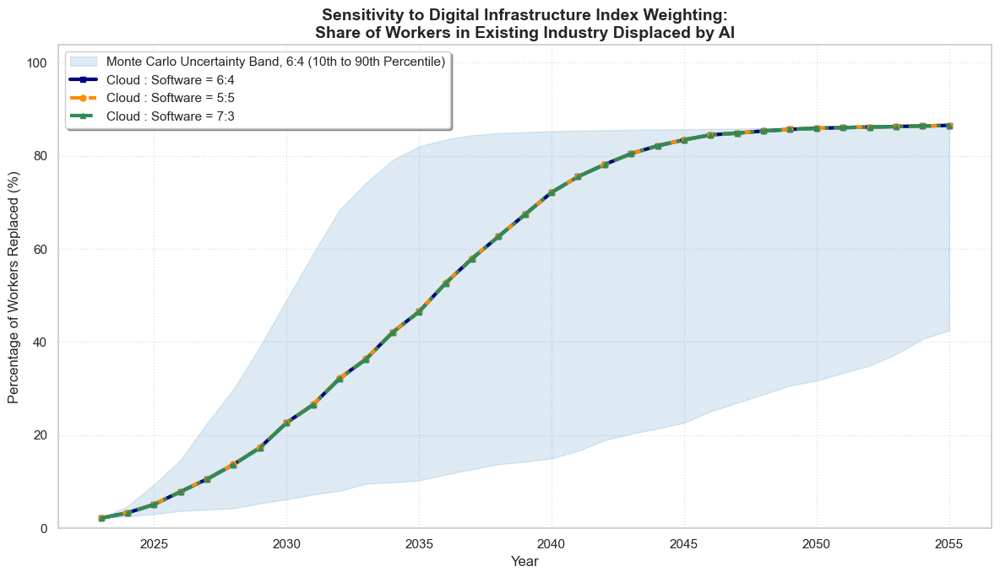


Graph saved: 20260818_233448_DII_Weight_Sensitivity_Displacement_Ratio.png


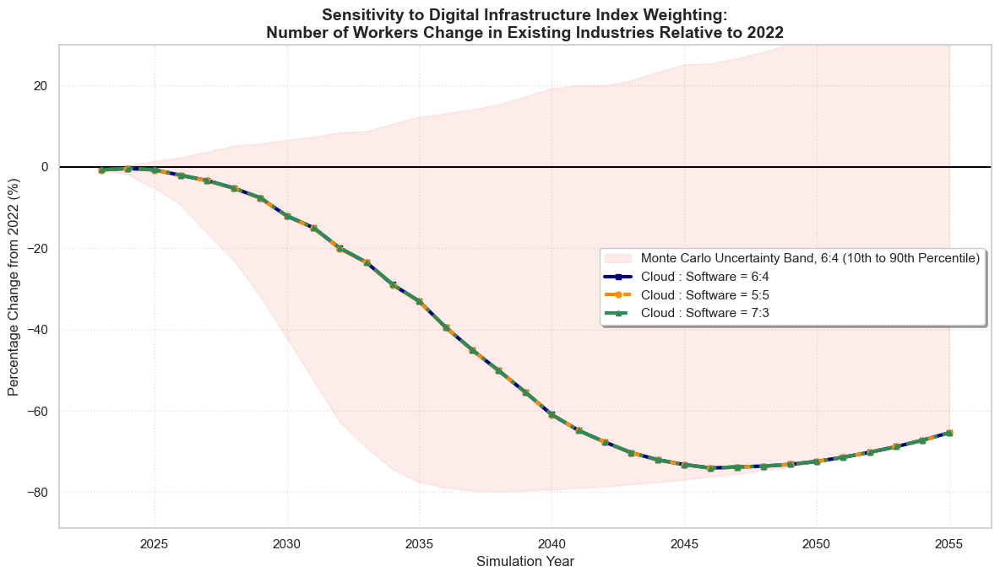

Graph saved: 20260818_233448_DII_Weight_Sensitivity_Net_Employment_Change.png
CSV saved: 20260818_233448_DII_Weight_Sensitivity_Summary.csv

SUMMARY: DISPLACEMENT RATIO (%) BY CLOUD : SOFTWARE WEIGHTING
Year               6:4           5:5           7:3
--------------------------------------------------
2030             22.66         22.72         22.61
2035             46.53         46.57         46.49
2040             72.15         72.16         72.13
2045             83.44         83.45         83.44
2055             86.54         86.54         86.54

SUMMARY: NET EMPLOYMENT CHANGE FROM 2022 (%) BY CLOUD : SOFTWARE WEIGHTING
Year               6:4           5:5           7:3
--------------------------------------------------
2030            -12.06        -12.12        -12.00
2035            -33.07        -33.12        -33.02
2040            -60.92        -60.93        -60.90
2045            -73.20        -73.21        -73.19
2055            -65.38        -65.38        -65.38


In [3]:
# =============================================================================
# NEXT CELL: SENSITIVITY ANALYSIS OF THE DII CLOUD : SOFTWARE WEIGHTING
# Re-runs the dynamic simulation for w1:w2 = 6:4, 5:5, 7:3 and outputs
#   (1) Share of workers in existing industry displaced by AI
#   (2) Number of workers change relative to 2022
# as graphs and a single CSV. The preceding cell is NOT modified; all objects
# built there (df_sim_ready, df_yearly_industry_tech_potential, scaler_all,
# poisson_regression_slopes, baseline_2022_susb_lookup, ...) are reused as is.
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# ---- Weighting scenarios to test: (cloud weight, software weight) ----
DII_WEIGHT_SCENARIOS = [(0.6, 0.4), (0.5, 0.5), (0.7, 0.3)]
BASELINE_WEIGHT_SCENARIO = (0.6, 0.4)


def _scenario_label(a, b):
    """'6:4' style label from (0.6, 0.4)."""
    return f"{int(round(a * 10))}:{int(round(b * 10))}"


def _load_diffusion_stats_for_weights(a, b):
    """
    The diffusion speed table was estimated under a specific cloud:software
    weighting. Use the matching file when it exists (e.g. DX_Adoption_Speed_K_5_5.csv);
    otherwise fall back to the table already loaded in the previous cell.
    """
    candidate = f"DX_Adoption_Speed_K_{int(round(a * 10))}_{int(round(b * 10))}.csv"
    if os.path.exists(candidate):
        df_k = pd.read_csv(candidate, dtype={'NAICS': str})
        df_k['NAICS'] = df_k['NAICS'].apply(standardize_naics_code_to_6_digits)
        print(f"   diffusion speed table: {candidate}")
        return df_k
    print(f"   diffusion speed table: '{candidate}' not found -> reusing "
          f"'{FILE_PATH_DYNAMIC_DIFFUSION_STATS}' (k held fixed across weightings)")
    return df_dynamic_diffusion_stats


# Pre-build a fast lookup for the industry-year technical potential table.
# Same values as the DataFrame filtering used in the previous cell, just indexed.
_industry_year_lookup = {
    (r['NAICS'], r['Year']): r
    for _, r in df_yearly_industry_tech_potential.iterrows()
}

# Pre-build a fast lookup for the diffusion parameters keyed by (NAICS, size).
def _build_diffusion_lookup(df_k):
    return {
        (r['NAICS'], r['Company_Size']): r
        for _, r in df_k.iterrows()
    }


def _replay_ai_evolution_rng():
    """
    Re-seed and consume exactly the same lognormal draws that the AI evolution
    speed (V) simulation consumed in the previous cell, so that the subsequent
    diffusion-speed (K) draws reproduce the original random sequence.
    V itself does not depend on the DII weighting, so the drawn values are discarded.
    """
    np.random.seed(MONTE_CARLO_RANDOM_SEED)
    for simulation_year in SIMULATION_TIME_STEPS_RANGE:
        if simulation_year == SIMULATION_START_YEAR:
            continue
        mu_v, sigma_v = convert_arithmetic_to_lognormal_parameters(
            target_arithmetic_mean=AI_EVOLUTION_SPEED_MU,
            target_arithmetic_sigma=AI_EVOLUTION_SPEED_SIGMA
        )
        np.random.lognormal(mean=mu_v, sigma=sigma_v, size=AI_EVOLUTION_SPEED_REPLICATES)


def run_simulation_for_dii_weights(weight_cloud, weight_software):
    """
    Re-runs PART 6 of the previous cell with a different cloud:software weighting
    and returns the macro (Company_Size == 'All') aggregate time series.
    Everything except w1/w2 and the DII normalisation bounds is unchanged.
    """
    df_k_stats = _load_diffusion_stats_for_weights(weight_cloud, weight_software)
    diffusion_lookup = _build_diffusion_lookup(df_k_stats)

    # --- Recompute the DII min/max normalisation bounds under the new weights ---
    z_reference_scores = []
    for _, row_ref in df_dri_base.iterrows():
        zv = scaler_all.transform([[row_ref['c_avg'], row_ref['s_avg']]])[0]
        z_reference_scores.append(zv[0] * weight_cloud + zv[1] * weight_software)
    dii_min_local = min(z_reference_scores)
    dii_max_local = max(z_reference_scores)
    dii_range_local = dii_max_local - dii_min_local

    # Reproduce the original random sequence before the diffusion draws begin
    _replay_ai_evolution_rng()

    records = []

    for _, industry_row in df_sim_ready.iterrows():
        naics_key = industry_row['NAICS']
        ws, wl = industry_row['w_sme'], industry_row['w_large']

        total_firms = ws + wl
        firm_share_l = wl / total_firms if total_firms > 0 else 0.5
        cur_cl_gap, cur_sf_gap = cl_gap_nat, sf_gap_nat

        def decomp(avg, gap, share_l):
            s = avg / ((1 - share_l) + (share_l * gap))
            return s, min(1.0, s * gap)

        cs, cl = decomp(industry_row['c_avg'], cur_cl_gap, firm_share_l)
        ss, sl = decomp(industry_row['s_avg'], cur_sf_gap, firm_share_l)

        # All three size categories are simulated so that the random draw
        # sequence matches the previous cell exactly; only 'All' is aggregated.
        for sz_cat, cv, sv in [(LABEL_SIZE_ALL, industry_row['c_avg'], industry_row['s_avg']),
                               (LABEL_SIZE_SME, cs, ss),
                               (LABEL_SIZE_LARGE, cl, sl)]:

            baseline_2022 = np.nan
            for specificity_level in range(6, 1, -1):
                key = (naics_key[:specificity_level].ljust(6, '0'), sz_cat)
                if key in baseline_2022_susb_lookup:
                    baseline_2022 = baseline_2022_susb_lookup[key]
                    break
            if pd.isna(baseline_2022) or baseline_2022 == 0:
                continue

            slope_final = 0.0
            for specificity_level in range(6, 1, -1):
                key = (naics_key[:specificity_level].ljust(6, '0'), sz_cat)
                if key in poisson_regression_slopes:
                    slope_final = poisson_regression_slopes[key].get('applied_slope', 0.0)
                    break

            # DII anchor under the current weighting
            zv_anchor = scaler_all.transform([[cv, sv]])[0]
            dii_z_score_initial = zv_anchor[0] * weight_cloud + zv_anchor[1] * weight_software
            dii_normalized_anchor = max(
                MINIMUM_DII,
                min(1, (dii_z_score_initial - dii_min_local) / dii_range_local)
            )

            diffusion_row = diffusion_lookup.get((naics_key, sz_cat))
            if diffusion_row is not None:
                diffusion_speed_mu_k = float(diffusion_row['diffusion_speed_k'])
                raw_firm_count = diffusion_row['Number_of_Firms']
                if pd.isna(raw_firm_count) or raw_firm_count <= 0:
                    number_of_firms_for_replicates = STANDARD_SIMULATION_REPLICATE_COUNT
                else:
                    number_of_firms_for_replicates = int(raw_firm_count)
            else:
                diffusion_speed_mu_k = 0.0
                number_of_firms_for_replicates = STANDARD_SIMULATION_REPLICATE_COUNT

            diffusion_speed_sigma_k = DIGITAL_INFRA_DIFFUSION_SPEED_K_SIGMA_DICT.get(sz_cat, 0.0)

            cum_k_mean = 0.0
            cum_k_lower = 0.0
            cum_k_upper = 0.0

            for yr in SIMULATION_TIME_STEPS_RANGE:
                industry_yearly_match = _industry_year_lookup.get((naics_key, yr))
                if industry_yearly_match is None:
                    continue

                potential_mean = industry_yearly_match['Industry_Potential_At_T']
                potential_lower = industry_yearly_match['Industry_Potential_At_T_Lower_Bound']
                potential_upper = industry_yearly_match['Industry_Potential_At_T_Upper_Bound']

                share_replaceable_mean = industry_yearly_match['Industry_Fully_Replaceable_Workforce_Share_At_T']
                share_replaceable_lower = industry_yearly_match['Industry_Fully_Replaceable_Workforce_Share_At_T_Lower_Bound']
                share_replaceable_upper = industry_yearly_match['Industry_Fully_Replaceable_Workforce_Share_At_T_Upper_Bound']

                if yr > SIMULATION_START_YEAR:
                    mu_k, sigma_k = convert_arithmetic_to_lognormal_parameters(
                        target_arithmetic_mean=diffusion_speed_mu_k,
                        target_arithmetic_sigma=diffusion_speed_sigma_k
                    )
                    simulated_k = np.random.lognormal(
                        mean=mu_k, sigma=sigma_k, size=number_of_firms_for_replicates
                    )
                    cum_k_mean += np.mean(simulated_k)
                    cum_k_lower += np.percentile(simulated_k, PERCENTILE_VALUE_FOR_LOWER_BOUND)
                    cum_k_upper += np.percentile(simulated_k, PERCENTILE_VALUE_FOR_UPPER_BOUND)

                d0_limit = max(MINIMUM_DII, min(1 - MINIMUM_DII, dii_normalized_anchor))

                def calc_logistic_dii(cumulative_exponent):
                    return 1 / (1 + ((1 - d0_limit) / d0_limit) * np.exp(-cumulative_exponent))

                dt_t_mean = calc_logistic_dii(cum_k_mean)
                dt_t_lower = calc_logistic_dii(cum_k_lower)
                dt_t_upper = calc_logistic_dii(cum_k_upper)

                emp_proj = baseline_2022 * np.exp(slope_final * (yr - 2022))

                replaced_mean = share_replaceable_mean * dt_t_mean * emp_proj
                replaced_lower = share_replaceable_lower * dt_t_lower * emp_proj
                replaced_upper = share_replaceable_upper * dt_t_upper * emp_proj

                # Only the 'All' branch feeds the macro aggregate
                if sz_cat == LABEL_SIZE_ALL:
                    records.append({
                        'Year': yr,
                        'Employment_Baseline_Projected': emp_proj,
                        'Employment_Actual_2022': baseline_2022,
                        'Employment_Replaced_S2': replaced_mean,
                        'Employment_Replaced_S2_Lower_Bound': replaced_lower,
                        'Employment_Replaced_S2_Upper_Bound': replaced_upper,
                    })

    df_macro = pd.DataFrame(records).groupby('Year').sum().reset_index()

    # (1) Share of workers in existing industry displaced by AI
    df_macro['Macro_Replacement_Ratio_Percent'] = (
        df_macro['Employment_Replaced_S2'] / df_macro['Employment_Baseline_Projected']) * 100
    df_macro['Macro_Replacement_Ratio_Percent_Lower_Bound'] = (
        df_macro['Employment_Replaced_S2_Lower_Bound'] / df_macro['Employment_Baseline_Projected']) * 100
    df_macro['Macro_Replacement_Ratio_Percent_Upper_Bound'] = (
        df_macro['Employment_Replaced_S2_Upper_Bound'] / df_macro['Employment_Baseline_Projected']) * 100

    # (2) Number of workers change relative to 2022
    remaining_mean = df_macro['Employment_Baseline_Projected'] - df_macro['Employment_Replaced_S2']
    remaining_low_impact = df_macro['Employment_Baseline_Projected'] - df_macro['Employment_Replaced_S2_Lower_Bound']
    remaining_high_impact = df_macro['Employment_Baseline_Projected'] - df_macro['Employment_Replaced_S2_Upper_Bound']

    df_macro['Macro_Net_Change_From_2022_Percent'] = (
        (remaining_mean - df_macro['Employment_Actual_2022']) / df_macro['Employment_Actual_2022']) * 100
    # Higher displacement impact -> lower (more negative) net change
    df_macro['Macro_Net_Change_From_2022_Percent_Lower_Bound'] = (
        (remaining_high_impact - df_macro['Employment_Actual_2022']) / df_macro['Employment_Actual_2022']) * 100
    df_macro['Macro_Net_Change_From_2022_Percent_Upper_Bound'] = (
        (remaining_low_impact - df_macro['Employment_Actual_2022']) / df_macro['Employment_Actual_2022']) * 100

    return df_macro


# =============================================================================
# RUN ALL WEIGHTING SCENARIOS
# =============================================================================
print("=" * 80)
print("SENSITIVITY ANALYSIS: DIGITAL INFRASTRUCTURE INDEX CLOUD : SOFTWARE WEIGHTING")
print("=" * 80)

results_by_weight_scenario = {}
for weight_cloud, weight_software in DII_WEIGHT_SCENARIOS:
    label = _scenario_label(weight_cloud, weight_software)
    print(f"\n-> Running cloud:software = {label} (w1={weight_cloud}, w2={weight_software})")
    results_by_weight_scenario[label] = run_simulation_for_dii_weights(weight_cloud, weight_software)
    print(f"   done ({len(results_by_weight_scenario[label])} simulation years)")

BASELINE_LABEL = _scenario_label(*BASELINE_WEIGHT_SCENARIO)

# Colour / style per weighting scenario
SCENARIO_PLOT_STYLE = {
    '6:4': {'color': 'navy',      'linestyle': '-',  'marker': 's'},
    '5:5': {'color': 'darkorange', 'linestyle': '--', 'marker': 'o'},
    '7:3': {'color': 'seagreen',  'linestyle': '-.', 'marker': '^'},
}

sensitivity_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# =============================================================================
# GRAPH A: SHARE OF WORKERS IN EXISTING INDUSTRY DISPLACED BY AI
# =============================================================================
plt.figure(figsize=(12, 7))

# Monte Carlo band shown for the baseline weighting only, for readability
df_baseline_macro = results_by_weight_scenario[BASELINE_LABEL]
plt.fill_between(
    df_baseline_macro['Year'],
    df_baseline_macro['Macro_Replacement_Ratio_Percent_Lower_Bound'],
    df_baseline_macro['Macro_Replacement_Ratio_Percent_Upper_Bound'],
    color='tab:blue', alpha=0.15,
    label=f'Monte Carlo Uncertainty Band, {BASELINE_LABEL} (10th to 90th Percentile)'
)

for label, df_macro_scenario in results_by_weight_scenario.items():
    style = SCENARIO_PLOT_STYLE.get(label, {})
    plt.plot(
        df_macro_scenario['Year'], df_macro_scenario['Macro_Replacement_Ratio_Percent'],
        lw=3, markersize=5,
        label=f'Cloud : Software = {label}',
        **style
    )

plt.title("Sensitivity to Digital Infrastructure Index Weighting:\n"
          "Share of Workers in Existing Industry Displaced by AI",
          fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Percentage of Workers Replaced (%)", fontsize=12)
max_displacement_across_scenarios = max(
    df['Macro_Replacement_Ratio_Percent'].max() for df in results_by_weight_scenario.values()
)
plt.ylim(0, max(10, max_displacement_across_scenarios * 1.2))
plt.legend(fontsize=11, frameon=True, shadow=True, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
graph_a_filename = f"{sensitivity_timestamp}_DII_Weight_Sensitivity_Displacement_Ratio.png"
plt.savefig(graph_a_filename, dpi=300)
plt.show()
print(f"\nGraph saved: {graph_a_filename}")

# =============================================================================
# GRAPH B: NUMBER OF WORKERS CHANGE RELATIVE TO 2022
# =============================================================================
plt.figure(figsize=(12, 7))

plt.fill_between(
    df_baseline_macro['Year'],
    df_baseline_macro['Macro_Net_Change_From_2022_Percent_Lower_Bound'],
    df_baseline_macro['Macro_Net_Change_From_2022_Percent_Upper_Bound'],
    color='salmon', alpha=0.15,
    label=f'Monte Carlo Uncertainty Band, {BASELINE_LABEL} (10th to 90th Percentile)'
)

plt.axhline(0, color='black', linewidth=1.5, linestyle='-')

for label, df_macro_scenario in results_by_weight_scenario.items():
    style = SCENARIO_PLOT_STYLE.get(label, {})
    plt.plot(
        df_macro_scenario['Year'], df_macro_scenario['Macro_Net_Change_From_2022_Percent'],
        lw=3, markersize=5,
        label=f'Cloud : Software = {label}',
        **style
    )

plt.title("Sensitivity to Digital Infrastructure Index Weighting:\n"
          "Number of Workers Change in Existing Industries Relative to 2022",
          fontsize=14, fontweight='bold')
plt.xlabel("Simulation Year", fontsize=12)
plt.ylabel("Percentage Change from 2022 (%)", fontsize=12)
max_net_change = max(df['Macro_Net_Change_From_2022_Percent'].max() for df in results_by_weight_scenario.values())
min_net_change = min(df['Macro_Net_Change_From_2022_Percent'].min() for df in results_by_weight_scenario.values())
plt.ylim(min(-10, min_net_change * 1.2), max(30, max_net_change * 1.2))
plt.legend(fontsize=11, frameon=True, shadow=True, loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
graph_b_filename = f"{sensitivity_timestamp}_DII_Weight_Sensitivity_Net_Employment_Change.png"
plt.savefig(graph_b_filename, dpi=300)
plt.show()
print(f"Graph saved: {graph_b_filename}")

# =============================================================================
# CSV EXPORT: ALL WEIGHTING SCENARIOS SIDE BY SIDE
# =============================================================================
export_columns = [
    'Macro_Replacement_Ratio_Percent',
    'Macro_Replacement_Ratio_Percent_Lower_Bound',
    'Macro_Replacement_Ratio_Percent_Upper_Bound',
    'Macro_Net_Change_From_2022_Percent',
    'Macro_Net_Change_From_2022_Percent_Lower_Bound',
    'Macro_Net_Change_From_2022_Percent_Upper_Bound',
]

df_sensitivity_export = None
for label, df_macro_scenario in results_by_weight_scenario.items():
    suffix = label.replace(':', '_')
    df_part = df_macro_scenario[['Year'] + export_columns].copy()
    df_part = df_part.rename(columns={c: f'{c}_Cloud_Software_{suffix}' for c in export_columns})
    df_sensitivity_export = df_part if df_sensitivity_export is None else \
        df_sensitivity_export.merge(df_part, on='Year', how='outer')

csv_filename = f"{sensitivity_timestamp}_DII_Weight_Sensitivity_Summary.csv"
df_sensitivity_export.to_csv(csv_filename, index=False, encoding='utf-8-sig')

print(f"CSV saved: {csv_filename}")

# Console summary at key milestone years
print("\n" + "=" * 80)
print("SUMMARY: DISPLACEMENT RATIO (%) BY CLOUD : SOFTWARE WEIGHTING")
print("=" * 80)
milestone_years = [y for y in [2030, 2035, 2040, 2045, 2055] if y <= SIMULATION_END_YEAR]
header = f"{'Year':<8}" + "".join(f"{lbl:>14}" for lbl in results_by_weight_scenario)
print(header)
print("-" * len(header))
for y in milestone_years:
    line = f"{y:<8}"
    for label, df_macro_scenario in results_by_weight_scenario.items():
        row = df_macro_scenario[df_macro_scenario['Year'] == y]
        line += f"{row['Macro_Replacement_Ratio_Percent'].iloc[0]:>14.2f}" if not row.empty else f"{'-':>14}"
    print(line)

print("\n" + "=" * 80)
print("SUMMARY: NET EMPLOYMENT CHANGE FROM 2022 (%) BY CLOUD : SOFTWARE WEIGHTING")
print("=" * 80)
print(header)
print("-" * len(header))
for y in milestone_years:
    line = f"{y:<8}"
    for label, df_macro_scenario in results_by_weight_scenario.items():
        row = df_macro_scenario[df_macro_scenario['Year'] == y]
        line += f"{row['Macro_Net_Change_From_2022_Percent'].iloc[0]:>14.2f}" if not row.empty else f"{'-':>14}"
    print(line)
print("=" * 80)

1. Estimating baseline employment trends and scale ratios from SUSB...
2. Simulating expansion of AI Exposure at occupation level...
3. Anchoring industry-average digital infrastructure index (Cloud & Software)...

IMPUTATION SUMMARY BY INDUSTRY (Cloud & Software)
 - Original: 277 industries

4. Executing final dynamic simulation...
Successfully loaded dynamic diffusion stats (d).
Mapping SUSB weights using hierarchical search for range codes (e.g., 44-45)...
SUSB weight hierarchical mapping complete.
Validated SUSB weight mapping complete.

Check Complete: All industries successfully matched with diffusion speed data.


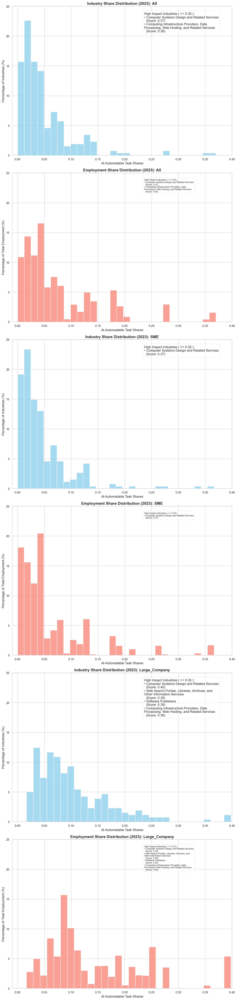

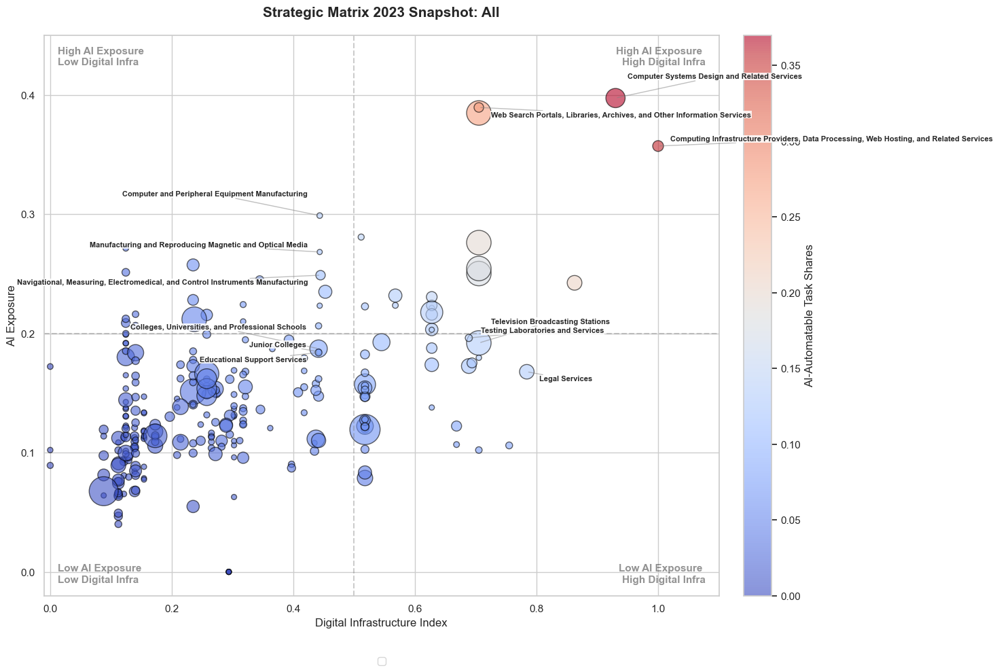

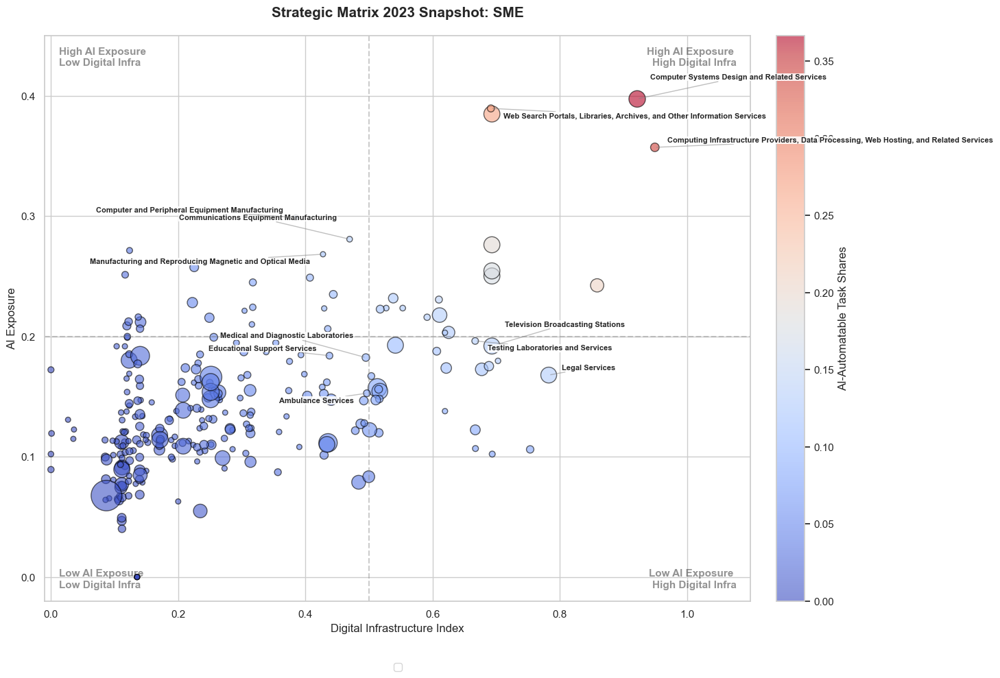

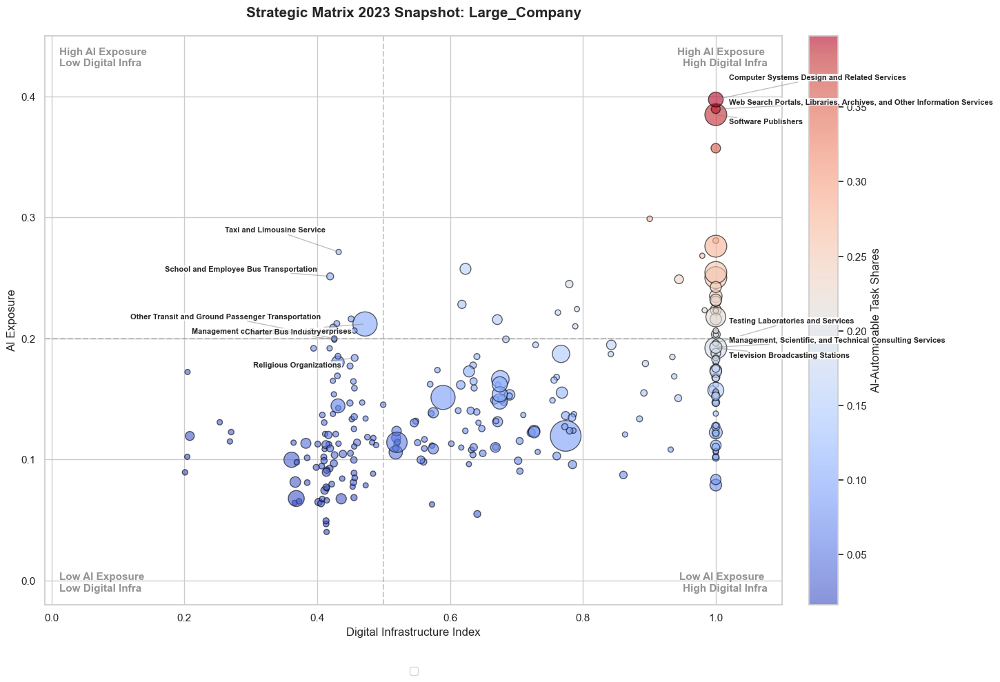


                      TOP 20 INDUSTRIES: HIGHEST AI-Automatable Task Shares (2025)                       
NAICS_TITLE                                                                      | AI-Automatable Task Shares
---------------------------------------------------------------------------------------------------------
Computer Systems Design and Related Services                                     |             0.502588
Computing Infrastructure Providers, Data Processing, Web Hosting, and Relat...   |             0.464305
Web Search Portals, Libraries, Archives, and Other Information Services          |             0.432637
Software Publishers                                                              |             0.426644
Accounting, Tax Preparation, Bookkeeping, and Payroll Services                   |             0.313619
Media Streaming Distribution Services, Social Networks, and Other Media Net...   |             0.311371
Radio Broadcasting Stations                          

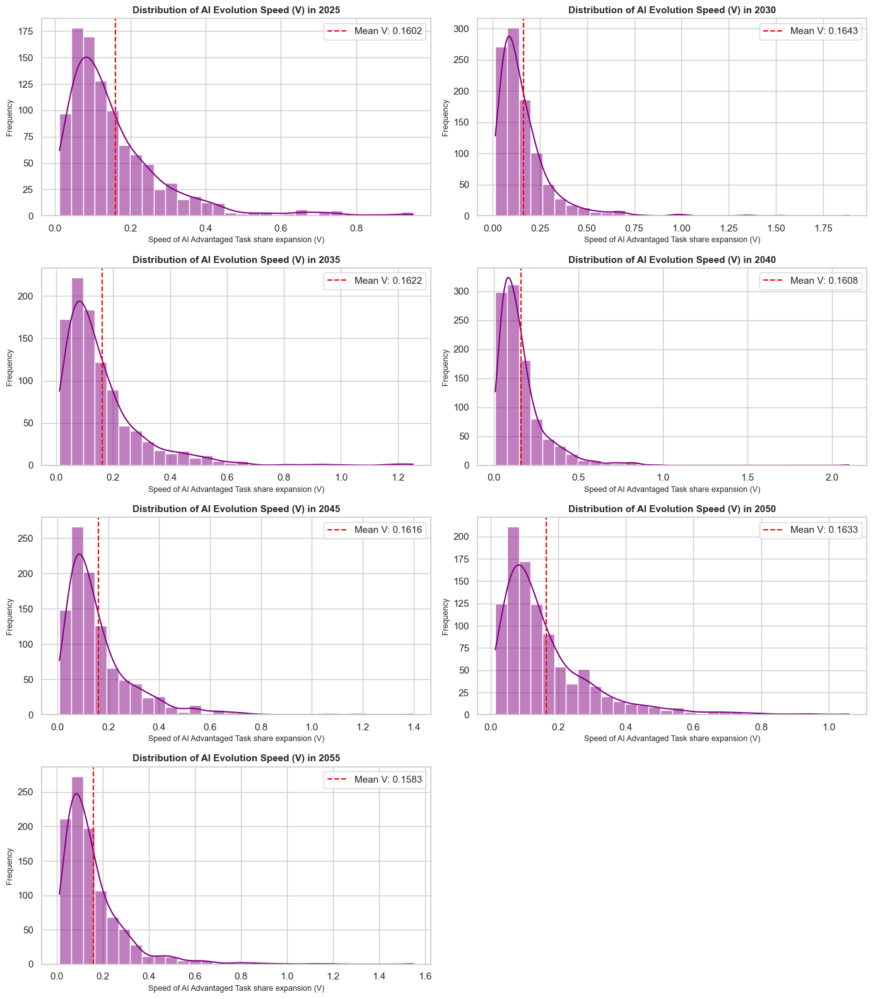

Aggregated V histograms saved to: 20261107_215227_Grid_Distribution_V_2025_to_2055.png


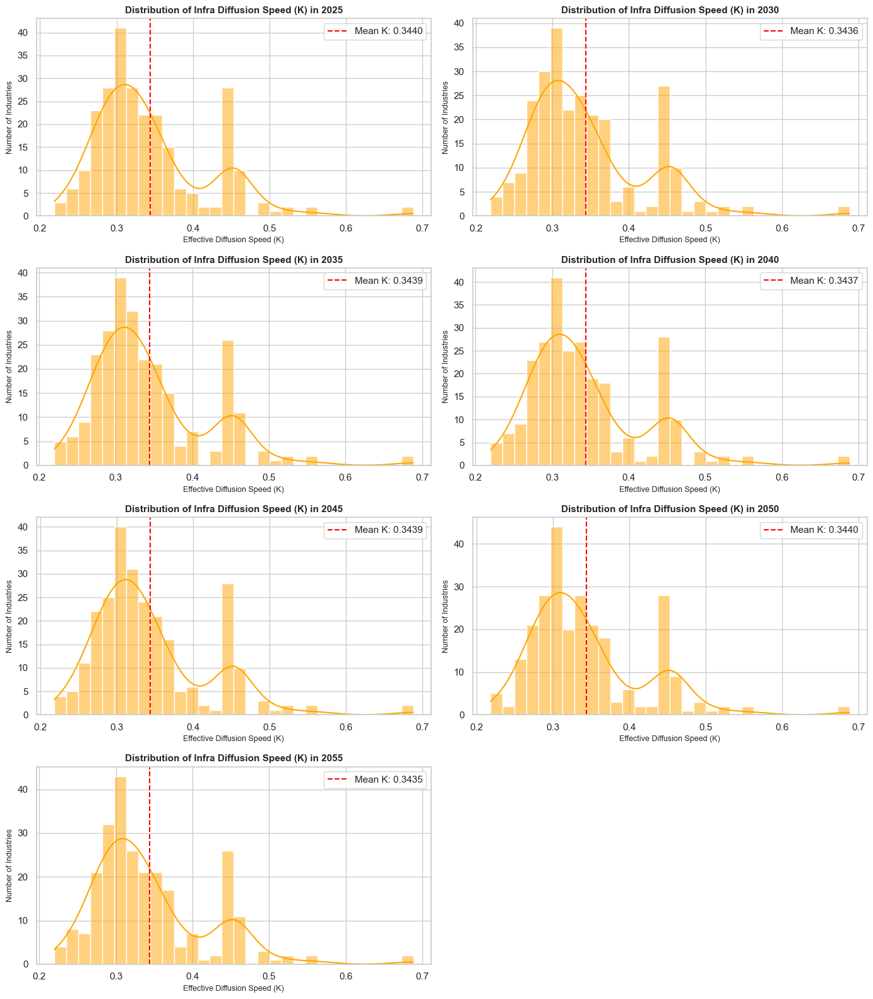

Aggregated K histograms saved to: 20261107_215227_Grid_Distribution_K_2025_to_2055.png

ANNUAL EMPLOYMENT REPLACEMENT REPORT (Baseline Scenario)
Detailed annual counts and ratios saved to: 20261107_215253_Annual_Employment_Replaced_by_AI.csv
Generating trajectory line graph for metrics...


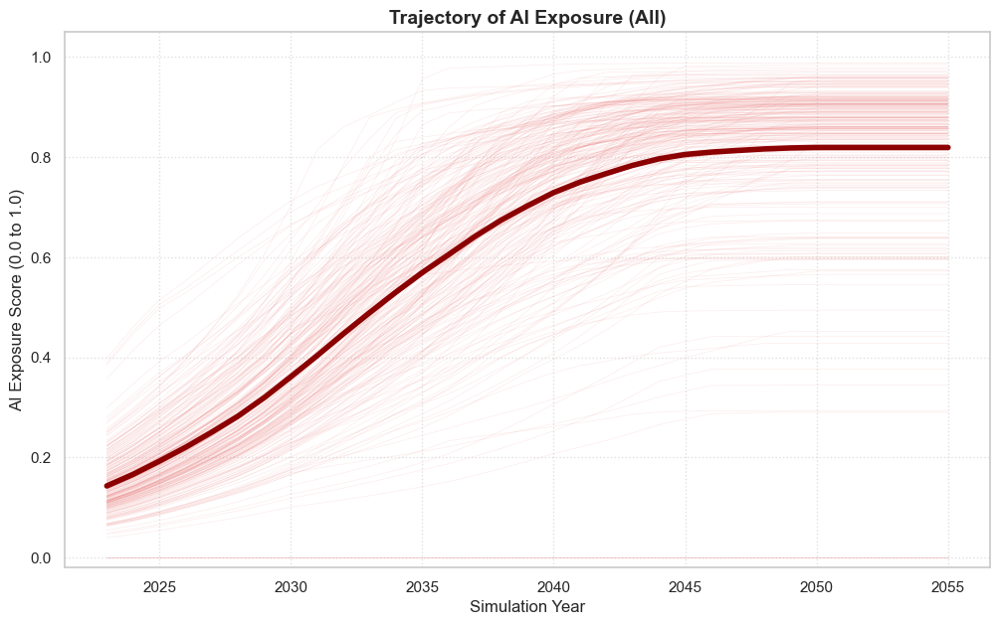

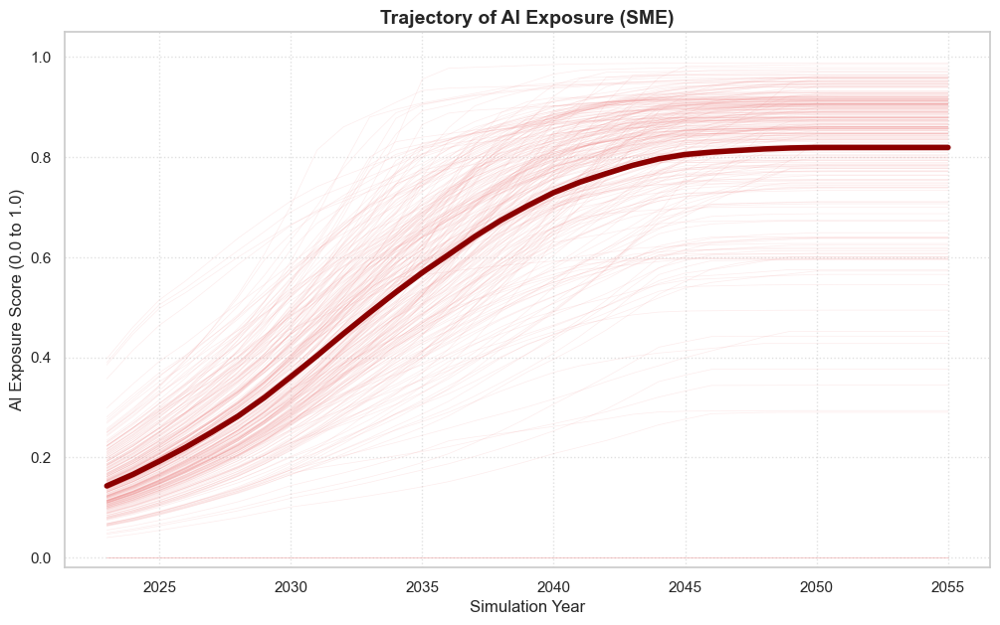

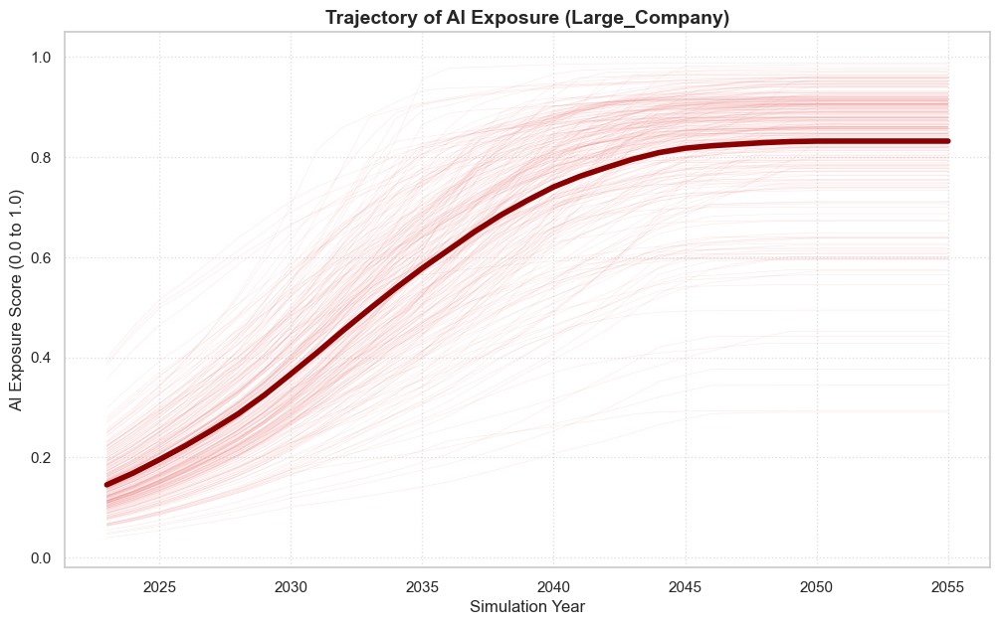

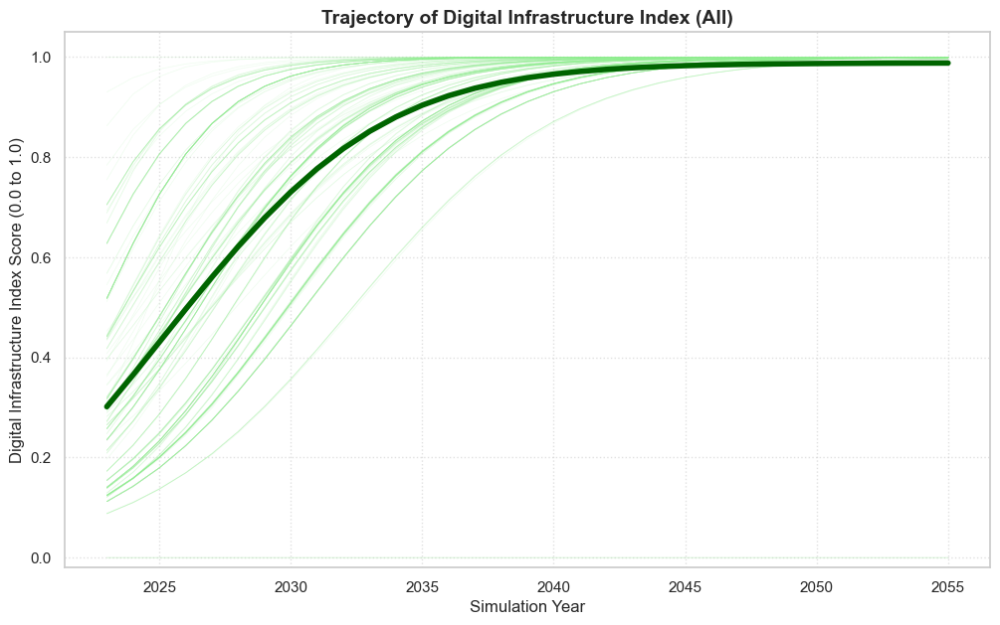

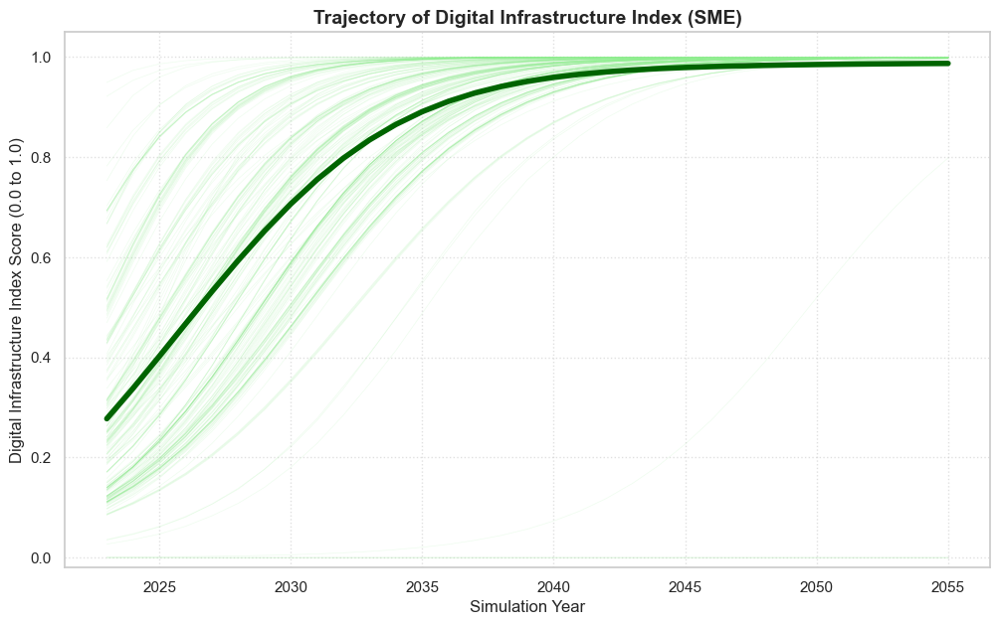

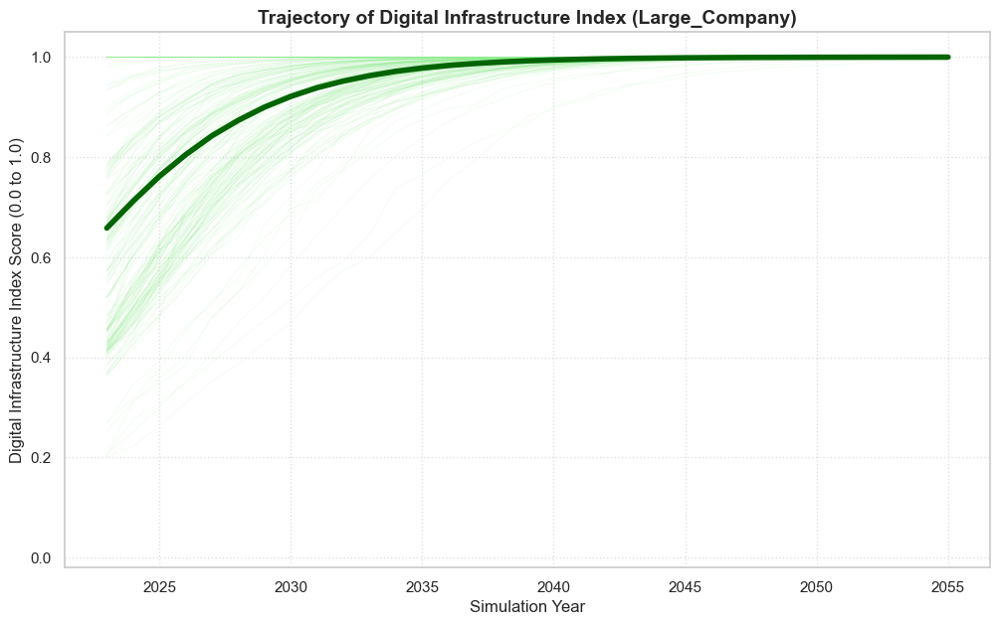

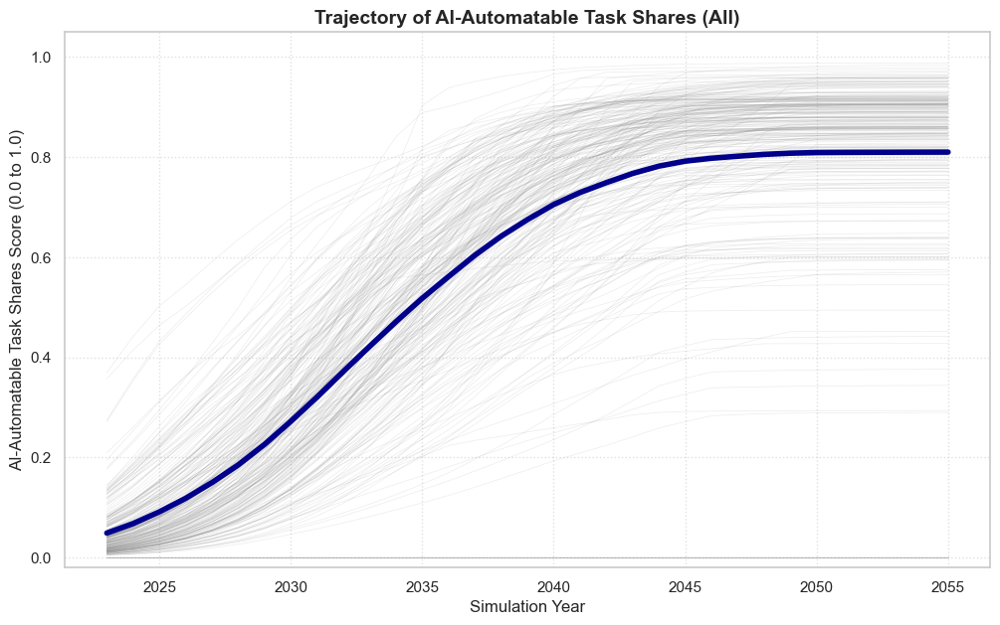

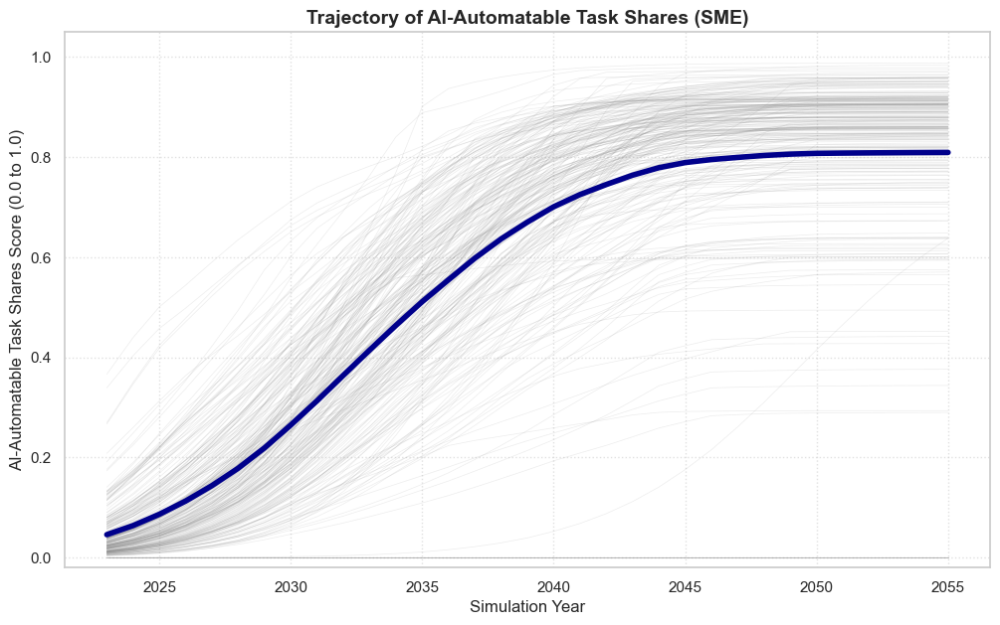

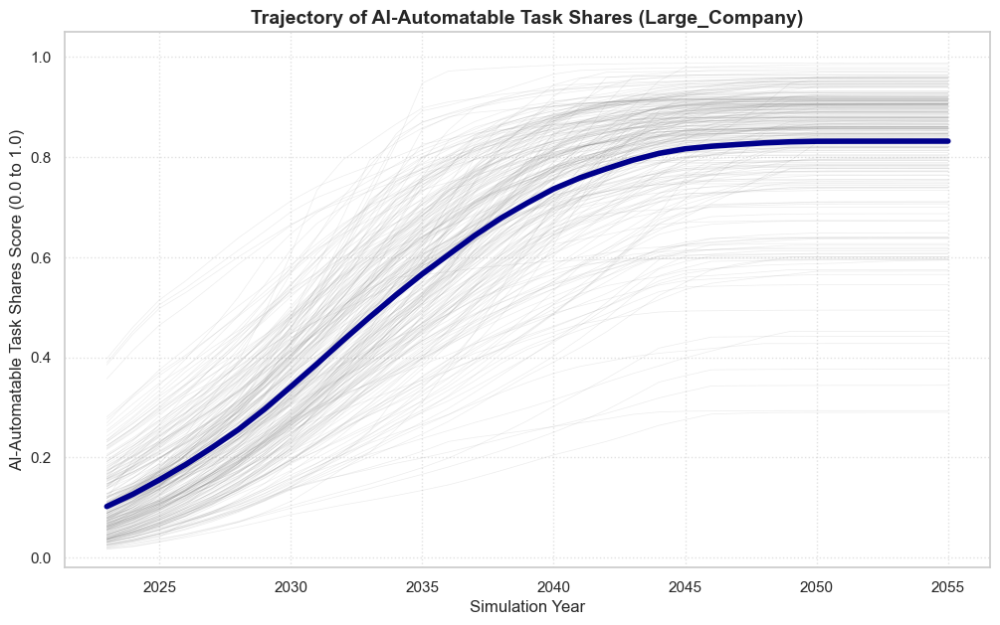

Trajectory line graphs have been displayed and saved with prefix: 20261107_215227_Impact_Trajectory_
Displaying annual industry distribution histograms in console...


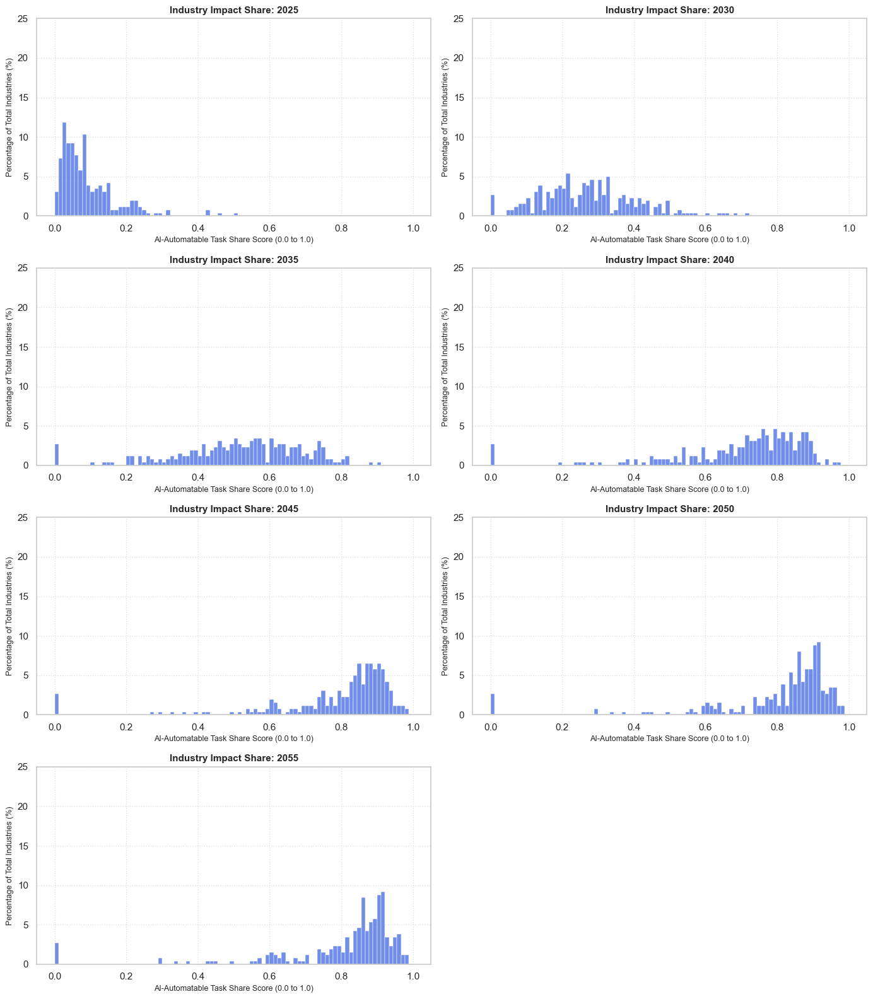

Aggregated annual histograms saved to: 20261107_215227_Grid_Histograms_2025_to_2055.png
Generating Macro Projection with industry-specific lines...


<Figure size 1200x700 with 0 Axes>

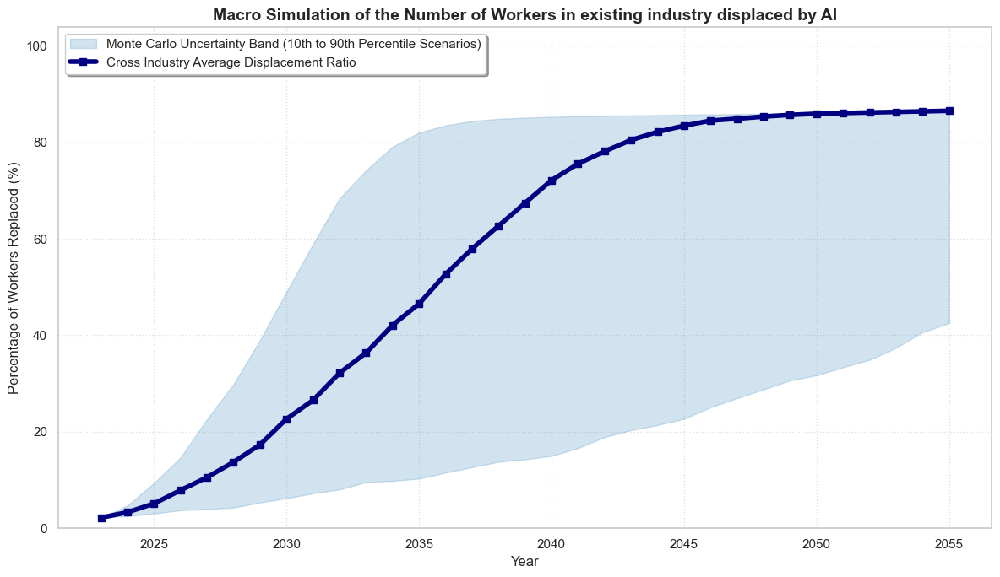

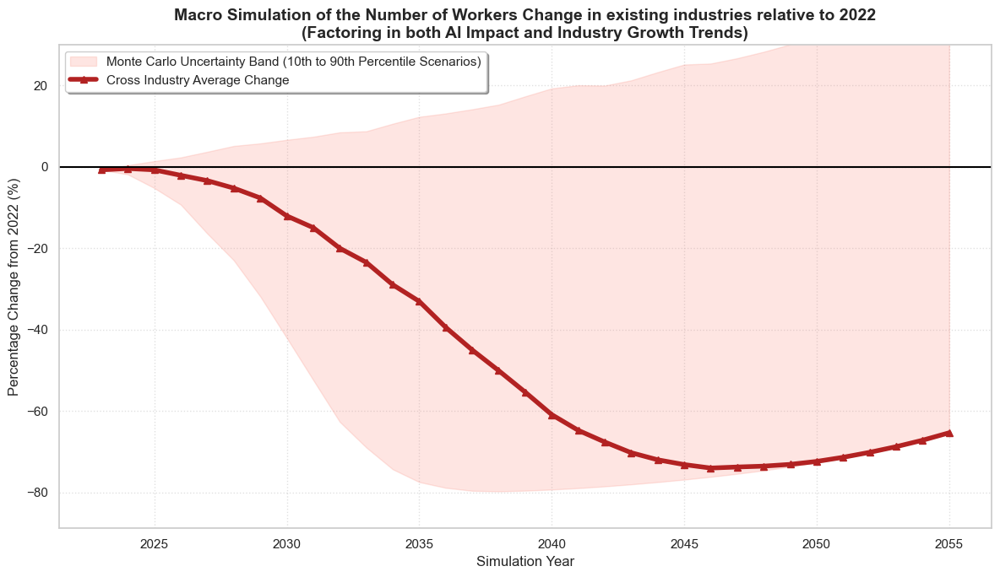

Generating Macro Projection for Sensitivity Analysis (Displacement)...


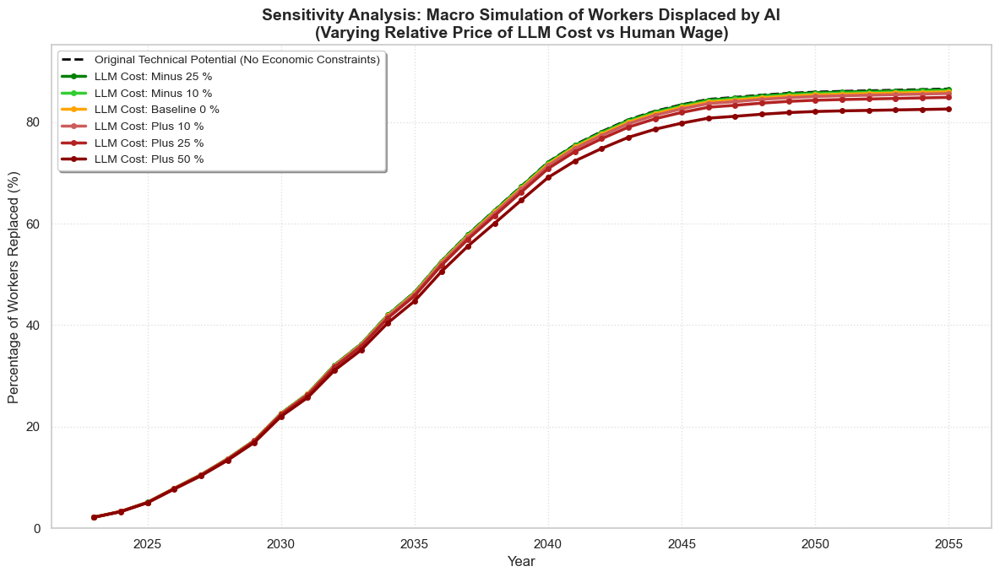

Generating Macro Projection for Sensitivity Analysis (Net Employment Change)...


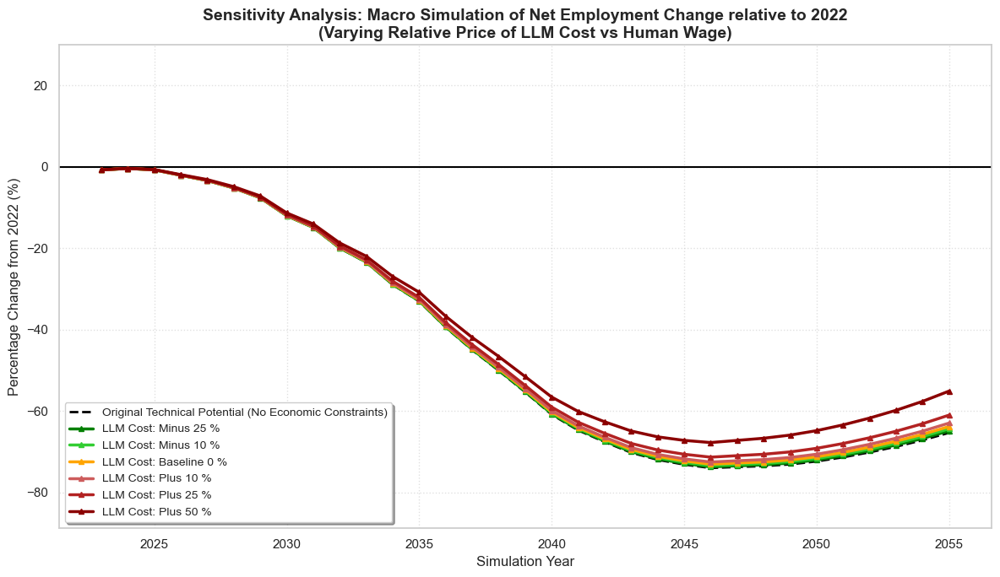

Appending 2023 Strategic Quadrant labels to the final dataset...

ANALYSIS COMPLETE: Results saved as 20261107_215319_AI_Impact_Analysis_MonteCarlo.csv

FINAL INDUSTRY COUNT SUMMARY
Total number of unique industries (NAICS) included in the final analysis: 261
Exporting national macro aggregate summary...
Macro summary saved to: 20261107_215319_Macro_Employment_Summary.csv
Generating applied historical growth slope summary report...
Historical growth slope report saved as: 20261107_215319_Applied_Historical_Employment_Slopes.csv


In [2]:
#=====Static analysis & Dynamic analysis:Only cloud usage, special software usage===
#=== replace condition: Occ level AI advantage task share>=0.5 employment trends cloud;software=6;4 === 
#=== monte calro simulation===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings
import re
import gc
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import matplotlib.patches as patches
import scipy.stats as stats

# =============================================================================
# PART 0: ENVIRONMENT SETTINGS
# =============================================================================

# Suppress warnings from Excel engines and general pandas warnings for cleaner output
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore')

# =============================================================================
# PART 1: GLOBAL PARAMETERS & CONFIGURATION
# =============================================================================
# Define file paths for external datasets (BLS, AI ratings, NSF usage, SUSB weights, and Historical trends)
FILE_PATH_BLS_STAFFING = 'bls_staffing_pattern_exclude_multipler1.csv'
FILE_PATH_OCCUPATION_AI = 'occ_level.csv'
FILE_PATH_NSF_CLOUD = 'nsf25303-tab076.xlsx'
FILE_PATH_NSF_CLOUD_GAP = 'nsf25303-tab077.xlsx'
FILE_PATH_NSF_SOFTWARE = 'nsf25303-tab078.xlsx'
FILE_PATH_NSF_SOFTWARE_GAP = 'nsf25303-tab079.xlsx'
FILE_PATH_SUSB_WEIGHTS = 'Employment_and_Payroll_by_industry_by_companysize_susb_united_states_only.csv'
FILE_PATH_SUSB_HISTORICAL_EMP = 'SUSB_Final_Regression_Data_a_h_i_Only.csv'

# Weights for the Digital Infrastructure Index: 60% Cloud usage, 40% Software usage
w1, w2 = 0.6, 0.4

# Setting Variable Name Constants for consistent referencing throughout the script
NAME_POTENTIAL_AI_EXCELS_AT = "AI Exposure"
NAME_REALIZED_AUTOMATION_IMPACT_S2 = "AI-Automatable Task Shares"  
NAME_DIGITAL_INFRA_INDEX = "Digital Infrastructure Index"

# categorical constants for size grouping
LABEL_SIZE_SME = 'SME'
LABEL_SIZE_LARGE = 'Large_Company'
LABEL_SIZE_ALL = 'All'

# Smallest possible value for Digital Infrastructure to avoid division by zero in logistic formulas
MINIMUM_DII = 1e-9

# Thresholds to categorize industries into strategic quadrants (Low/High Exposure vs Low/High Infra)
STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL = 0.2
STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA = 0.5

NUMBER_OF_TOP_INDUSTRIES_TO_DISPLAY_PER_QUADRANT = 3

# Define the percentile boundaries for the Monte Carlo uncertainty analysis
PERCENTILE_VALUE_FOR_LOWER_BOUND = 10
PERCENTILE_VALUE_FOR_UPPER_BOUND = 90

# Set the timeline for the dynamic simulation
SIMULATION_START_YEAR = 2023
SIMULATION_END_YEAR = 2055
SIMULATION_TIME_STEPS_RANGE = range(SIMULATION_START_YEAR, SIMULATION_END_YEAR + 1)

# Fix the random seed to ensure reproducibility of the simulation results across runs
MONTE_CARLO_RANDOM_SEED = 42

# Parameters for Monte Carlo simulation of AI Evolution Speed (V)
AI_EVOLUTION_SPEED_MU = 0.1594
AI_EVOLUTION_SPEED_SIGMA = 0.1458
AI_EVOLUTION_SPEED_REPLICATES = 1000
OCCUPATION_POTENTIAL_CALC_OFFSET = 0
MAX_32_BIT_INTEGER = 4294967295

# Parameters for Monte Carlo simulation of Digital Infrastructure Diffusion speed (d) 
FILE_PATH_DYNAMIC_DIFFUSION_STATS = 'DX_Adoption_Speed_K_6_4.csv' 
STANDARD_SIMULATION_REPLICATE_COUNT = 1000

# Industry-wide standard deviation (sigma) for K diffusion based on size category
DIGITAL_INFRA_DIFFUSION_SPEED_K_SIGMA_DICT = {
    LABEL_SIZE_ALL: 0.072957,
    LABEL_SIZE_SME: 0.069984,
    LABEL_SIZE_LARGE: 0.473020
}

# Parameters for the discrete displacement logic (N humans replaced by 1 human + AI). N=10 means "1 human + 9 AI = 10 units of output".
MAXIMUM_PRODUCTIVITY_MULTIPLIER_N = 10

# Generate threshold bins: [0.0, 0.5, 0.66, ..., 0.9, 1.0, 1.01]
DISCRETE_PRODUCTIVITY_THRESHOLDS =[1.0 - (1.0 / n) for n in range(1, MAXIMUM_PRODUCTIVITY_MULTIPLIER_N + 1)] +[1.0, 1.01]

# # Corresponding replacement rates: [0.0, 0.5, 0.66, ..., 0.9, 1.0] Eg:At 0.5 threshold, 50% is replaced. At 0.666 threshold, 66.6% is replaced.
DISCRETE_REPLACEMENT_RATES =[1.0 - (1.0 / n) for n in range(1, MAXIMUM_PRODUCTIVITY_MULTIPLIER_N + 1)] + [1.0]

# The grid dimensions and snapshot intervals of the probabilistic distributions of AI Evolution (V) and Infra Diffusion (K)
INTERVAL_YEAR_STEP_SIZE_FOR_MONTE_CARLO = 5
GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO = 2
SNAPSHOT_START_YEAR_FOR_MONTE_CARLO = 2025 # First year to display in the grid

# Generate the list of target years (e.g., 2025, 2030, ..., 2055)
TARGET_YEARS_FOR_MONTE_CARLO_GRID = list(range(SNAPSHOT_START_YEAR_FOR_MONTE_CARLO, SIMULATION_END_YEAR + 1, INTERVAL_YEAR_STEP_SIZE_FOR_MONTE_CARLO))


# =============================================================================
# PART 2: CORE HELPER FUNCTIONS
# =============================================================================

def standardize_naics_code_to_6_digits(code_input):
    """
    Standardizes NAICS codes into a uniform 6-digit string.
    - Removes decimals and extra spaces.
    - If a code is too short (like '44'), it adds zeros to the right (to '440000').
    - Returns an empty string for missing data (NaN).
    """
    if pd.isna(code_input): return ""
    s = str(code_input).strip().split('.')[0]
    return s.ljust(6, '0')

def expand_naics_ranges(raw_string):
    """
    Converts NAICS strings with ranges or commas into a list of individual codes.
    - Example: Converts '44-45' into ['440000', '450000'].
    - Handles shorthand: Converts '313-16' into '313' through '316'.
    - Cleans up different types of dashes and removes the word 'other'.
    """    
    if pd.isna(raw_string): return []
    codes = []
    raw_string = str(raw_string).replace('–', '-').replace('—', '-').replace('−', '-')
    
    for p in raw_string.replace('other ', '').split(','):
        p = p.strip()
        if '-' in p:
            try:
                s, e = p.split('-')
                start_val, end_val = s.strip(), e.strip()
                # Case like 44-45
                if len(start_val) == len(end_val):
                    prefix = ""
                    start_num, end_num = int(start_val), int(end_val)
                # Case like313-16 
                else:
                    prefix = start_val[:-len(end_val)] if len(start_val) > len(end_val) else ""
                    start_num, end_num = int(start_val), int(prefix + end_val)
                
                for i in range(start_num, end_num + 1): 
                    codes.append(standardize_naics_code_to_6_digits(str(i)))
            except: 
                codes.append(standardize_naics_code_to_6_digits(p))
        elif p: 
            codes.append(standardize_naics_code_to_6_digits(p))
    return codes


def convert_arithmetic_to_lognormal_parameters(target_arithmetic_mean, target_arithmetic_sigma):
    """
    Converts real-world average and spread into log-scale math parameters.
    - This is required to generate random numbers that follow a 'Lognormal' distribution.
    - It ensures the simulated results match the target mean and standard deviation.
    """ 
    # Safety check to prevent log of zero
    if target_arithmetic_mean <= 0: return 0.0, 0.0
   
    arithmetic_variance = target_arithmetic_sigma**2
    # Calculate log-scale sigma: sqrt(ln(1 + variance / mean^2))
    log_scale_sigma = np.sqrt(np.log(1 + (arithmetic_variance / (target_arithmetic_mean**2))))
    # Calculate log-scale mu: ln(mean) - 0.5 * log_scale_sigma^2
    log_scale_mu = np.log(target_arithmetic_mean) - 0.5 * (log_scale_sigma**2)
    
    return log_scale_mu, log_scale_sigma    

# Utility to print missing data diagnostics during the data pipeline.
def check_missing_values(df, label):
    print(f"\n{'='*10} MISSING VALUE CHECK: {label} {'='*10}")
    null_counts = df.isnull().sum()
    if null_counts.sum() == 0:
        print("Missing Value: 0 (None)")
    else:
        print("Missing Value Counts per column:")
        print(null_counts[null_counts > 0])
        
        #  Dynamically identify the column names for NAICS codes and titles
        naics_col = 'NAICS' if 'NAICS' in df.columns else ('std_naics' if 'std_naics' in df.columns else None)
        title_col = 'NAICS_TITLE' if 'NAICS_TITLE' in df.columns else None
        
        if naics_col:
            nan_rows = df[df.isnull().any(axis=1)]
            cols_to_show =[naics_col]
            if title_col: cols_to_show.append(title_col)
            print(f"\nFirst 5 unique NAICS with missing values:")
            print(nan_rows[cols_to_show].drop_duplicates().head(5))
    print(f"{'='*40}\n")

# =============================================================================
# PART 3: HISTORICAL TREND & EMPLOYMENT SHARE ANALYSIS
# =============================================================================
print("1. Estimating baseline employment trends and scale ratios from SUSB...")

# Load historical SUSB data to estimate natural industry growth rates
df_hist_raw = pd.read_csv(FILE_PATH_SUSB_HISTORICAL_EMP)
df_hist_raw.columns = df_hist_raw.columns.str.strip()


hist_records =[]
# Loop through years 2012 to 2022 to extract historical employment data
for yr in range(2012, 2023):
    n_c, s_c, e_c = f"NAICS_CODE_{yr}", f"FIRM_SIZE_ALPHA_{yr}", f"Employment_{yr}"

    # Check if the generated column names exist in the raw SUSB dataset
    if n_c in df_hist_raw.columns:
        t = df_hist_raw[[n_c, s_c, e_c]].copy()
        t.columns =['raw_naics', 'firm_size', 'emp']
        t['year'] = yr
        # Format the NAICS code into a standard 6-digit string
        t['std_naics'] = t['raw_naics'].apply(standardize_naics_code_to_6_digits)

        # SUSB uses single letters to represent company size (a=All, h=SME, i=Large)
        SUSB_INDICATOR_ALL_FIRMS = 'a'
        SUSB_INDICATOR_SME = 'h'
        SUSB_INDICATOR_LARGE = 'i'

        # Function to map the SUSB letter codes to internal descriptive labels
        def assign_company_size_category(raw_size_alpha):
            raw_size_lower = str(raw_size_alpha).lower()
            if SUSB_INDICATOR_ALL_FIRMS in raw_size_lower:
                return LABEL_SIZE_ALL
            elif SUSB_INDICATOR_SME in raw_size_lower:
                return LABEL_SIZE_SME
            elif SUSB_INDICATOR_LARGE in raw_size_lower:
                return LABEL_SIZE_LARGE
            else:
                return 'Other'

        # Apply the mapping and keep only rows where employment is greater than zero
        t['sz_cat'] = t['firm_size'].apply(assign_company_size_category)
        hist_records.append(t[t['emp'] > 0])

# Combine all individual yearly dataframes into one master historical dataset
df_hist_master = pd.concat(hist_records)

# Store 2022 employment as the anchor baseline for future projections
baseline_2022_susb_lookup = df_hist_master[df_hist_master['year'] == 2022].set_index(['std_naics', 'sz_cat'])['emp'].to_dict()

poisson_regression_slopes = {}

# Threshold for statistical significance (p-value >= 0.05 is considered stagnant/not significant)
SIGNIFICANCE_THRESHOLD_ALPHA = 0.05
DEFAULT_FALLBACK_GROWTH_SLOPE = 0.0

# Calculate growth slopes using Poisson Regression for every industry-size combination
for industry_group_key, industry_subset_data in df_hist_master.groupby(['std_naics', 'sz_cat']):
    if len(industry_subset_data['year'].unique()) >= 3:
        try:
            # Fit Poisson GLM to estimate historical employment dataset
            poisson_model_fit = smf.glm("emp ~ year", data=industry_subset_data, family=sm.families.Poisson()).fit()
            
            calculated_slope_estimate = poisson_model_fit.params['year']
            statistical_p_value = poisson_model_fit.pvalues['year']

            # If the growth trend is not statistically significant, force it to zero 
            if statistical_p_value >= SIGNIFICANCE_THRESHOLD_ALPHA:
                final_assigned_growth_slope = 0.0
                is_stagnant = True
            else:
                final_assigned_growth_slope = calculated_slope_estimate
                is_stagnant = False

            # Store multiple stats as a dictionary
            poisson_regression_slopes[industry_group_key] = {
                'applied_slope': final_assigned_growth_slope,
                'p_value': statistical_p_value,
                'is_stagnant_flag': is_stagnant
            }
                
        except: 
            poisson_regression_slopes[industry_group_key] = {
                'applied_slope': DEFAULT_FALLBACK_GROWTH_SLOPE,
                'p_value': np.nan,
                'is_stagnant_flag': True
            }
    else: 
        poisson_regression_slopes[industry_group_key] = {
            'applied_slope': DEFAULT_FALLBACK_GROWTH_SLOPE,
            'p_value': np.nan,
            'is_stagnant_flag': True
        }

# =============================================================================
# PART 4: DYNAMIC INDUSTRY AGGREGATION FROM OCCUPATIONS LEVEL SIMULATION
# =============================================================================
print("2. Simulating expansion of AI Exposure at occupation level...")

# Calculate the evolution of AI technical potential at the occupation level over time
df_occ_initial = pd.read_csv(FILE_PATH_OCCUPATION_AI)
df_occ_initial['occ_7'] = df_occ_initial['O*NET-SOC Code'].str[:7]
occ_init_avg = df_occ_initial.groupby('occ_7')['dv_rating_alpha'].mean().reset_index()

# Simulate compounding AI evolution speed (V) using Monte Carlo trials
np.random.seed(MONTE_CARLO_RANDOM_SEED)
# Initialize trackers for the Mean, Lower Bound (10th percentile), and Upper Bound (90th percentile) scenarios
yearly_cumulative_v_multipliers_mean = {}
yearly_cumulative_v_multipliers_lower_bound = {}
yearly_cumulative_v_multipliers_upper_bound = {}

current_cumulative_multiplier_mean = 1.0
current_cumulative_multiplier_lower_bound = 1.0
current_cumulative_multiplier_upper_bound = 1.0

yearly_effective_v = {}  

for simulation_year in SIMULATION_TIME_STEPS_RANGE:
    if simulation_year == SIMULATION_START_YEAR:
        yearly_cumulative_v_multipliers_mean[simulation_year] = 1.0
        yearly_cumulative_v_multipliers_lower_bound[simulation_year] = 1.0
        yearly_cumulative_v_multipliers_upper_bound[simulation_year] = 1.0
        yearly_effective_v[simulation_year] = 0.0  
    else:
        log_scale_mu_v, log_scale_sigma_v = convert_arithmetic_to_lognormal_parameters(
            target_arithmetic_mean=AI_EVOLUTION_SPEED_MU, 
            target_arithmetic_sigma=AI_EVOLUTION_SPEED_SIGMA
        )
        
        simulated_v_trials_array = np.random.lognormal(
            mean=log_scale_mu_v, 
            sigma=log_scale_sigma_v, 
            size=AI_EVOLUTION_SPEED_REPLICATES
        )
        
        # Extract Mean, 10th percentile (slower AI evolution), and 90th percentile (faster AI evolution)
        effective_v_mean_for_this_year = np.mean(simulated_v_trials_array)
        effective_v_lower_bound_for_this_year = np.percentile(simulated_v_trials_array, PERCENTILE_VALUE_FOR_LOWER_BOUND)
        effective_v_upper_bound_for_this_year = np.percentile(simulated_v_trials_array, PERCENTILE_VALUE_FOR_UPPER_BOUND)
                
        # Compound the growth multipliers sequentially for all 3 scenarios
        current_cumulative_multiplier_mean *= (1.0 + effective_v_mean_for_this_year)
        current_cumulative_multiplier_lower_bound *= (1.0 + effective_v_lower_bound_for_this_year)
        current_cumulative_multiplier_upper_bound *= (1.0 + effective_v_upper_bound_for_this_year)
        
        yearly_cumulative_v_multipliers_mean[simulation_year] = current_cumulative_multiplier_mean
        yearly_cumulative_v_multipliers_lower_bound[simulation_year] = current_cumulative_multiplier_lower_bound
        yearly_cumulative_v_multipliers_upper_bound[simulation_year] = current_cumulative_multiplier_upper_bound
        
        yearly_effective_v[simulation_year] = effective_v_mean_for_this_year  

# Apply the dynamic multipliers to calculate occupation potential for Mean, Lower, and Upper bounds
occ_projections =[]
for _, row in occ_init_avg.iterrows():
    initial_exposure = row['dv_rating_alpha']
    for simulation_year in SIMULATION_TIME_STEPS_RANGE:
        exposure_mean = min(1.0, (initial_exposure + OCCUPATION_POTENTIAL_CALC_OFFSET) * yearly_cumulative_v_multipliers_mean[simulation_year])
        exposure_lower = min(1.0, (initial_exposure + OCCUPATION_POTENTIAL_CALC_OFFSET) * yearly_cumulative_v_multipliers_lower_bound[simulation_year])
        exposure_upper = min(1.0, (initial_exposure + OCCUPATION_POTENTIAL_CALC_OFFSET) * yearly_cumulative_v_multipliers_upper_bound[simulation_year])
        
        occ_projections.append({
            'occ_7': row['occ_7'], 
            'Year': simulation_year, 
            'Occ_Potential_At_T': exposure_mean,
            'Occ_Potential_At_T_Lower_Bound': exposure_lower,
            'Occ_Potential_At_T_Upper_Bound': exposure_upper
        })

df_occ_dynamic = pd.DataFrame(occ_projections)

# Merge technical potential with BLS staffing data to find weighted industry potential
df_bls_raw = pd.read_csv(FILE_PATH_BLS_STAFFING, dtype={'NAICS': str})
df_bls_raw['NAICS'] = df_bls_raw['NAICS'].str.strip()
df_bls_clean = df_bls_raw[(df_bls_raw['NAICS'].str.len() == 6) & (df_bls_raw['NAICS'] != '000001')].copy()
df_bls_clean['TOT_EMP'] = pd.to_numeric(df_bls_clean['TOT_EMP'].astype(str).str.replace(',', ''), errors='coerce')

# =====MISSING WEIGHT ANALYSIS & EXCLUDE INDUSTRIES WITH 100% MISSING WEIGHTS======
#naics_weight_stats = df_bls_clean.groupby('NAICS').agg(
#    total_rows=('WEIGHT', 'size'),
#    missing_rows=('WEIGHT', lambda x: x.isna().sum())
#)

#naics_100_missing_list = naics_weight_stats[
#    naics_weight_stats['total_rows'] == naics_weight_stats['missing_rows']
#].index.tolist()

#if naics_100_missing_list:
#    excluded_info = df_bls_clean[df_bls_clean['NAICS'].isin(naics_100_missing_list)][['NAICS', 'NAICS_TITLE']].drop_duplicates()
#    print("\n" + "="*60)
#    print("DATA LOSS: Excluding industries with 100% missing weights")
#    print("="*60)
#    print(excluded_info.to_string(index=False))
#    print("-" * 60)
    
#    df_bls_clean = df_bls_clean[~df_bls_clean['NAICS'].isin(naics_100_missing_list)]
#    print("Exclusion complete. Remaining industries: ", df_bls_clean['NAICS'].nunique())
#    print("-" * 60 + "\n")
# =============================================================================

df_ind_dynamic_agg = pd.merge(df_bls_clean, df_occ_dynamic, left_on='OCC_CODE', right_on='occ_7', how='inner')
df_ind_dynamic_agg['w_sum'] = df_ind_dynamic_agg.groupby(['NAICS', 'Year'])['WEIGHT'].transform('sum')
df_ind_dynamic_agg['norm_w'] = df_ind_dynamic_agg['WEIGHT'] / df_ind_dynamic_agg['w_sum']

# Calculate weighted contributions for all 3 Monte Carlo scenarios
df_ind_dynamic_agg['weighted_contrib_mean'] = df_ind_dynamic_agg['Occ_Potential_At_T'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['weighted_contrib_lower'] = df_ind_dynamic_agg['Occ_Potential_At_T_Lower_Bound'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['weighted_contrib_upper'] = df_ind_dynamic_agg['Occ_Potential_At_T_Upper_Bound'] * df_ind_dynamic_agg['norm_w']

# Helper function to apply discrete replacement thresholds to a given exposure series
def calculate_discrete_replacement(exposure_series):
    replaced_rate = pd.cut(
        exposure_series, bins=DISCRETE_PRODUCTIVITY_THRESHOLDS, labels=DISCRETE_REPLACEMENT_RATES, right=False, include_lowest=True
    ).astype(float)
    replaced_rate[exposure_series >= 1.0] = 1.0 # Cap at 100% replacement
    return replaced_rate

# Calculate discrete replacement rates for all 3 scenarios
df_ind_dynamic_agg['occupation_discrete_replacement_rate_mean'] = calculate_discrete_replacement(df_ind_dynamic_agg['Occ_Potential_At_T'])
df_ind_dynamic_agg['occupation_discrete_replacement_rate_lower'] = calculate_discrete_replacement(df_ind_dynamic_agg['Occ_Potential_At_T_Lower_Bound'])
df_ind_dynamic_agg['occupation_discrete_replacement_rate_upper'] = calculate_discrete_replacement(df_ind_dynamic_agg['Occ_Potential_At_T_Upper_Bound'])

# =========================================================================
# 1. ORIGINAL ANALYSIS (Purely Technical, No Economic Cost Factor)
# =========================================================================
df_ind_dynamic_agg['share_of_replaced_employment_pool_mean'] = df_ind_dynamic_agg['occupation_discrete_replacement_rate_mean'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['share_of_replaced_employment_pool_lower'] = df_ind_dynamic_agg['occupation_discrete_replacement_rate_lower'] * df_ind_dynamic_agg['norm_w']
df_ind_dynamic_agg['share_of_replaced_employment_pool_upper'] = df_ind_dynamic_agg['occupation_discrete_replacement_rate_upper'] * df_ind_dynamic_agg['norm_w']

# =========================================================================
# 2. SENSITIVITY ANALYSIS (Economic Cost Factor based on Relative Price)
# =========================================================================
# Clean BLS Annual Mean Wage (A_MEAN) data
df_ind_dynamic_agg['A_MEAN_CLEAN'] = pd.to_numeric(df_ind_dynamic_agg['A_MEAN'].astype(str).str.replace(',', ''), errors='coerce')
global_median_annual_wage_imputation = df_ind_dynamic_agg['A_MEAN_CLEAN'].median()
df_ind_dynamic_agg['A_MEAN_CLEAN'] = df_ind_dynamic_agg['A_MEAN_CLEAN'].fillna(global_median_annual_wage_imputation)

# Base cost derived from SWE-agent and related estimates
BASELINE_ANNUAL_LLM_COST_USD = 18144.0

# We define a standard deviation for the relative price distribution (Coefficient of Variation)
# This implies the relative price varies by 25% across different contexts within the same occupation
RELATIVE_PRICE_DISTRIBUTION_COEFFICIENT_OF_VARIATION = 0.25 

# Define variations for sensitivity analysis of the LLM cost
LLM_COST_SCENARIO_VARIATIONS = {
    'minus_25_percent': -0.25,
    'minus_10_percent': -0.10,
    'baseline_0_percent': 0.0,
    'plus_10_percent': 0.10,
    'plus_25_percent': 0.25,
    'plus_50_percent': 0.50
}

economic_share_columns =[]

for scenario_name, cost_variation in LLM_COST_SCENARIO_VARIATIONS.items():
    # Calculate the adjusted LLM cost for this specific scenario
    adjusted_llm_cost_for_scenario = BASELINE_ANNUAL_LLM_COST_USD * (1.0 + cost_variation)
    
    # Calculate the mean of the relative price (Wage / Adjusted LLM Cost)
    mean_relative_price_mu = df_ind_dynamic_agg['A_MEAN_CLEAN'] / adjusted_llm_cost_for_scenario
    
    # Calculate the standard deviation of the relative price
    std_dev_relative_price_sigma = mean_relative_price_mu * RELATIVE_PRICE_DISTRIBUTION_COEFFICIENT_OF_VARIATION
    
    # Calculate the probability that the relative price > 1.0 (which means Wage > LLM Cost)
    # Using the Survival Function (sf) which is mathematically identical to 1 - CDF
    probability_relative_price_exceeds_one = stats.norm.sf(1.0, loc=mean_relative_price_mu, scale=std_dev_relative_price_sigma)
    
    # Calculate the economically adjusted replaced share for this scenario
    col_name_for_scenario_share = f'share_replaced_economic_{scenario_name}'
    economic_share_columns.append(col_name_for_scenario_share)
    
    # We apply this economic probability to the 'mean' technical replacement rate
    df_ind_dynamic_agg[col_name_for_scenario_share] = (
        df_ind_dynamic_agg['occupation_discrete_replacement_rate_mean'] 
        * probability_relative_price_exceeds_one 
        * df_ind_dynamic_agg['norm_w']
    )

# Setup the dictionary for dynamic aggregation of industry potentials
aggregation_dictionary_for_industry = {
    'weighted_contrib_mean': 'sum', 
    'weighted_contrib_lower': 'sum', 
    'weighted_contrib_upper': 'sum', 
    'share_of_replaced_employment_pool_mean': 'sum',
    'share_of_replaced_employment_pool_lower': 'sum',
    'share_of_replaced_employment_pool_upper': 'sum',
    'TOT_EMP': 'sum'
}
# Append the economic scenarios to the aggregation dictionary
for col_name_for_scenario_share in economic_share_columns:
    aggregation_dictionary_for_industry[col_name_for_scenario_share] = 'sum'

# Aggregate the metrics to an industry-year summary
df_yearly_industry_tech_potential = df_ind_dynamic_agg.groupby(['NAICS', 'NAICS_TITLE', 'Year']).agg(aggregation_dictionary_for_industry).reset_index()

# Rename columns to standard output names
rename_dictionary_for_output = {
    'weighted_contrib_mean': 'Industry_Potential_At_T', 
    'weighted_contrib_lower': 'Industry_Potential_At_T_Lower_Bound', 
    'weighted_contrib_upper': 'Industry_Potential_At_T_Upper_Bound', 
    'share_of_replaced_employment_pool_mean': 'Industry_Fully_Replaceable_Workforce_Share_At_T',
    'share_of_replaced_employment_pool_lower': 'Industry_Fully_Replaceable_Workforce_Share_At_T_Lower_Bound',
    'share_of_replaced_employment_pool_upper': 'Industry_Fully_Replaceable_Workforce_Share_At_T_Upper_Bound',
    'TOT_EMP': 'emp_bls_2022'
}
for col_name_for_scenario_share in economic_share_columns:
    # Create a clean output column name for the economic scenarios
    clean_scenario_label = col_name_for_scenario_share.replace("share_replaced_economic_", "")
    rename_dictionary_for_output[col_name_for_scenario_share] = f'Industry_Replaceable_Share_Economic_{clean_scenario_label}'
    
df_yearly_industry_tech_potential = df_yearly_industry_tech_potential.rename(columns=rename_dictionary_for_output)


#check_missing_values(df_yearly_industry_tech_potential, "PART 4: After Industry Tech Potential Aggregation")

gc.collect()

# =============================================================================
# PART 5: DIGITAL INFRASTRUCTURE ANCHORING 
# =============================================================================
# Map Cloud and Software adoption rates from NSF data to industries
print("3. Anchoring industry-average digital infrastructure index (Cloud & Software)...")


def build_dict(path, col):
    """
    Creates a dictionary mapping NAICS codes to adoption rates from NSF Excel files.
    - Skips header rows and iterates through each industry row.
    - Converts percentage values (e.g., 25.0) into decimal format (0.25).
    - Uses 'expand_naics_ranges' to ensure every individual NAICS code in a range is 
      assigned the same adoption rate.
    """
    d = {}
    for _, r in pd.read_excel(path, skiprows=3).iterrows():
        rate = pd.to_numeric(r.iloc[col], errors='coerce') * 0.01
        for c in expand_naics_ranges(r.iloc[1]): d[c] = rate
    return d

# Generate reference dictionaries for Cloud and Software adoption
dict_cl = build_dict(FILE_PATH_NSF_CLOUD, 10)
dict_sf = build_dict(FILE_PATH_NSF_SOFTWARE, 10)

def h_search(naics, source):
    """
    Performs a hierarchical search to find data for a specific NAICS code.
    - First looks for an exact 6-digit match.
    - If not found, it progressively checks broader industry categories (5-digit, 4-digit, etc.).
    - Returns NaN if no match is found at any level.
    """
    for spec in range(6, 1, -1):
        key = naics[:spec].ljust(6, '0')
        if key in source: return source[key]
    return np.nan

# Create a base dataframe of unique industries from the BLS data
df_dri_base = df_bls_clean[['NAICS', 'NAICS_TITLE']].drop_duplicates().copy()

# Apply the hierarchical search to fetch adoption scores for Cloud and Software
df_dri_base['c_avg'] = df_dri_base['NAICS'].apply(lambda x: h_search(x, dict_cl))
df_dri_base['s_avg'] = df_dri_base['NAICS'].apply(lambda x: h_search(x, dict_sf))

# =====DATA SOURCE TRACKING LOGIC ======
# Define labels to identify the origin of the adoption data
DETAILED_NAICS_CODE_LENGTH = 6
LABEL_EXACT_MATCH = 'Original (Exact Match)'
LABEL_HIERARCHICAL_MATCH = 'Source Aggregate (Hierarchical Match)'
LABEL_GLOBAL_AVERAGE = 'Global Average (All Industries)'

def identify_source_type_using_h_search(naics_code, source_data_dict):
    """
    Identifies if a data point was found exactly or inherited from a parent category.
    - Returns 'Exact Match' if the 6-digit code exists in the source.
    - Returns 'Hierarchical Match' if data was found using the h_search fallback logic.
    """
    if pd.isna(naics_code): return 'Missing'
    
    # 1. First, check if the 6-digit code exists EXACTLY in the source dictionary
    exact_match_key = naics_code[:DETAILED_NAICS_CODE_LENGTH].ljust(6, '0')
    if exact_match_key in source_data_dict:
        return LABEL_EXACT_MATCH
    
    # 2. Second, use the existing h_search to see if any higher-level (5,4,3,2 digit) data exists
    # If h_search returns a value (not NaN), it means a hierarchical aggregate was found.
    found_value_via_hierarchy = h_search(naics_code, source_data_dict)
    if pd.notna(found_value_via_hierarchy):
        return LABEL_HIERARCHICAL_MATCH
            
    return 'Missing'
# ========================================

# Track the source type for both Cloud and Software adoption rates
df_dri_base['c_source_type'] = df_dri_base['NAICS'].apply(lambda x: identify_source_type_using_h_search(x, dict_cl))
df_dri_base['s_source_type'] = df_dri_base['NAICS'].apply(lambda x: identify_source_type_using_h_search(x, dict_sf))

def consolidate_imputation_label(row):
    """
    Consolidates individual source types into a single 'Imputation_Type' label for the industry.
    Prioritizes 'Exact Match' labels if they exist for either data source.
    """
    if row['c_source_type'] == LABEL_EXACT_MATCH or row['s_source_type'] == LABEL_EXACT_MATCH:
        return LABEL_EXACT_MATCH
    if row['c_source_type'] == LABEL_HIERARCHICAL_MATCH or row['s_source_type'] == LABEL_HIERARCHICAL_MATCH:
        return LABEL_HIERARCHICAL_MATCH
    return 'Pending'

# Assign the final consolidated data origin label to each industry
df_dri_base['Imputation_Type'] = df_dri_base.apply(consolidate_imputation_label, axis=1)

# FINAL STEP: Fill remaining gaps (where h_search found nothing) with the global industry average
for target_column in ['c_avg', 's_avg']:
    overall_mean_value = df_dri_base[target_column].mean()
    is_missing_mask = df_dri_base[target_column].isna()
    
    df_dri_base.loc[is_missing_mask, target_column] = overall_mean_value
    df_dri_base.loc[is_missing_mask, 'Imputation_Type'] = LABEL_GLOBAL_AVERAGE
    
df_dri_base['Imputation_Type'] = 'Original'

#check_missing_values(df_dri_base, "PART 5: After Digital Infrastructure Mapping")

# ===== imputation summary =====
print("\n" + "="*80)
print("IMPUTATION SUMMARY BY INDUSTRY (Cloud & Software)")
print("="*80)
summary_counts = df_dri_base['Imputation_Type'].value_counts()
for imp_type, count in summary_counts.items():
    print(f" - {imp_type}: {count} industries")

df_sector_imputed = df_dri_base[df_dri_base['Imputation_Type'] == 'Sector Average (2-Digit)']
if not df_sector_imputed.empty:
    print("\n[ Filled with Sector Average (2-Digit) ]")
    print(df_sector_imputed[['NAICS', 'NAICS_TITLE']].to_string(index=False))

df_global_imputed = df_dri_base[df_dri_base['Imputation_Type'] == 'Global Average (All Industries)']
if not df_global_imputed.empty:
    print("\n[ Filled with Global Average (All Industries) ]")
    print(df_global_imputed[['NAICS', 'NAICS_TITLE']].to_string(index=False))
print("="*80 + "\n")
# =============================

# =============================================================================
# PART 6: FINAL SIMULATION 
# =============================================================================
# Execute the core time-series simulation factoring in employment growth and AI diffusion
print("4. Executing final dynamic simulation...")

# Load Dynamic Diffusion Stats (d) for Monte Carlo Simulation 
try:
    df_dynamic_diffusion_stats = pd.read_csv(FILE_PATH_DYNAMIC_DIFFUSION_STATS, dtype={'NAICS': str})
    df_dynamic_diffusion_stats['NAICS'] = df_dynamic_diffusion_stats['NAICS'].apply(standardize_naics_code_to_6_digits)
    print("Successfully loaded dynamic diffusion stats (d).")

except FileNotFoundError:
    print(f"WARNING: File '{FILE_PATH_DYNAMIC_DIFFUSION_STATS}' not found. Please check the file path.")

def get_national_gap_ratio(path, col_idx):
    """
    Calculates the national ratio of adoption between Large companies and SMEs.
    - Used to estimate how much faster large firms adopt technology compared to small ones.
    """
    df = pd.read_excel(path, skiprows=3, engine='openpyxl')
    # Define row indices for Small (SME) and Large company categories based on the NSF table structure
    s_idx, l_idx =[2,3,5,6,8,9,11],[12,13,14,15,16]
    s_sub = df.iloc[s_idx, [1, col_idx]].apply(pd.to_numeric, errors='coerce')
    l_sub = df.iloc[l_idx, [1, col_idx]].apply(pd.to_numeric, errors='coerce')
    
    # Calculate the weighted average rate for Large firms divided by the weighted average for SMEs
    return (l_sub.iloc[:, 0]*l_sub.iloc[:, 1]).sum()/l_sub.iloc[:, 0].sum() / \
           ((s_sub.iloc[:, 0]*s_sub.iloc[:, 1]).sum()/s_sub.iloc[:, 0].sum())

# Calculate the gap between SME and Large firm adoption for decomposition
cl_gap_nat = get_national_gap_ratio(FILE_PATH_NSF_CLOUD_GAP, 9)
sf_gap_nat = get_national_gap_ratio(FILE_PATH_NSF_SOFTWARE_GAP, 9)

# Standardize DII scores to a 0.0 - 1.0 scale using Z-scores
scaler_all = StandardScaler()
scaler_all.fit(df_dri_base[['c_avg', 's_avg']])

list_z_all_ref =[]
for _, row_ref in df_dri_base.iterrows():
    zv = scaler_all.transform([[row_ref['c_avg'], row_ref['s_avg']]])[0]
    list_z_all_ref.append((zv[0] * w1 + zv[1] * w2))
dii_min = min(list_z_all_ref)
dii_max = max(list_z_all_ref)
dii_range = dii_max - dii_min

# Load the SUSB dataset containing firm counts by industry and size category
df_susb_w = pd.read_csv(FILE_PATH_SUSB_WEIGHTS, dtype=str)
df_susb_w.columns = df_susb_w.columns.str.strip()

# Standardize NAICS codes into the uniform 6-digit format used throughout the script
df_susb_w['NAICS_clean'] = df_susb_w['NAICS'].apply(standardize_naics_code_to_6_digits)
df_susb_w['f_n'] = pd.to_numeric(df_susb_w['Firms'].str.replace(',', ''), errors='coerce')

# Extract weights for SMEs (Small and Medium Enterprises)
# Filter rows where 'Enterprise Size' contains the SUSB code '08:' (representing SME size brackets)
ws_df = df_susb_w[df_susb_w['Enterprise Size'].str.contains('08:', na=False)]
ws_df = ws_df.groupby('NAICS_clean')['f_n'].sum().reset_index().rename(columns={'NAICS_clean':'NAICS', 'f_n':'w_sme'})

# Extract weights for Large Companies
# Filter rows where 'Enterprise Size' contains the SUSB code '09:' (representing large size brackets)
wl_df = df_susb_w[df_susb_w['Enterprise Size'].str.contains('09:', na=False)]
wl_df = wl_df.groupby('NAICS_clean')['f_n'].sum().reset_index().rename(columns={'NAICS_clean':'NAICS', 'f_n':'w_large'})

# Prepare SUSB weights for firm-size decomposition (SME vs Large)
df_weights = pd.merge(ws_df, wl_df, on='NAICS', how='outer')
df_sim_ready = df_dri_base.merge(df_weights, on='NAICS', how='left')


# ======SUSB WEIGHT MAPPING (Hierarchical Search)======
# ensures that every industry has firm-count weights (SME vs Large), 

print("Mapping SUSB weights using hierarchical search for range codes (e.g., 44-45)...")

# Convert the weights dataframe into a dictionary for high-speed lookups
ref_weights_dict = df_weights.set_index('NAICS').to_dict('index')

def find_best_susb_weight(specific_naics):
    """
    Finds the most accurate firm-size weights for a code by trying three methods:
    1. Exact Match: Is the 6-digit code in the dictionary?
    2. Range Match: Does it belong to a sector that SUSB groups (e.g., Retail 44-45)?
    3. Hierarchical: If not found, look at the parent industry (e.g., 5-digit or 4-digit level).
    """
    # 1. Check for an exact 6-digit NAICS match
    if specific_naics in ref_weights_dict:
        return ref_weights_dict[specific_naics]

    # 2. Map to special SUSB range codes (Standard industry groupings)
    # Retail (44-45), Manufacturing (31-33), and Transport (48-49) often use range codes.
    prefix_2 = specific_naics[:2]
    sector_range_map = {
        '44': '44-450', '45': '44-450',
        '31': '31-330', '32': '31-330', '33': '31-330',
        '48': '48-490', '49': '48-490'
    }
    
    if prefix_2 in sector_range_map:
        range_key = sector_range_map[prefix_2]
        if range_key in ref_weights_dict:
            return ref_weights_dict[range_key]

    # 3. Hierarchical search: Progressively look at broader parent categories
    for length in range(5, 1, -1):
        parent_key = specific_naics[:length].ljust(6, '0')
        if parent_key in ref_weights_dict:
            return ref_weights_dict[parent_key]
            
    # Return NaN if no data could be found at any level        
    return {'w_sme': np.nan, 'w_large': np.nan}

# Apply the search logic only to rows where weights are currently missing
for idx, row in df_sim_ready.iterrows():
    if pd.isna(row['w_sme']):
        best_weight = find_best_susb_weight(row['NAICS'])
        df_sim_ready.at[idx, 'w_sme'] = best_weight['w_sme']
        df_sim_ready.at[idx, 'w_large'] = best_weight['w_large']

print("SUSB weight hierarchical mapping complete.")
# Verify the results and report any remaining gaps
#check_missing_values(df_sim_ready, "PART 6: After Improved SUSB Weight Mapping")

print("Validated SUSB weight mapping complete.")
#check_missing_values(df_sim_ready, "PART 6: After Merging SUSB Weights (Simulation Ready Data)")

# Initialize a list to hold the calculated results for every industry, size, and year
simulation_records_collector =[]

# List to collect industries where the diffusion speed (d) could not be matched
failed_diffusion_matches_collector = []

# Loop through every industry prepared in the setup phase
for _, industry_row in df_sim_ready.iterrows():
    naics_key = industry_row['NAICS']
    ws, wl = industry_row['w_sme'], industry_row['w_large']

     # Get the imputation flag to track data origin
    imp_type = industry_row['Imputation_Type']

    # Calculate the proportion of large firms in this specific industry
    total_firms = ws + wl
    firm_share_l = wl / total_firms if total_firms > 0 else 0.5
    
    # Using the national adoption gap directly since remote work proxies were removed
    cur_cl_gap, cur_sf_gap = cl_gap_nat, sf_gap_nat

    # Helper function to decompose the overall industry adoption average into separate 
    # rates for SMEs and Large companies, based on the national gap ratio.
    def decomp(avg, gap, share_l):
        s = avg / ((1 - share_l) + (share_l * gap))
        return s, min(1.0, s * gap)
    
    # Calculate Cloud and Software adoption rates for SMEs (cs, ss) and Large firms (cl, sl)
    cs, cl = decomp(industry_row['c_avg'], cur_cl_gap, firm_share_l)
    ss, sl = decomp(industry_row['s_avg'], cur_sf_gap, firm_share_l)

    # Run the simulation for three perspectives: All firms, SMEs only, and Large firms only
    for sz_cat, cv, sv in [(LABEL_SIZE_ALL, industry_row['c_avg'], industry_row['s_avg']),
                           (LABEL_SIZE_SME, cs, ss),
                           (LABEL_SIZE_LARGE, cl, sl)]:
        
        # Retrieve the 2022 baseline employment directly for the specific size category        
        baseline_2022 = np.nan
        
        # Hierarchical search: if exact 6-digit data isn't found, check 5-digit, 4-digit, etc.
        for specificity_level in range(6, 1, -1):
            hierarchical_baseline_key = (naics_key[:specificity_level].ljust(6, '0'), sz_cat)
            if hierarchical_baseline_key in baseline_2022_susb_lookup:
                baseline_2022 = baseline_2022_susb_lookup[hierarchical_baseline_key]
                break
                
        # Skip this iteration if no baseline employment data exists
        if pd.isna(baseline_2022) or baseline_2022 == 0: 
            continue
        
        # ----- EMPLOYMENT-BASED SLOPE DETERMINATION -----
        # Retrieve the historical slope estimated directly in PART 3. 
        slope_final = 0.0
        for specificity_level in range(6, 1, -1):
            hierarchical_slope_key = (naics_key[:specificity_level].ljust(6, '0'), sz_cat)
            if hierarchical_slope_key in poisson_regression_slopes:
                slope_final = poisson_regression_slopes[hierarchical_slope_key].get('applied_slope', 0.0)
                break
        #-------------------------------------------------

        # Normalize the digital infrastructure scores (Cloud & Software) into a single 0.0 to 1.0 index
        zv_anchor = scaler_all.transform([[cv, sv]])[0]
        dii_z_score_initial = (zv_anchor[0]*w1 + zv_anchor[1]*w2)
        dii_normalized_anchor = max(MINIMUM_DII, min(1, (dii_z_score_initial - dii_min) / dii_range))

        # --- MONTE CARLO SETUP FOR DIGITAL INFRASTRUCTURE DIFFUSION (d) ---
        # Retrieve parameters (mu and number of replicates) from the  CSV
        diffusion_params_match = df_dynamic_diffusion_stats[
            (df_dynamic_diffusion_stats['NAICS'] == naics_key) & 
            (df_dynamic_diffusion_stats['Company_Size'] == sz_cat)
        ]
        
        # Define a standard sample size for Monte Carlo replicates to ensure statistical stability
        # if the actual firm count data is missing or invalid.
        if not diffusion_params_match.empty:
            # Safely extract the diffusion speed mu (d) from the CSV data
            diffusion_speed_mu_k = float(diffusion_params_match.iloc[0]['diffusion_speed_k'])
            
            # Fetch the number of firms to use as Monte Carlo replicates
            raw_firm_count_from_csv = diffusion_params_match.iloc[0]['Number_of_Firms']

            # VALIDATION: Check if the firm count is NaN or invalid. 
            # If so, use 1000 replicates to ensure a reliable and stable industry-wide mean.
            if pd.isna(raw_firm_count_from_csv) or raw_firm_count_from_csv <= 0:
                number_of_firms_for_replicates = STANDARD_SIMULATION_REPLICATE_COUNT
            else:
                number_of_firms_for_replicates = int(raw_firm_count_from_csv)
        else:
            # Fallback for cases where no industry match is found in the CSV
            diffusion_speed_mu_k = 0.0
            number_of_firms_for_replicates = STANDARD_SIMULATION_REPLICATE_COUNT
        
            
        # Get the corresponding standard deviation based on company size category
        diffusion_speed_sigma_k = DIGITAL_INFRA_DIFFUSION_SPEED_K_SIGMA_DICT.get(sz_cat, 0.0)
        
        # Set a deterministic seed based on NAICS and Size to ensure reproducibility per specific group
        # Use base 36 (int(..., 36)) to safely convert NAICS codes containing letters (e.g., '3250A1') into integers
        naics_seed_int = int(str(naics_key), 36) % MAX_32_BIT_INTEGER

        # These will hold the sums of the effective yearly d values for the 3 uncertainty scenarios
        cumulative_diffusion_k_exponent_mean = 0.0
        cumulative_diffusion_k_exponent_lower = 0.0
        cumulative_diffusion_k_exponent_upper = 0.0

        for yr in SIMULATION_TIME_STEPS_RANGE:
            industry_yearly_match = df_yearly_industry_tech_potential[
                (df_yearly_industry_tech_potential['NAICS'] == naics_key) & 
                (df_yearly_industry_tech_potential['Year'] == yr)
            ]
            if industry_yearly_match.empty: continue
            
            # Fetch AI potentials and workforce shares for all 3 scenarios
            average_industry_potential_at_t_mean = industry_yearly_match.iloc[0]['Industry_Potential_At_T']
            average_industry_potential_at_t_lower = industry_yearly_match.iloc[0]['Industry_Potential_At_T_Lower_Bound']
            average_industry_potential_at_t_upper = industry_yearly_match.iloc[0]['Industry_Potential_At_T_Upper_Bound']
            
            share_replaceable_mean = industry_yearly_match.iloc[0]['Industry_Fully_Replaceable_Workforce_Share_At_T']
            share_replaceable_lower = industry_yearly_match.iloc[0]['Industry_Fully_Replaceable_Workforce_Share_At_T_Lower_Bound']
            share_replaceable_upper = industry_yearly_match.iloc[0]['Industry_Fully_Replaceable_Workforce_Share_At_T_Upper_Bound']
            
            # --- DYNAMIC K CALCULATION WITH PERCENTILES ---
            if yr > SIMULATION_START_YEAR:
                log_scale_mu_k, log_scale_sigma_k = convert_arithmetic_to_lognormal_parameters(
                    target_arithmetic_mean=diffusion_speed_mu_k, 
                    target_arithmetic_sigma=diffusion_speed_sigma_k
                )
                
                simulated_k_trials_array = np.random.lognormal(
                    mean=log_scale_mu_k, sigma=log_scale_sigma_k, size=number_of_firms_for_replicates
                )
                
                # Note: For K (Infrastructure), a smaller K means slower adoption (lower impact boundary)
                effective_k_mean = np.mean(simulated_k_trials_array)
                effective_k_lower = np.percentile(simulated_k_trials_array, PERCENTILE_VALUE_FOR_LOWER_BOUND)
                effective_k_upper = np.percentile(simulated_k_trials_array, PERCENTILE_VALUE_FOR_UPPER_BOUND)
                
                cumulative_diffusion_k_exponent_mean += effective_k_mean
                cumulative_diffusion_k_exponent_lower += effective_k_lower
                cumulative_diffusion_k_exponent_upper += effective_k_upper
            else:
                effective_k_mean = 0.0
            
            # Update digital infrastructure levels for all scenarios
            d0_limit = max(MINIMUM_DII, min(1 - MINIMUM_DII, dii_normalized_anchor))
            
            def calc_logistic_dii(cumulative_exponent):
                return 1 / (1 + ((1 - d0_limit) / d0_limit) * np.exp(-cumulative_exponent))

            dt_t_mean = calc_logistic_dii(cumulative_diffusion_k_exponent_mean)
            dt_t_lower = calc_logistic_dii(cumulative_diffusion_k_exponent_lower)
            dt_t_upper = calc_logistic_dii(cumulative_diffusion_k_exponent_upper)
                                 
            # Forecast base employment
            emp_proj = baseline_2022 * np.exp(slope_final * (yr - 2022))

            # Job Displacement Rates (Combined AI Exposure and Digital Infra)
            impact_theory_s2_mean = average_industry_potential_at_t_mean * dt_t_mean
            impact_theory_s2_lower = average_industry_potential_at_t_lower * dt_t_lower
            impact_theory_s2_upper = average_industry_potential_at_t_upper * dt_t_upper
            
            displacement_rate_mean = share_replaceable_mean * dt_t_mean
            displacement_rate_lower = share_replaceable_lower * dt_t_lower
            displacement_rate_upper = share_replaceable_upper * dt_t_upper
            
            replaced_s2_mean = displacement_rate_mean * emp_proj
            replaced_s2_lower = displacement_rate_lower * emp_proj
            replaced_s2_upper = displacement_rate_upper * emp_proj
            
            # Strategic Labeling based on the mean trajectory
            if average_industry_potential_at_t_mean > STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL:
                if dt_t_mean > STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA:
                    strategic_quadrant_label = f"High {NAME_POTENTIAL_AI_EXCELS_AT}, High {NAME_DIGITAL_INFRA_INDEX}"
                else:
                    strategic_quadrant_label = f"High {NAME_POTENTIAL_AI_EXCELS_AT}, Low {NAME_DIGITAL_INFRA_INDEX}"
            else:
                if dt_t_mean > STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA:
                    strategic_quadrant_label = f"Low {NAME_POTENTIAL_AI_EXCELS_AT}, High {NAME_DIGITAL_INFRA_INDEX}"
                else:
                    strategic_quadrant_label = f"Low {NAME_POTENTIAL_AI_EXCELS_AT}, Low {NAME_DIGITAL_INFRA_INDEX}"
            
            # Net Employment Change calculations
            net_change_percent_mean = ((max(0, emp_proj - replaced_s2_mean) - baseline_2022) / baseline_2022) * 100 if baseline_2022 > 0 else 0.0
            net_change_percent_lower_impact = ((max(0, emp_proj - replaced_s2_lower) - baseline_2022) / baseline_2022) * 100 if baseline_2022 > 0 else 0.0
            net_change_percent_upper_impact = ((max(0, emp_proj - replaced_s2_upper) - baseline_2022) / baseline_2022) * 100 if baseline_2022 > 0 else 0.0

            # --- CALCULATE ECONOMIC SENSITIVITY SCENARIOS ---
            economic_scenario_results_dictionary = {}
            # List of scenarios defined in PART 4
            scenario_names_list =[
                'minus_25_percent', 'minus_10_percent', 'baseline_0_percent', 
                'plus_10_percent', 'plus_25_percent', 'plus_50_percent'
            ]
            
            for scenario_name_key in scenario_names_list:
                # Fetch the economic replaceable share from the yearly summary for this specific industry
                replaceable_share_economic_scenario = industry_yearly_match.iloc[0].get(f'Industry_Replaceable_Share_Economic_{scenario_name_key}', 0.0)
                
                # Displacement rate = economic replaceable share * digital infrastructure adoption (dt_t_mean)
                displacement_rate_economic_scenario = replaceable_share_economic_scenario * dt_t_mean
                
                # Calculate the actual number of replaced workers
                replaced_employment_economic_scenario = displacement_rate_economic_scenario * emp_proj
                
                # Store the results dynamically
                economic_scenario_results_dictionary[f'Job_Displacement_Rate_Percent_{scenario_name_key}'] = displacement_rate_economic_scenario * 100
                economic_scenario_results_dictionary[f'Employment_Replaced_Economic_{scenario_name_key}'] = replaced_employment_economic_scenario

            # Store the comprehensive computed metrics including original analysis, Monte Carlo boundaries, and Economic Sensitivity
            base_record_dictionary = {
                'NAICS': naics_key, 'NAICS_TITLE': industry_row['NAICS_TITLE'], 'Company_Size': sz_cat, 'Year': yr,
                'Imputation_Type': imp_type, 
                'Strategic_Label': strategic_quadrant_label,
                NAME_POTENTIAL_AI_EXCELS_AT: average_industry_potential_at_t_mean, 
                NAME_POTENTIAL_AI_EXCELS_AT + '_Lower_Bound': average_industry_potential_at_t_lower, 
                NAME_POTENTIAL_AI_EXCELS_AT + '_Upper_Bound': average_industry_potential_at_t_upper, 
                NAME_DIGITAL_INFRA_INDEX: dt_t_mean, 
                NAME_DIGITAL_INFRA_INDEX + '_Lower_Bound': dt_t_lower, 
                NAME_DIGITAL_INFRA_INDEX + '_Upper_Bound': dt_t_upper, 
                NAME_REALIZED_AUTOMATION_IMPACT_S2: impact_theory_s2_mean,
                NAME_REALIZED_AUTOMATION_IMPACT_S2 + '_Lower_Bound': impact_theory_s2_lower,
                NAME_REALIZED_AUTOMATION_IMPACT_S2 + '_Upper_Bound': impact_theory_s2_upper,
                'Job_Displacement_Rate_Percent': displacement_rate_mean * 100,
                'Job_Displacement_Rate_Percent_Lower_Bound': displacement_rate_lower * 100,
                'Job_Displacement_Rate_Percent_Upper_Bound': displacement_rate_upper * 100,
                'Employment_Baseline_Projected': emp_proj, 
                'Employment_Replaced_S2': replaced_s2_mean, 
                'Employment_Replaced_S2_Lower_Bound': replaced_s2_lower, 
                'Employment_Replaced_S2_Upper_Bound': replaced_s2_upper, 
                'Employment_Remaining_S2': max(0, emp_proj - replaced_s2_mean),
                'Effective_AI_Evolvement_Speed_V': yearly_effective_v[yr],
                'Effective_Digital_Infra_Diffusion_Speed_K': effective_k_mean,
                'Employment_Actual_2022': baseline_2022,
                'Net_Employment_Change_From_2022_Percent': net_change_percent_mean,
                'Net_Employment_Change_From_2022_Percent_Lower_Bound': net_change_percent_upper_impact, # NOTE: Higher impact = Lower (more negative) net change
                'Net_Employment_Change_From_2022_Percent_Upper_Bound': net_change_percent_lower_impact  # NOTE: Lower impact = Higher (more positive) net change
            }
            
            # Merge the economic sensitivity data into the main record
            base_record_dictionary.update(economic_scenario_results_dictionary)
            
            # Append the combined dictionary to the collector list
            simulation_records_collector.append(base_record_dictionary)
            
# Convert the collected list of dictionaries into a main DataFrame
df_sim_final = pd.DataFrame(simulation_records_collector)

# ======EXPORT FAILED DIFFUSION MATCHES REPORT======
# If any industries failed to find matching diffusion speeds, log them to a CSV
if failed_diffusion_matches_collector:
    current_image_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    
    # Convert to DataFrame and remove duplicates (since years are looped inside)
    df_failed_matches_report = pd.DataFrame(failed_diffusion_matches_collector).drop_duplicates()
    
    failed_report_filename = f"{current_image_timestamp}_FAILED_Diffusion_Speed_Matches.csv"
    df_failed_matches_report.to_csv(failed_report_filename, index=False, encoding='utf-8-sig')
    
    print("\n" + "!"*80)
    print(f"DIAGNOSTIC ALERT: {len(df_failed_matches_report)} industry-size combinations failed to find diffusion speed K.")
    print(f"A detailed list has been saved to: {failed_report_filename}")
    print("These industries will have CONSTANT Digital Infrastructure Index (no growth).")
    print("!"*80 + "\n")
else:
    print("\nCheck Complete: All industries successfully matched with diffusion speed data.")
# ================================================

#check_missing_values(df_sim_final, "PART 6.2: Final Simulation Output (df_sim_final)")

# =============================================================================
# PART 7: VISUALIZATIONS & MACRO COMPARISON
# =============================================================================
current_image_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Set consistent styling for all Seaborn plots
sns.set_theme(style="whitegrid")
sz_plot_list =[LABEL_SIZE_ALL, LABEL_SIZE_SME, LABEL_SIZE_LARGE]

import textwrap

# ----- 7.1 Histograms (Snapshot) -----
# Creates a stacked 6-panel figure showing industry counts and employment shares
fig, axes = plt.subplots(6, 1, figsize=(12, 50))

LISTING_THRESHOLD_FOR_INDUSTRIES = 0.35
MAX_CHARACTERS_PER_LINE = 45 

for i, size_category_label in enumerate(sz_plot_list):
   # Filter for the dynamic simulation start year to show the initial baseline distribution
    simulation_subset_at_start_year = df_sim_final[
        (df_sim_final['Year'] == SIMULATION_START_YEAR) & (df_sim_final['Company_Size'] == size_category_label)
    ]
    
    # Identify high AI-Automatable Task share industries for text annotation
    high_impact_industries = simulation_subset_at_start_year[
        simulation_subset_at_start_year[NAME_REALIZED_AUTOMATION_IMPACT_S2] >= LISTING_THRESHOLD_FOR_INDUSTRIES
    ].sort_values(by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=False)
    
    if not high_impact_industries.empty:
        header_text = f"High Impact Industries ( >= {LISTING_THRESHOLD_FOR_INDUSTRIES} ):\n"
        list_items = []
        for _, row in high_impact_industries.iterrows():
            wrapped_title = textwrap.fill(row['NAICS_TITLE'], width=MAX_CHARACTERS_PER_LINE)
            list_items.append(f"• {wrapped_title}\n  (Score: {row[NAME_REALIZED_AUTOMATION_IMPACT_S2]:.2f})")
        industry_labels_text = header_text + "\n".join(list_items)
    else:
        industry_labels_text = f"No industries above {LISTING_THRESHOLD_FOR_INDUSTRIES}"

    idx_count = i * 2
    idx_employment = i * 2 + 1

    # Configure statistical type and axis limits for percentage-based histograms
    STATISTICAL_Y_AXIS_MODE_PERCENT = 'percent'
    PERCENT_SCALE_Y_AXIS_MIN = 0.0
    PERCENT_SCALE_Y_AXIS_MAX = 25.0 
    STATIC_HISTOGRAM_X_AXIS_RANGE = [-0.01, 0.4]

    # Plot 1: Percentage of Industry Count (Unweighted)
    sns.histplot(simulation_subset_at_start_year[NAME_REALIZED_AUTOMATION_IMPACT_S2], 
                 bins=30, ax=axes[idx_count], color='skyblue', stat=STATISTICAL_Y_AXIS_MODE_PERCENT)
    axes[idx_count].set_title(f"Industry Share Distribution ({SIMULATION_START_YEAR}): {size_category_label}", fontsize=14, fontweight='bold')
    axes[idx_count].set_ylabel("Percentage of Industries (%)", fontsize=12)
    axes[idx_count].set_xlim(STATIC_HISTOGRAM_X_AXIS_RANGE)
    axes[idx_count].set_ylim(PERCENT_SCALE_Y_AXIS_MIN, PERCENT_SCALE_Y_AXIS_MAX)
    
    # Add text box containing high impact industries
    axes[idx_count].text(0.60, 0.96, industry_labels_text, 
                         transform=axes[idx_count].transAxes, 
                         fontsize=12, verticalalignment='top', horizontalalignment='left',
                         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.5, edgecolor='lightgray'))

    # Plot 2: Percentage of Total Employment (Weighted by baseline employment)
    sns.histplot(simulation_subset_at_start_year, x=NAME_REALIZED_AUTOMATION_IMPACT_S2, 
                 weights='Employment_Baseline_Projected', bins=30, 
                 ax=axes[idx_employment], color='salmon', stat=STATISTICAL_Y_AXIS_MODE_PERCENT)
    axes[idx_employment].set_title(f"Employment Share Distribution ({SIMULATION_START_YEAR}): {size_category_label}", fontsize=14, fontweight='bold')
    axes[idx_employment].set_ylabel("Percentage of Total Employment (%)", fontsize=12)
    axes[idx_employment].set_xlim(STATIC_HISTOGRAM_X_AXIS_RANGE)
    axes[idx_employment].set_ylim(PERCENT_SCALE_Y_AXIS_MIN, PERCENT_SCALE_Y_AXIS_MAX)

    axes[idx_employment].text(0.60, 0.96, industry_labels_text, 
                                     transform=axes[idx_employment].transAxes, 
                                     fontsize=8, verticalalignment='top', horizontalalignment='left',
                                     bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.5, edgecolor='lightgray'))
plt.tight_layout()
#plt.savefig(f"{current_image_timestamp}_Histograms_2025_Full_Wrapped_Names.png", dpi=300)
plt.show()

# ----- 7.2 Strategic Map (Snapshot) -----
# Creates a scatter plot positioning industries in 4 strategic quadrants
horizontal_divide_line_y_value = STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL 
vertical_divide_line_x_value = STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA    

Y_AXIS_VISUAL_MIN = -0.02
Y_AXIS_VISUAL_MAX = 0.45
X_AXIS_VISUAL_MIN = -0.01
X_AXIS_VISUAL_MAX = 1.10

for company_size_category in sz_plot_list:
    # Target the baseline year for the strategic matrix visualization
    current_size_subset_at_start_year = df_sim_final[
        (df_sim_final['Year'] == SIMULATION_START_YEAR) & 
        (df_sim_final['Company_Size'] == company_size_category)
    ]
    
    plt.figure(figsize=(15, 10))
    current_axis = plt.gca() 
    
    plt.ylim(Y_AXIS_VISUAL_MIN, Y_AXIS_VISUAL_MAX)
    plt.xlim(X_AXIS_VISUAL_MIN, X_AXIS_VISUAL_MAX)

    # Draw dashed lines to represent the quadrant thresholds
    # Makes industries with more workers appear as larger bubbles
    plt.axhline(y=STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL, color='gray', linestyle='--', alpha=0.4)
    plt.axvline(x=STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA, color='gray', linestyle='--', alpha=0.4)
    
    # --- SCALE CIRCLE SIZES BY EMPLOYMENT ---
    emp_vals_for_bubble_size = current_size_subset_at_start_year['Employment_Baseline_Projected']
    circle_areas_scaled = 30 + 1000 * (emp_vals_for_bubble_size - emp_vals_for_bubble_size.min()) / (emp_vals_for_bubble_size.max() - emp_vals_for_bubble_size.min())

    # Plot the bubbles mapping Digital Infra (X) vs AI Exposure (Y), colored by Automation Impact
    scatter_plot = plt.scatter(
        current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX], 
        current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT], 
        c=current_size_subset_at_start_year[NAME_REALIZED_AUTOMATION_IMPACT_S2], 
        cmap='coolwarm', alpha=0.6, edgecolors='black', s=circle_areas_scaled
    )

    # --- STRATEGIC QUADRANT CORNER LABELS ---
    plt.text(0.98, 0.98, "High AI Exposure \nHigh Digital Infra", transform=current_axis.transAxes, ha='right', va='top', fontweight='bold', fontsize=11, alpha=0.5)
    plt.text(0.02, 0.98, "High AI Exposure \nLow Digital Infra", transform=current_axis.transAxes, ha='left', va='top', fontweight='bold', fontsize=11, alpha=0.5)
    plt.text(0.98, 0.02, "Low AI Exposure \nHigh Digital Infra", transform=current_axis.transAxes, ha='right', va='bottom', fontweight='bold', fontsize=11, alpha=0.5)
    plt.text(0.02, 0.02, "Low AI Exposure \nLow Digital Infra", transform=current_axis.transAxes, ha='left', va='bottom', fontweight='bold', fontsize=11, alpha=0.5)

    # Masks to identify which industries fall into which quadrant
    quadrant_filters_list =[
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] >= STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA) & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] >= STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL),
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] < STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA)  & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] >= STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL),
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] >= STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA) & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] < STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL),
        (current_size_subset_at_start_year[NAME_DIGITAL_INFRA_INDEX] < STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA)  & (current_size_subset_at_start_year[NAME_POTENTIAL_AI_EXCELS_AT] < STRATEGIC_LABEL_THRESHOLD_AI_POTENTIAL)
    ]
    
    # Annotate the top industries (by AI-Automatable Task Share) within each quadrant
    for condition_mask in quadrant_filters_list:
        top_segment_industries = current_size_subset_at_start_year[condition_mask].sort_values(
            by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=False
        ).head(NUMBER_OF_TOP_INDUSTRIES_TO_DISPLAY_PER_QUADRANT)
        
        for rank_index, (_, industry_row) in enumerate(top_segment_industries.iterrows()):
            current_x_value = industry_row[NAME_DIGITAL_INFRA_INDEX]
            current_y_value = industry_row[NAME_POTENTIAL_AI_EXCELS_AT]
            
            if current_x_value < STRATEGIC_LABEL_THRESHOLD_DIGITAL_INFRA:
                horizontal_alignment_setting_for_label = 'right'
                x_coordinate_offset_for_label = -0.02
            else:
                horizontal_alignment_setting_for_label = 'left'
                x_coordinate_offset_for_label = 0.02 

            vertical_y_offset_for_label = ((NUMBER_OF_TOP_INDUSTRIES_TO_DISPLAY_PER_QUADRANT / 2.0) - rank_index) * 0.012

            plt.annotate(
                industry_row['NAICS_TITLE'], 
                xy=(current_x_value, current_y_value),                               
                xytext=(current_x_value + x_coordinate_offset_for_label, current_y_value + vertical_y_offset_for_label), 
                fontsize=8, fontweight='bold', ha=horizontal_alignment_setting_for_label, va='center', zorder=15, 
                bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=0.5), arrowprops=dict(arrowstyle="-", color="gray", alpha=0.5), annotation_clip=False 
            )

    plt.xlabel(NAME_DIGITAL_INFRA_INDEX, fontsize=12)
    plt.ylabel(NAME_POTENTIAL_AI_EXCELS_AT, fontsize=12)
    plt.title(f"Strategic Matrix {SIMULATION_START_YEAR} Snapshot: {company_size_category}", fontsize=15, fontweight='bold', pad=20)
    
    
    # --- PUSH COLORBAR TO BACKGROUND ---
    # Add padding to move colorbar slightly right, and push its drawing layer (zorder) to the background
    colorbar_ref = plt.colorbar(scatter_plot, pad=0.03)
    colorbar_ref.set_label(NAME_REALIZED_AUTOMATION_IMPACT_S2)
    colorbar_ref.ax.set_zorder(0)
    
    # Ensure the main plot axes sits above the colorbar layer so annotations can overlap it
    current_axis.set_zorder(1)
    current_axis.patch.set_visible(False)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=1, frameon=True)
    plt.tight_layout()
#    plt.savefig(f"{current_image_timestamp}_Strategic_Matrix_2025_{company_size_category}.png", dpi=300)
    plt.show()

# --- 7.2.5 Top & Bottom 20 Industries by AI-Automatable Task Share ---
# Select base snapshot year for ranking tables printed to the console
df_all_industries_2025_snapshot = df_sim_final[
    (df_sim_final['Year'] == 2025) & 
    (df_sim_final['Company_Size'] == LABEL_SIZE_ALL)
]

# Helper function to print a clean text table in the console
def print_formatted_industry_table(dataframe, section_title):
    print("\n" + "="*105)
    print(f"{section_title:^105}")
    print("="*105)
    
    header = f"{'NAICS_TITLE':<80} | {NAME_REALIZED_AUTOMATION_IMPACT_S2:>20}"
    print(header)
    print("-" * 105)
    
    for _, row in dataframe.iterrows():
        title_text = str(row['NAICS_TITLE'])
        if len(title_text) > 78:
            title_text = title_text[:75] + "..."
        
        impact_score_val = row[NAME_REALIZED_AUTOMATION_IMPACT_S2]
        print(f"{title_text:<80} | {impact_score_val:>20.6f}")
    print("-" * 105)

# Extract and print top 20 most impacted industries
top_20_automation_impact_industries = df_all_industries_2025_snapshot.sort_values(
    by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=False
).head(20)

print_formatted_industry_table(top_20_automation_impact_industries, f"TOP 20 INDUSTRIES: HIGHEST {NAME_REALIZED_AUTOMATION_IMPACT_S2} (2025)")

# Extract and print bottom 20 least impacted industries (excluding perfect zeros)
df_valid_non_zero_impact = df_all_industries_2025_snapshot[
    df_all_industries_2025_snapshot[NAME_REALIZED_AUTOMATION_IMPACT_S2] > 0
]

bottom_20_valid_impact_industries = df_valid_non_zero_impact.sort_values(
    by=NAME_REALIZED_AUTOMATION_IMPACT_S2, ascending=True
).head(20)

print_formatted_industry_table(bottom_20_valid_impact_industries, f"BOTTOM 20 INDUSTRIES: LOWEST NON-ZERO {NAME_REALIZED_AUTOMATION_IMPACT_S2} (2025)")

# =============================================================================
# PART 7.5: MONTE CARLO DISTRIBUTION PLOTS (V & K Histograms)
# =============================================================================
# Generates grid plots showing the probabilistic distributions of AI Evolution (V) and Digital Infra Diffusion (d)
print("Generating and saving Histograms for Monte Carlo V and K Distributions...")

# Calculate required number of rows dynamically based on the number of years and columns
GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO = (len(TARGET_YEARS_FOR_MONTE_CARLO_GRID) + GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO - 1) // GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO

# ------1. Unified Grid for AI Evolvement Speed (V)------
fig_v, axes_v = plt.subplots(GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO, GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO, figsize=(14, 4 * GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO))
axes_flattened_v = axes_v.flatten()
subplot_index_v = 0

for target_year_v in TARGET_YEARS_FOR_MONTE_CARLO_GRID:
    current_axis_v = axes_flattened_v[subplot_index_v]
    
    # calculate log-scale parameters for V to plot its distribution
    log_scale_mu_v_current, log_scale_sigma_v_current = convert_arithmetic_to_lognormal_parameters(
        target_arithmetic_mean=AI_EVOLUTION_SPEED_MU, 
        target_arithmetic_sigma=AI_EVOLUTION_SPEED_SIGMA
    )
    # Generate Monte Carlo samples
    simulated_v_trials_array_current = np.random.lognormal(
        mean=log_scale_mu_v_current, 
        sigma=log_scale_sigma_v_current, 
        size=AI_EVOLUTION_SPEED_REPLICATES
    )

    # Plot histogram of AI evolution speeds
    sns.histplot(simulated_v_trials_array_current, bins=30, color='purple', kde=True, ax=current_axis_v)
    current_axis_v.set_title(f"Distribution of AI Evolution Speed (V) in {target_year_v}", fontsize=11, fontweight='bold')
    current_axis_v.set_xlabel("Speed of AI Advantaged Task share expansion (V)", fontsize=9)
    current_axis_v.set_ylabel("Frequency", fontsize=9)

    # Add a vertical line for the mean
    mean_v_current = np.mean(simulated_v_trials_array_current)
    current_axis_v.axvline(mean_v_current, color='red', linestyle='--', label=f'Mean V: {mean_v_current:.4f}')
    current_axis_v.legend()
    
    subplot_index_v += 1

# Hide unused subplots for V
for unused_plot_index_v in range(subplot_index_v, len(axes_flattened_v)):
    axes_flattened_v[unused_plot_index_v].set_axis_off()

plt.tight_layout()
grid_filename_v = f"{current_image_timestamp}_Grid_Distribution_V_{SNAPSHOT_START_YEAR_FOR_MONTE_CARLO}_to_{SIMULATION_END_YEAR}.png"
plt.savefig(grid_filename_v, dpi=300)
plt.show()
print(f"Aggregated V histograms saved to: {grid_filename_v}")

# ------2. Unified Grid for Digital Infra Diffusion Speed (d)--------
fig_k, axes_k = plt.subplots(GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO, GRID_PLOT_COLUMN_COUNT_FOR_MONTE_CARLO, figsize=(14, 4 * GRID_PLOT_ROW_COUNT_FOR_MONTE_CARLO))
axes_flattened_k = axes_k.flatten()
subplot_index_k = 0

for target_year_k in TARGET_YEARS_FOR_MONTE_CARLO_GRID:
    current_axis_k = axes_flattened_k[subplot_index_k]
    
    # Extract effective K values directly from the simulated final dataset
    df_year_k_subset = df_sim_final[(df_sim_final['Year'] == target_year_k) & (df_sim_final['Company_Size'] == LABEL_SIZE_ALL)]
    
    if not df_year_k_subset.empty:
        extracted_k_values = df_year_k_subset['Effective_Digital_Infra_Diffusion_Speed_K']

        # Plot histogram of Digital Infrastructure speeds
        sns.histplot(extracted_k_values, bins=30, color='orange', kde=True, ax=current_axis_k)
        current_axis_k.set_title(f"Distribution of Infra Diffusion Speed (K) in {target_year_k}", fontsize=11, fontweight='bold')
        current_axis_k.set_xlabel("Effective Diffusion Speed (K)", fontsize=9)
        current_axis_k.set_ylabel("Number of Industries", fontsize=9)

        # Add a vertical line for the mean
        mean_k_current = extracted_k_values.mean()
        current_axis_k.axvline(mean_k_current, color='red', linestyle='--', label=f'Mean d: {mean_k_current:.4f}')
        current_axis_k.legend()
        
    subplot_index_k += 1

# Hide unused subplots for K
for unused_plot_index_k in range(subplot_index_k, len(axes_flattened_k)):
    axes_flattened_k[unused_plot_index_k].set_axis_off()

plt.tight_layout()
grid_filename_k = f"{current_image_timestamp}_Grid_Distribution_K_{SNAPSHOT_START_YEAR_FOR_MONTE_CARLO}_to_{SIMULATION_END_YEAR}.png"
plt.savefig(grid_filename_k, dpi=300)
plt.show()
print(f"Aggregated K histograms saved to: {grid_filename_k}")

# =====ANNUAL EMPLOYMENT REPLACEMENT SUMMARY EXPORT======
# Aggregate total employment replaced and baseline employment by Year and Company Size
df_annual_replacement_summary = df_sim_final.groupby(['Year', 'Company_Size']).agg({
    'Employment_Replaced_S2': 'sum',
    'Employment_Baseline_Projected': 'sum'
}).reset_index()

# Calculate the annual replacement ratio (percentage of total workforce replaced)
df_annual_replacement_summary['Replacement_Ratio_%'] = (
    df_annual_replacement_summary['Employment_Replaced_S2'] / 
    df_annual_replacement_summary['Employment_Baseline_Projected']
) * 100

# Pivot the data to make it readable: Years as rows, Company Sizes as column categories
df_replacement_export_pivot = df_annual_replacement_summary.pivot(
    index='Year', 
    columns='Company_Size', 
    values=['Employment_Replaced_S2', 'Replacement_Ratio_%']
)

# Sort columns to ensure consistent order: All -> SME -> Large_Company
target_size_order = [LABEL_SIZE_ALL, LABEL_SIZE_SME, LABEL_SIZE_LARGE]
df_replacement_export_pivot = df_replacement_export_pivot.reindex(columns=target_size_order, level=1)

# Generate filename and export the pivot table to a CSV file
timestamp_replacement = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path_replacement = f"{timestamp_replacement}_Annual_Employment_Replaced_by_AI.csv"
df_replacement_export_pivot.to_csv(output_path_replacement, encoding='utf-8-sig')

print("\n" + "="*115)
print(f"ANNUAL EMPLOYMENT REPLACEMENT REPORT (Baseline Scenario)")
print(f"Detailed annual counts and ratios saved to: {output_path_replacement}")
print("="*115)

# =============================================================================
# PART 7.7: TRAJECTORY LINE GRAPH OF REALIZED AI AUTOMATION IMPACT
# =============================================================================
print("Generating trajectory line graph for metrics...")

# Dictionary to define the order of metric trajectory plots and their distinct colors
# 6. AI Exposure trajectory
# 7. Digital Infrastructure trajectory
# 8. AI-Automatable Task share trajectory
METRICS_TO_PLOT_TRAJECTORY_WITH_COLORS = {
    NAME_POTENTIAL_AI_EXCELS_AT:        {'individual': 'lightcoral', 'average': 'darkred'},    
    NAME_DIGITAL_INFRA_INDEX:           {'individual': 'lightgreen', 'average': 'darkgreen'},   
    NAME_REALIZED_AUTOMATION_IMPACT_S2: {'individual': 'gray', 'average': 'darkblue'}  
}

# Loop through each target metric to generate trajectory graphs
for target_metric_name, color_settings in METRICS_TO_PLOT_TRAJECTORY_WITH_COLORS.items():
    
     # Plot the progression for each company size category
    for size_category_label in sz_plot_list:
        plt.figure(figsize=(12, 7))
        df_trajectory_subset = df_sim_final[df_sim_final['Company_Size'] == size_category_label]

        # Define formatting parameters for individual lines to avoid hardcoding
        INDIVIDUAL_INDUSTRY_LINE_WIDTH = 0.5
        INDIVIDUAL_INDUSTRY_TRANSPARENCY_ALPHA = 0.15
        
        # Plot individual industry trajectories as faint lines (Spaghetti lines) to show heterogenous spread
        sns.lineplot(
            data=df_trajectory_subset, 
            x='Year', 
            y=target_metric_name, 
            units='NAICS', 
            estimator=None, 
            lw=INDIVIDUAL_INDUSTRY_LINE_WIDTH, 
            alpha=INDIVIDUAL_INDUSTRY_TRANSPARENCY_ALPHA, 
            color=color_settings['individual']
        )
        # Plot the cross-industry average as a thick, bold line
        # This represents the macro trend of the target metric
        sns.lineplot(
            data=df_trajectory_subset, 
            x='Year', 
            y=target_metric_name, 
            estimator='mean', 
            errorbar=None, 
            lw=4, 
            color=color_settings['average'], 
        )
        
        # Title and labels formatting dynamically based on the current metric
        plt.title(f"Trajectory of {target_metric_name} ({size_category_label})", fontsize=14, fontweight='bold')
        plt.xlabel("Simulation Year", fontsize=12)
        plt.ylabel(f"{target_metric_name} Score (0.0 to 1.0)", fontsize=12)
        
        # Fix Y-axis bounds using descriptive variables
        STATIC_Y_AXIS_LOWER_LIMIT = -0.02
        STATIC_Y_AXIS_UPPER_LIMIT = 1.05
        plt.ylim(STATIC_Y_AXIS_LOWER_LIMIT, STATIC_Y_AXIS_UPPER_LIMIT)
        plt.grid(True, linestyle=':', alpha=0.6)
        
        # Format metric name safely for filename saving
        safe_metric_name_for_file = target_metric_name.replace(' ', '_').replace('-', '_')
        trajectory_impact_filename = f"{current_image_timestamp}_Trajectory_{safe_metric_name_for_file}_{size_category_label}.png"
        # plt.savefig(trajectory_impact_filename, dpi=300)
        
        # Show in console
        plt.show()

print(f"Trajectory line graphs have been displayed and saved with prefix: {current_image_timestamp}_Impact_Trajectory_")

# =============================================================================
# PART 7.6: ANNUAL HISTOGRAMS OF REALIZED AI AUTOMATION IMPACT (Show in Console)
# =============================================================================
print("Displaying annual industry distribution histograms in console...")

# Configuration for the grid dimensions and snapshot intervals
INTERVAL_YEAR_STEP_SIZE = 5
GRID_PLOT_COLUMN_COUNT = 2
SNAPSHOT_START_YEAR = 2025

# Generate the list of target years (e.g., 2025, 2030, ..., 2055)
TARGET_YEARS_FOR_GRID = list(range(SNAPSHOT_START_YEAR, SIMULATION_END_YEAR + 1, INTERVAL_YEAR_STEP_SIZE))

# Calculate required number of rows dynamically based on the number of years and columns
GRID_PLOT_ROW_COUNT = (len(TARGET_YEARS_FOR_GRID) + GRID_PLOT_COLUMN_COUNT - 1) // GRID_PLOT_COLUMN_COUNT

# Initialize the subplot grid
fig, axes = plt.subplots(GRID_PLOT_ROW_COUNT, GRID_PLOT_COLUMN_COUNT, figsize=(14, 4 * GRID_PLOT_ROW_COUNT))
axes_flattened_array = axes.flatten() # Flatten to 1D array for simpler iteration

# Consistent axis settings for visual comparison
Y_AXIS_STATISTIC_MODE_PERCENT = 'percent'
Y_AXIS_MAXIMUM_PERCENTAGE_LIMIT = 25.0
X_AXIS_MINIMUM_BOUNDARY = -0.05
X_AXIS_MAXIMUM_BOUNDARY = 1.05
TOTAL_HISTOGRAM_BINS_COUNT = 90

subplot_draw_index = 0

for target_year_step in TARGET_YEARS_FOR_GRID:
    df_annual_dist_subset = df_sim_final[
        (df_sim_final['Year'] == target_year_step) & 
        (df_sim_final['Company_Size'] == LABEL_SIZE_ALL)
    ]
    
    if df_annual_dist_subset.empty:
        continue

    current_plot_axis = axes_flattened_array[subplot_draw_index]
    
    # Plot the histogram showing the proportion of industries at each impact level
    sns.histplot(
        data=df_annual_dist_subset, 
        x=NAME_REALIZED_AUTOMATION_IMPACT_S2, 
        bins=TOTAL_HISTOGRAM_BINS_COUNT, 
        binrange=(0, 1), 
        color='royalblue',
        kde=False,
        stat=Y_AXIS_STATISTIC_MODE_PERCENT,
        ax=current_plot_axis
    )
    
    # Configure labels and limits
    current_plot_axis.set_title(f"Industry Impact Share: {target_year_step}", fontsize=11, fontweight='bold')
    current_plot_axis.set_xlabel("AI-Automatable Task Share Score (0.0 to 1.0)", fontsize=9)
    current_plot_axis.set_ylabel("Percentage of Total Industries (%)", fontsize=9)
    current_plot_axis.set_xlim(X_AXIS_MINIMUM_BOUNDARY, X_AXIS_MAXIMUM_BOUNDARY) 
    current_plot_axis.set_ylim(0, Y_AXIS_MAXIMUM_PERCENTAGE_LIMIT)
    current_plot_axis.grid(True, linestyle=':', alpha=0.6)

    subplot_draw_index += 1

# Hide any empty leftover subplot spaces
for unused_plot_index in range(subplot_draw_index, len(axes_flattened_array)):
    axes_flattened_array[unused_plot_index].set_axis_off()

plt.tight_layout()

# Save the unified grid figure as a PNG file
grid_histograms_output_filename = f"{current_image_timestamp}_Grid_Histograms_{SNAPSHOT_START_YEAR}_to_{SIMULATION_END_YEAR}.png"
plt.savefig(grid_histograms_output_filename, dpi=300)
plt.show()

print(f"Aggregated annual histograms saved to: {grid_histograms_output_filename}")

# =============================================================================
# PART 7.3: MACRO PROJECTION WITH INDUSTRY-SPECIFIC VARIATION
# =============================================================================
print("Generating Macro Projection with industry-specific lines...")

plt.figure(figsize=(12, 7))

# Extract 'All' company size data for national macro view
df_macro_variation_subset = df_sim_final[df_sim_final['Company_Size'] == LABEL_SIZE_ALL]

# --- DYNAMIC AGGREGATION FOR MACRO METRICS (INCLUDING SENSITIVITY SCENARIOS) ---
aggregation_dictionary_for_macro = {
    'Employment_Replaced_S2': 'sum',
    'Employment_Replaced_S2_Lower_Bound': 'sum',
    'Employment_Replaced_S2_Upper_Bound': 'sum',
    'Employment_Baseline_Projected': 'sum',
    'Employment_Remaining_S2': 'sum',     
    'Employment_Actual_2022': 'sum'       
}

# List of economic sensitivity scenarios defined in PART 4
economic_scenario_names_list =[
    'minus_25_percent', 'minus_10_percent', 'baseline_0_percent', 
    'plus_10_percent', 'plus_25_percent', 'plus_50_percent'
]

# Dynamically add the economic scenario columns to the aggregation dictionary
for scenario_label in economic_scenario_names_list:
    aggregation_dictionary_for_macro[f'Employment_Replaced_Economic_{scenario_label}'] = 'sum'

# Aggregate employment metrics including Monte Carlo bounds and economic scenarios
df_total_macro_ratio = df_macro_variation_subset.groupby('Year').agg(aggregation_dictionary_for_macro).reset_index()

# --- CALCULATE AGGREGATE MACRO RATIOS FOR MEAN, LOWER AND UPPER BOUNDS (ORIGINAL ANALYSIS) ---
df_total_macro_ratio['Macro_Replacement_Ratio_Percent'] = (df_total_macro_ratio['Employment_Replaced_S2'] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100
df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Lower_Bound'] = (df_total_macro_ratio['Employment_Replaced_S2_Lower_Bound'] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100
df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Upper_Bound'] = (df_total_macro_ratio['Employment_Replaced_S2_Upper_Bound'] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100

df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'] = ((df_total_macro_ratio['Employment_Remaining_S2'] - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100

# Recalculate remaining employment for lower and upper scenarios to find net change bounds
df_total_macro_ratio['Remaining_S2_Lower_Impact_Scenario'] = df_total_macro_ratio['Employment_Baseline_Projected'] - df_total_macro_ratio['Employment_Replaced_S2_Lower_Bound']
df_total_macro_ratio['Remaining_S2_Upper_Impact_Scenario'] = df_total_macro_ratio['Employment_Baseline_Projected'] - df_total_macro_ratio['Employment_Replaced_S2_Upper_Bound']

# Note: Lower displacement impact leads to higher (more positive) net employment change boundaries
df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Lower_Bound'] = ((df_total_macro_ratio['Remaining_S2_Upper_Impact_Scenario'] - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100
df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Upper_Bound'] = ((df_total_macro_ratio['Remaining_S2_Lower_Impact_Scenario'] - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100

# --- CALCULATE AGGREGATE MACRO RATIOS FOR ECONOMIC SENSITIVITY SCENARIOS ---
for scenario_label in economic_scenario_names_list:
    replaced_column_name = f'Employment_Replaced_Economic_{scenario_label}'
    ratio_column_name = f'Macro_Replacement_Ratio_Economic_{scenario_label}'
    net_change_column_name = f'Macro_Net_Change_Economic_{scenario_label}'
    
    # Calculate Ratio = (Replaced / Baseline Projected) * 100
    df_total_macro_ratio[ratio_column_name] = (df_total_macro_ratio[replaced_column_name] / df_total_macro_ratio['Employment_Baseline_Projected']) * 100
    
    # Calculate Net Change = ((Baseline Projected - Replaced) - Actual 2022) / Actual 2022 * 100
    remaining_employment_economic_scenario = df_total_macro_ratio['Employment_Baseline_Projected'] - df_total_macro_ratio[replaced_column_name]
    df_total_macro_ratio[net_change_column_name] = ((remaining_employment_economic_scenario - df_total_macro_ratio['Employment_Actual_2022']) / df_total_macro_ratio['Employment_Actual_2022']) * 100


# =============================================================================
# GRAPH 10: JOB DISPLACEMENT RATIO (vs Projected Baseline)
# =============================================================================
plt.figure(figsize=(12, 7))

# Plot the shaded uncertainty band based on the mathematically derived Monte Carlo scenarios
plt.fill_between(
    df_total_macro_ratio['Year'],
    df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Lower_Bound'],
    df_total_macro_ratio['Macro_Replacement_Ratio_Percent_Upper_Bound'],
    color='tab:blue',
    alpha=0.2,
    label='Monte Carlo Uncertainty Band (10th to 90th Percentile Scenarios)'
)


# Plot the total national average displacement as a bold navy line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Replacement_Ratio_Percent'], 
    color='navy', lw=4, marker='s', markersize=6, label='Cross Industry Average Displacement Ratio'
)

# Axis limits dynamically
Y_AXIS_LOWER_BOUND_FOR_DISPLACEMENT_PERCENT = 0
AXIS_PADDING_MULTIPLIER_FOR_DISPLACEMENT = 1.2
MINIMUM_VISUAL_UPPER_LIMIT_FOR_DISPLACEMENT = 10
# Set upper bound ensuring there is headroom above the maximum curve
calculated_max_displacement_limit = max(
    MINIMUM_VISUAL_UPPER_LIMIT_FOR_DISPLACEMENT, 
    df_total_macro_ratio['Macro_Replacement_Ratio_Percent'].max() * AXIS_PADDING_MULTIPLIER_FOR_DISPLACEMENT
)

plt.title("Macro Simulation of the Number of Workers in existing industry displaced by AI", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Percentage of Workers Replaced (%)", fontsize=12)
plt.ylim(Y_AXIS_LOWER_BOUND_FOR_DISPLACEMENT_PERCENT, calculated_max_displacement_limit)
plt.legend(fontsize=11, frameon=True, shadow=True, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Displacement_Ratio.png", dpi=300)
plt.show()


# =============================================================================
# GRAPH 11: NET EMPLOYMENT CHANGE (vs Actual 2022)
# =============================================================================
plt.figure(figsize=(12, 7))

# Plot the shaded uncertainty band based on the mathematically derived Monte Carlo scenarios
plt.fill_between(
    df_total_macro_ratio['Year'],
    df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Lower_Bound'],
    df_total_macro_ratio['Macro_Net_Change_From_2022_Percent_Upper_Bound'],
    color='salmon',
    alpha=0.2,
    label='Monte Carlo Uncertainty Band (10th to 90th Percentile Scenarios)'
)

# Plot the national average as a bold firebrick line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'], 
    color='firebrick', lw=4, marker='^', markersize=6, label='Cross Industry Average Change'
)

# Reference lines and dynamic bounds
REFERENCE_LINE_Y_VALUE_FOR_ZERO_GROWTH_PERCENT = 0
DEFAULT_UPPER_LIMIT_FOR_NET_CHANGE_PERCENT = 30
DEFAULT_LOWER_LIMIT_FOR_NET_CHANGE_PERCENT = -10
AXIS_PADDING_MULTIPLIER_FOR_NET_CHANGE = 1.2

# Add a reference line at 0% to distinguish growth from decline
plt.axhline(REFERENCE_LINE_Y_VALUE_FOR_ZERO_GROWTH_PERCENT, color='black', linewidth=1.5, linestyle='-')

plt.title("Macro Simulation of the Number of Workers Change in existing industries relative to 2022\n(Factoring in both AI Impact and Industry Growth Trends)", fontsize=14, fontweight='bold')
plt.xlabel("Simulation Year", fontsize=12)
plt.ylabel("Percentage Change from 2022 (%)", fontsize=12)

# Set dynamic Y-axis to handle positive and negative ranges smoothly
y_max_limit_for_net_change = max(DEFAULT_UPPER_LIMIT_FOR_NET_CHANGE_PERCENT, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].max() * AXIS_PADDING_MULTIPLIER_FOR_NET_CHANGE)
y_min_limit_for_net_change = min(DEFAULT_LOWER_LIMIT_FOR_NET_CHANGE_PERCENT, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].min() * AXIS_PADDING_MULTIPLIER_FOR_NET_CHANGE)
plt.ylim(y_min_limit_for_net_change, y_max_limit_for_net_change)

plt.legend(fontsize=11, frameon=True, shadow=True, loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Net_Employment_Change.png", dpi=300)
plt.show()

# =============================================================================
# GRAPH 12: JOB DISPLACEMENT RATIO (SENSITIVITY ANALYSIS)
# =============================================================================
print("Generating Macro Projection for Sensitivity Analysis (Displacement)...")
plt.figure(figsize=(12, 7))

# Define a color palette for the different sensitivity scenarios to make them distinct
color_palette_for_sensitivity = {
    'minus_25_percent': 'green',
    'minus_10_percent': 'limegreen',
    'baseline_0_percent': 'orange',
    'plus_10_percent': 'indianred',
    'plus_25_percent': 'firebrick',
    'plus_50_percent': 'darkred'
}

# Plot the original purely technical scenario as a black dashed reference line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Replacement_Ratio_Percent'], 
    color='black', lw=2, linestyle='--', label='Original Technical Potential (No Economic Constraints)'
)

# Plot each economic sensitivity scenario
for scenario_label in economic_scenario_names_list:
    plot_color_for_scenario = color_palette_for_sensitivity.get(scenario_label, 'gray')
    
    # Format the legend label neatly (e.g., 'minus_25_percent' -> 'LLM Cost: Minus 25%')
    legend_label_formatted_text = f"AI Cost: {scenario_label.replace('_', ' ').title().replace('Percent', '%')}"
    
    plt.plot(
        df_total_macro_ratio['Year'], df_total_macro_ratio[f'Macro_Replacement_Ratio_Economic_{scenario_label}'], 
        color=plot_color_for_scenario, lw=2.5, marker='o', markersize=4, label=legend_label_formatted_text
    )

plt.title("Sensitivity Analysis: Macro Simulation of Workers Displaced by AI\n(Varying Relative Price of AI Cost vs Human Wage)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Percentage of Workers Replaced (%)", fontsize=12)

# Dynamically set the Y-axis upper limit with a 10% padding above the maximum technical curve
y_axis_maximum_limit_for_sensitivity_displacement = max(10, df_total_macro_ratio['Macro_Replacement_Ratio_Percent'].max() * 1.1)
plt.ylim(0, y_axis_maximum_limit_for_sensitivity_displacement)

plt.legend(fontsize=10, frameon=True, shadow=True, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Displacement_Ratio_Sensitivity.png", dpi=300)
plt.show()

# =============================================================================
# GRAPH 13: NET EMPLOYMENT CHANGE (SENSITIVITY ANALYSIS)
# =============================================================================
print("Generating Macro Projection for Sensitivity Analysis (Net Employment Change)...")
plt.figure(figsize=(12, 7))

# Add a reference line at 0% to distinguish growth from decline
plt.axhline(0, color='black', linewidth=1.5, linestyle='-')

# Plot the original purely technical scenario as a black dashed reference line
plt.plot(
    df_total_macro_ratio['Year'], df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'], 
    color='black', lw=2, linestyle='--', label='Original Technical Potential (No Economic Constraints)'
)

# Plot each economic sensitivity scenario
for scenario_label in economic_scenario_names_list:
    plot_color_for_scenario = color_palette_for_sensitivity.get(scenario_label, 'gray')
    legend_label_formatted_text = f"AI Cost: {scenario_label.replace('_', ' ').title().replace('Percent', '%')}"
    
    plt.plot(
        df_total_macro_ratio['Year'], df_total_macro_ratio[f'Macro_Net_Change_Economic_{scenario_label}'], 
        color=plot_color_for_scenario, lw=2.5, marker='^', markersize=4, label=legend_label_formatted_text
    )

plt.title("Sensitivity Analysis: Macro Simulation of Net Employment Change relative to 2022\n(Varying Relative Price of AI Cost vs Human Wage)", fontsize=14, fontweight='bold')
plt.xlabel("Simulation Year", fontsize=12)
plt.ylabel("Percentage Change from 2022 (%)", fontsize=12)

# Use the same dynamic bounds calculation as GRAPH 11 for the net change graph
y_axis_maximum_limit_for_sensitivity_net_change = max(30, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].max() * 1.2)
y_axis_minimum_limit_for_sensitivity_net_change = min(-10, df_total_macro_ratio['Macro_Net_Change_From_2022_Percent'].min() * 1.2)
plt.ylim(y_axis_minimum_limit_for_sensitivity_net_change, y_axis_maximum_limit_for_sensitivity_net_change)

plt.legend(fontsize=10, frameon=True, shadow=True, loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig(f"{current_image_timestamp}_Macro_Net_Employment_Change_Sensitivity.png", dpi=300)
plt.show()

# =============================================================================
# PART 8: DATA EXPORT
# =============================================================================
# --- APPEND 2025 STRATEGIC QUADRANT TO FINAL DATASET ---
print(f"Appending {SIMULATION_START_YEAR} Strategic Quadrant labels to the final dataset...")


# Extract the Strategic Label specifically from the dynamic simulation start year
df_start_year_strategic_labels = df_sim_final[df_sim_final['Year'] == SIMULATION_START_YEAR][['NAICS', 'Company_Size', 'Strategic_Label']].copy()
df_start_year_strategic_labels.rename(columns={'Strategic_Label': f'Strategic_Quadrant_In_{SIMULATION_START_YEAR}'}, inplace=True)

# Merge this start-year label back into all rows for historical reference
df_sim_final = pd.merge(df_sim_final, df_start_year_strategic_labels, on=['NAICS', 'Company_Size'], how='left')

# Save the final compiled simulation dataframe to CSV
timestamp_prefix = datetime.now().strftime("%Y%m%d_%H%M%S")
output_filename = f"{timestamp_prefix}_AI_Impact_Analysis_MonteCarlo.csv"
df_sim_final.to_csv(output_filename, index=False, encoding='utf-8-sig')

print("\n" + "="*80)
print(f"ANALYSIS COMPLETE: Results saved as {output_filename}")
print("="*80)

total_unique_industries_analyzed = df_sim_final['NAICS'].nunique()

print("\n" + "="*50)
print(f"FINAL INDUSTRY COUNT SUMMARY")
print("="*50)
print(f"Total number of unique industries (NAICS) included in the final analysis: {total_unique_industries_analyzed}")
print("="*50)

# EXPORT MACRO AGGREGATE SUMMARY
print("Exporting national macro aggregate summary...")
macro_output_filename = f"{timestamp_prefix}_Macro_Employment_Summary.csv"
df_total_macro_ratio.to_csv(macro_output_filename, index=False, encoding='utf-8-sig')
print(f"Macro summary saved to: {macro_output_filename}")

# =============================================================================
# PART 8.5: EXPORT APPLIED INDUSTRY GROWTH SLOPES (Historical Employment-based)
# =============================================================================
# Creates an audit file showing what historical growth rates were applied to which industries
print("Generating applied historical growth slope summary report...")

# Initialize a clean base report containing unique industry/size pairs
df_applied_slope_report = df_sim_final[['NAICS', 'NAICS_TITLE', 'Company_Size']].drop_duplicates().copy()

# Function to search for and extract the applied regression statistics
def get_detailed_regression_stats(row):
    target_naics_code = row['NAICS']
    target_company_size = row['Company_Size']
        
    # Search for regression stats from specific 6-digit NAICS to broader categories
    for specificity_length in range(6, 1, -1):
        hierarchical_search_key = (target_naics_code[:specificity_length].ljust(6, '0'), target_company_size)
        
        # If matching regression data is found, return the stats as a new Series (columns)
        if hierarchical_search_key in poisson_regression_slopes:
            industry_regression_stats = poisson_regression_slopes[hierarchical_search_key]
            return pd.Series({
                'Applied_Growth_Rate_Percent': industry_regression_stats.get('applied_slope', 0.0) * 100,
                'P_Value': industry_regression_stats.get('p_value', np.nan),
                'Is_Stagnant_Zero_Forced': industry_regression_stats.get('is_stagnant_flag', True)
            })
            
    # Fallback if no matching regression data is found
    return pd.Series({
        'Applied_Growth_Rate_Percent': 0.0,
        'P_Value': np.nan,
        'Is_Stagnant_Zero_Forced': True
    })

# Apply the function to expand columns and merge them into the report dataframe
df_slope_details_expanded = df_applied_slope_report.apply(get_detailed_regression_stats, axis=1)
df_applied_slope_report = pd.concat([df_applied_slope_report, df_slope_details_expanded], axis=1)

# Sort by Company Size first, then by Growth Rate, and export
slope_csv_filename = f"{timestamp_prefix}_Applied_Historical_Employment_Slopes.csv"
df_applied_slope_report.sort_values(by=['Company_Size', 'Applied_Growth_Rate_Percent'], ascending=[True, False]).to_csv(slope_csv_filename, index=False, encoding='utf-8-sig')

print(f"Historical growth slope report saved as: {slope_csv_filename}")
